# Data Understanding: Pola Pengelolaan Sampah Rumah Tangga (Clustering)

**Dataset:** `public_data_waste_fee.csv` (data tingkat kota/kabupaten di Italia)  

Bagian ini memenuhi dua bagian *Data Understanding*:

1. **Struktur data**: tampilan data, jumlah baris dan kolom, nama variabel, tipe data, contoh data, variabel numerik, kategorikal, dan teks.
2. **Statistik dasar**: untuk numerik (mean, median, std, min, max, kuartil/IQR) dan untuk kategorikal (jumlah kategori, frekuensi, kategori dominan atau sangat jarang).

## 0. Persiapan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = "/content/public_data_waste_fee.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset berhasil dimuat.")

Dataset berhasil dimuat.


### Kamus variabel

Deskripsi variabel di bawah disalin dari `read_me.txt` (ejaan asli dipertahankan, termasuk salah ketik seperti *caputa* dan *texile*).

In [2]:
kamus = {
    "region": "Region",
    "province": "Province",
    "name": "Name of municipality",
    "tc": "Cost per capita eur",
    "cres": "residual cost per capita",
    "csor": "Sorted cost per caputa",
    "istat": "National code",
    "area": "km2",
    "pop": "population",
    "alt": "altitude m.s.l.",
    "isle": "dummy municipality on isle",
    "sea": "dummy coastal municipality",
    "pden": "population density (people per km2)",
    "wden": "waste per km2",
    "urb": "urbanization index (1 low, 3 high)",
    "fee": "fee scheme",
    "d_fee": "dmmy PAYT",
    "sample": "Reg with PAYT",
    "organic": "organic %",
    "paper": "paper%",
    "glass": "glass %",
    "wood": "wood %",
    "metal": "metal %",
    "plastic": "plastic %",
    "raee": "raee %",
    "texile": "texile %",
    "other": "other %",
    "msw_so": "msw sorted kg",
    "msw_un": "msw unsorted kg",
    "msw": "Municipal solid waste kg",
    "sor": "Share of sorther waste",
    "geo": "1 South, 2 Center, 3 North",
    "roads": "Km of roads within the municipality",
    "s_wteregio": "Share of sw sent to W2E plants - regional figure",
    "s_landfill": "share of waste to landifil",
    "gdp": "Municipal revenues EUR (p) - log",
    "proads": "People per km of roads (log)",
    "wage": "Taxable income EUR (p) - log",
    "finance": "Municipal revenues EUR (p) - log",
}

# Pastikan kamus cocok dengan kolom di dataset
print("Kolom di dataset tapi tidak ada di kamus :", set(df.columns) - set(kamus))
print("Kolom di kamus tapi tidak ada di dataset :", set(kamus) - set(df.columns))

Kolom di dataset tapi tidak ada di kamus : set()
Kolom di kamus tapi tidak ada di dataset : set()


---
## 1. Struktur Data
### 1.1 Menampilkan dataset

In [3]:
df.head(10)

,region,province,name,tc,cres,csor,istat,area,pop,alt,isle,sea,pden,wden,urb,fee,d_fee,sample,organic,paper,glass,wood,metal,plastic,raee,texile,other,msw_so,msw_un,msw,sor,geo,roads,s_wteregio,s_landfill,gdp,proads,wage,finance
0,Emilia_Romagna,Ferrara,Comacchio,502.250,129.270,66.420,38006,283.750,22648,1.000,0.000,1.000,79.817,"119,671.477",2.000,PAYT,1,1,NaN,4.364,3.593,2.270,0.462,1.132,0.346,0.112,3.199,"20,396,261.000",13560520,33956781,60.070,3.000,285.000,33.105,15.234,7.270,4.355,9.439,7.488
1,Emilia_Romagna,Ferrara,Lagosanto,228.050,49.520,44.140,38011,34.440,4952,1.000,0.000,1.000,143.786,"70,030.984",3.000,PAYT,1,1,35.041,9.888,9.518,4.002,1.861,4.644,1.609,0.351,9.020,"1,831,407.000",580460,2411867,75.930,3.000,11.000,33.105,15.234,7.110,6.083,9.510,7.323
2,Emilia_Romagna,Ferrara,Goro,268.010,50.610,44.600,38025,26.620,3895,1.000,0.000,1.000,146.319,"81,116.523",3.000,PAYT,1,1,37.377,11.991,6.653,0.000,0.745,5.225,NaN,0.449,16.040,"1,694,922.000",464400,2159322,78.490,3.000,49.000,33.105,15.234,7.268,4.336,8.891,7.486
3,Emilia_Romagna,Ferrara,Mesola,199.090,41.110,40.440,38014,84.300,7140,1.000,0.000,1.000,84.698,"43,320.461",3.000,PAYT,1,1,45.310,9.763,7.551,0.149,0.747,5.203,NaN,0.400,9.769,"2,881,055.000",770860,3651915,78.890,3.000,165.000,33.105,15.234,7.086,3.710,9.434,7.299
4,Puglia,Barletta-Andria-Trani,Margherita di Savoia,233.640,58.270,25.950,110005,35.700,12193,1.000,0.000,1.000,341.541,"201,565.266",2.000,STANDARD,0,0,0.428,6.602,4.335,2.297,0.103,5.121,0.275,0.287,4.053,"3,026,700.000",4169180,7195880,42.060,1.000,60.000,4.046,45.412,7.247,5.274,9.126,7.465
5,Emilia_Romagna,Ferrara,Jolanda di Savoia,232.510,44.160,50.050,38010,108.340,3003,1.000,0.000,0.000,27.718,"15,530.995",3.000,PAYT,1,1,38.697,6.626,7.254,0.000,0.661,4.626,NaN,0.932,20.401,"1,333,008.000",349620,1682628,79.220,3.000,65.000,33.105,15.234,7.783,3.776,9.502,8.016
6,Emilia_Romagna,Ferrara,Tresignana,215.470,45.910,45.820,38030,43.060,7364,1.000,0.000,0.000,171.017,"77,483.250",3.000,PAYT,1,1,43.015,11.030,9.467,2.067,1.186,6.249,0.973,0.763,8.569,"2,779,889.000",556540,3336429,83.320,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Lazio,Roma,Fiumicino,229.050,50.070,135.720,58120,213.890,67626,1.000,0.000,1.000,316.172,"156,320.578",2.000,STANDARD,0,0,2.015,10.204,10.975,NaN,0.083,NaN,1.120,0.165,3.513,"25,539,890.000",7895520,33435410,76.390,2.000,329.000,11.051,11.286,7.571,5.489,9.471,7.798
8,Veneto,Venezia,Caorle,560.780,200.220,198.480,27005,153.830,11793,1.000,0.000,1.000,76.663,"98,651.641",2.000,STANDARD,0,1,NaN,9.408,10.691,1.757,1.613,4.014,0.622,0.544,7.470,"9,516,062.000",5659520,15175582,62.710,3.000,77.000,9.898,11.297,7.819,5.010,9.515,8.053
9,Liguria,Imperia,Riva Ligure,295.330,35.530,92.490,8050,2.070,2861,2.000,0.000,1.000,"1,382.126","750,622.750",2.000,STANDARD,0,0,41.045,9.549,9.531,3.180,1.394,6.997,0.819,1.071,7.295,"1,257,309.000",296480,1553789,80.920,3.000,17.000,0.000,16.863,7.243,5.127,9.397,7.460


In [4]:
# Beberapa baris acak (seed tetap agar hasil konsisten)
df.sample(5, random_state=42)

,region,province,name,tc,cres,csor,istat,area,pop,alt,isle,sea,pden,wden,urb,fee,d_fee,sample,organic,paper,glass,wood,metal,plastic,raee,texile,other,msw_so,msw_un,msw,sor,geo,roads,s_wteregio,s_landfill,gdp,proads,wage,finance
1022,Emilia_Romagna,Parma,Fidenza,174.720,25.340,59.250,34014,95.120,25521,75.000,0.000,0.000,268.303,"128,758.992",2.000,STANDARD,0,1,NaN,16.279,9.337,4.028,3.780,8.437,1.371,0.920,4.095,"9,510,596.000",2624800,12247556,77.650,3.000,228.000,33.105,15.234,7.563,4.770,9.765,7.789
457,Emilia_Romagna,Bologna,Castello d'Argile,116.030,21.060,73.390,37017,29.070,6458,23.000,0.000,0.000,222.153,"103,474.617",3.000,STANDARD,0,1,34.523,10.269,7.206,4.783,1.843,5.687,1.290,0.941,9.017,"2,272,837.000",735170,3008007,75.560,3.000,95.000,33.105,15.234,6.824,4.238,9.721,7.028
2666,Lombardia,Varese,Jerago con Orago,83.290,14.540,10.030,12085,3.870,5084,324.000,0.000,0.000,"1,313.695","593,293.312",1.000,STANDARD,0,1,33.556,10.134,11.680,4.854,1.429,6.844,1.393,1.835,8.113,"1,833,206.000",462839,2296045,79.840,3.000,20.000,38.501,4.551,6.919,5.544,9.747,7.127
17,Friuli_Venezia_Giulia,Trieste,Trieste,191.270,58.970,32.350,32006,85.100,202123,2.000,0.000,1.000,"2,375.124","1,159,398.750",1.000,STANDARD,0,1,NaN,10.510,5.562,3.559,0.997,4.053,1.395,0.431,0.830,"41,642,307.000",53991539,98664830,42.210,3.000,381.000,17.468,4.897,7.606,6.285,9.794,7.834
3933,Abruzzo,L'Aquila,Gioia dei Marsi,137.730,43.190,80.820,66046,58.400,2111,725.000,0.000,0.000,36.147,"14,140.496",3.000,STANDARD,0,0,30.956,9.646,8.044,1.967,0.426,6.230,1.273,1.481,10.131,"579,975.000",245830,825805,70.230,1.000,NaN,0.000,37.242,8.030,NaN,9.314,8.271


In [5]:
df.tail(5)

,region,province,name,tc,cres,csor,istat,area,pop,alt,isle,sea,pden,wden,urb,fee,d_fee,sample,organic,paper,glass,wood,metal,plastic,raee,texile,other,msw_so,msw_un,msw,sor,geo,roads,s_wteregio,s_landfill,gdp,proads,wage,finance
4336,Veneto,Vicenza,NaN,122.500,44.320,43.590,24125,NaN,5031,NaN,NaN,NaN,NaN,NaN,NaN,STANDARD,0,1,23.509,12.780,9.172,3.835,1.932,9.749,1.477,0.329,8.920,"1,515,377.000",597997,2113374,71.700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4337,Lombardia,Varese,NaN,126.220,51.250,22.620,12143,NaN,2623,NaN,NaN,NaN,NaN,NaN,NaN,STANDARD,0,1,27.676,10.794,13.842,4.391,2.578,5.847,0.911,0.268,13.244,"987,025.000",253700,1240725,79.550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4338,Veneto,Belluno,NaN,94.190,17.080,47.700,25074,NaN,13515,NaN,NaN,NaN,NaN,NaN,NaN,STANDARD,0,1,1.249,6.486,13.697,5.916,5.160,5.758,2.021,1.048,14.465,"4,904,299.000",650170,5554469,88.300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4339,Veneto,Vicenza,NaN,169.560,70.230,75.250,24127,NaN,4683,NaN,NaN,NaN,NaN,NaN,NaN,STANDARD,0,1,23.578,12.181,9.232,3.082,1.588,10.150,1.429,0.000,6.465,"1,471,450.000",701170,2172620,67.730,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4340,Veneto,Vicenza,NaN,75.340,23.550,32.580,24126,NaN,5986,NaN,NaN,NaN,NaN,NaN,NaN,STANDARD,0,1,30.586,12.559,10.654,3.755,3.549,6.865,2.101,0.337,11.482,"1,721,854.000",380870,2102724,81.890,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Jumlah baris dan kolom

In [6]:
n_baris, n_kolom = df.shape
print(f"Jumlah baris (observasi)  : {n_baris:,}")
print(f"Jumlah kolom (variabel)   : {n_kolom}")
print(f"Unit observasi            : 1 baris = 1 kota/kabupaten (municipality)")
print(f"Kode unik 'istat'         : {df['istat'].is_unique} (jumlah unik = {df['istat'].nunique():,})")

Jumlah baris (observasi)  : 4,341
Jumlah kolom (variabel)   : 39
Unit observasi            : 1 baris = 1 kota/kabupaten (municipality)
Kode unik 'istat'         : True (jumlah unik = 4,341)


### 1.3 Nama variabel dan tipe data

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4341 entries, 0 to 4340
Data columns (total 39 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   region      4341 non-null   object 
 1   province    4341 non-null   object 
 2   name        4335 non-null   object 
 3   tc          4341 non-null   float64
 4   cres        4289 non-null   float64
 5   csor        4274 non-null   float64
 6   istat       4341 non-null   int64  
 7   area        4335 non-null   float64
 8   pop         4341 non-null   int64  
 9   alt         4335 non-null   float64
 10  isle        4335 non-null   float64
 11  sea         4335 non-null   float64
 12  pden        4335 non-null   float64
 13  wden        4335 non-null   float64
 14  urb         4335 non-null   float64
 15  fee         4341 non-null   object 
 16  d_fee       4341 non-null   int64  
 17  sample      4341 non-null   int64  
 18  organic     3829 non-null   float64
 19  paper       4316 non-null  

In [8]:
tabel_variabel = pd.DataFrame({
    "variabel": df.columns,
    "deskripsi (read_me.txt)": [kamus[c] for c in df.columns],
    "tipe_data": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "n_unik": df.nunique().values,
}).reset_index(drop=True)
tabel_variabel.index += 1
tabel_variabel

,variabel,deskripsi (read_me.txt),tipe_data,non_null,n_unik
1,region,Region,object,4341,20
2,province,Province,object,4341,102
3,name,Name of municipality,object,4335,4333
4,tc,Cost per capita eur,float64,4341,3841
5,cres,residual cost per capita,float64,4289,3376
6,csor,Sorted cost per caputa,float64,4274,3401
7,istat,National code,int64,4341,4341
8,area,km2,float64,4335,3242
9,pop,population,int64,4341,3587
10,alt,altitude m.s.l.,float64,4335,937


**Nilai kosong per variabel** (hanya yang memiliki nilai kosong, diurutkan dari terbanyak):

In [9]:
kosong = df.isna().sum()
kosong = kosong[kosong > 0].sort_values(ascending=False)
tabel_kosong = pd.DataFrame({"n_kosong": kosong, "persen": kosong / len(df) * 100})
print(f"{len(kosong)} dari {df.shape[1]} kolom memiliki nilai kosong")
tabel_kosong

27 dari 39 kolom memiliki nilai kosong


,n_kosong,persen
wood,1095,25.225
texile,1013,23.336
organic,512,11.795
roads,443,10.205
proads,443,10.205
gdp,386,8.892
finance,386,8.892
raee,314,7.233
s_landfill,285,6.565
s_wteregio,285,6.565


### 1.4 Contoh data per variabel

In [10]:
# 3 contoh nilai tidak kosong dari tiap variabel
contoh = pd.DataFrame({
    "variabel": df.columns,
    "contoh_1": [df[c].dropna().iloc[0] for c in df.columns],
    "contoh_2": [df[c].dropna().iloc[1] for c in df.columns],
    "contoh_3": [df[c].dropna().iloc[2] for c in df.columns],
}).set_index("variabel")
contoh

,contoh_1,contoh_2,contoh_3
variabel,,,
region,Emilia_Romagna,Emilia_Romagna,Emilia_Romagna
province,Ferrara,Ferrara,Ferrara
name,Comacchio,Lagosanto,Goro
tc,502.250,228.050,268.010
cres,129.270,49.520,50.610
csor,66.420,44.140,44.600
istat,38006,38011,38025
area,283.750,34.440,26.620
pop,22648,4952,3895


### 1.5 Pengelompokan variabel: numerik, kategorikal, dan teks

Pengelompokan **tidak hanya berdasarkan tipe data pandas**, tetapi juga makna variabel menurut `read_me.txt`. Contohnya `isle` bertipe `float64`, tetapi isinya hanya 0/1, jadi secara makna ia kategorikal (dummy).

| Kelompok | Variabel | Alasan |
|---|---|---|
| **Teks / identifier** | `name`, `istat` | `name` adalah nama kota (teks bebas), `istat` adalah kode nasional (angka, tetapi hanya label identitas, bukan besaran) |
| **Kategorikal nominal** | `region`, `province`, `fee` | Label tanpa urutan |
| **Kategorikal biner (dummy)** | `isle`, `sea`, `d_fee`, `sample` | Hanya bernilai 0 atau 1 |
| **Kategorikal ordinal (kode)** | `urb`, `geo` | Kode 1 sampai 3 yang bermakna kategori (`urb`: tingkat urbanisasi, urut; `geo`: Selatan/Tengah/Utara) |
| **Numerik** | semua sisanya | Besaran yang bermakna secara kuantitatif |

In [11]:
kolom_teks = ["name", "istat"]
kolom_kat_nominal = ["region", "province", "fee"]
kolom_kat_biner = ["isle", "sea", "d_fee", "sample"]
kolom_kat_ordinal = ["urb", "geo"]

kolom_kategorikal = kolom_kat_nominal + kolom_kat_biner + kolom_kat_ordinal
kolom_numerik = [c for c in df.columns if c not in kolom_teks + kolom_kategorikal]

# Pastikan tidak ada kolom yang terlewat atau terhitung dua kali
semua = kolom_teks + kolom_kategorikal + kolom_numerik
assert sorted(semua) == sorted(df.columns) and len(semua) == len(set(semua))

ringkas = pd.DataFrame({
    "kelompok": ["Teks / identifier", "Kategorikal nominal", "Kategorikal biner", "Kategorikal ordinal", "Numerik"],
    "jumlah": [len(kolom_teks), len(kolom_kat_nominal), len(kolom_kat_biner), len(kolom_kat_ordinal), len(kolom_numerik)],
    "variabel": [", ".join(k) for k in [kolom_teks, kolom_kat_nominal, kolom_kat_biner, kolom_kat_ordinal, kolom_numerik]],
})
ringkas

,kelompok,jumlah,variabel
0,Teks / identifier,2,"name, istat"
1,Kategorikal nominal,3,"region, province, fee"
2,Kategorikal biner,4,"isle, sea, d_fee, sample"
3,Kategorikal ordinal,2,"urb, geo"
4,Numerik,28,"tc, cres, csor, area, pop, alt, pden, wden, or..."


Untuk memperjelas, berikut variabel numerik dikelompokkan lagi menurut isinya (dari `read_me.txt`):

In [12]:
kelompok_numerik = {
    "Biaya per kapita (EUR)": ["tc", "cres", "csor"],
    "Demografi & geografi": ["area", "pop", "alt", "pden", "roads", "proads"],
    "Volume sampah (kg)": ["msw_so", "msw_un", "msw", "wden"],
    "Komposisi sampah terpilah (%)": ["organic", "paper", "glass", "wood", "metal", "plastic", "raee", "texile", "other"],
    "Kinerja pemilahan & pembuangan": ["sor", "s_wteregio", "s_landfill"],
    "Ekonomi (skala log)": ["gdp", "wage", "finance"],
}
# cek kelompok ini sama dengan kolom_numerik
assert sorted(sum(kelompok_numerik.values(), [])) == sorted(kolom_numerik)
for k, v in kelompok_numerik.items():
    print(f"{k:35s}: {', '.join(v)}")

Biaya per kapita (EUR)             : tc, cres, csor
Demografi & geografi               : area, pop, alt, pden, roads, proads
Volume sampah (kg)                 : msw_so, msw_un, msw, wden
Komposisi sampah terpilah (%)      : organic, paper, glass, wood, metal, plastic, raee, texile, other
Kinerja pemilahan & pembuangan     : sor, s_wteregio, s_landfill
Ekonomi (skala log)                : gdp, wage, finance


---
## 2. Statistik Dasar
### 2.1 Variabel numerik

Statistik yang dihitung: jumlah data terisi (*count*), mean, median, standar deviasi, minimum, maksimum, kuartil (Q1, Q3), dan IQR (Q3 − Q1).

In [13]:
def ringkasan_numerik(data, kolom):
    d = data[kolom]
    q1, q3 = d.quantile(0.25), d.quantile(0.75)
    hasil = pd.DataFrame({
        "count": d.count(),
        "mean": d.mean(),
        "median": d.median(),
        "std": d.std(),
        "min": d.min(),
        "Q1": q1,
        "Q3": q3,
        "max": d.max(),
        "IQR": q3 - q1,
    })
    return hasil

stat_numerik = ringkasan_numerik(df, kolom_numerik)
stat_numerik

,count,mean,median,std,min,Q1,Q3,max,IQR
tc,4341,154.236,136.620,76.069,25.690,108.040,179.160,977.420,71.120
cres,4289,54.180,41.690,43.191,4.270,27.340,66.490,670.320,39.150
csor,4274,52.683,48.875,33.064,3.390,31.253,66.435,582.160,35.183
area,4335,40.995,22.730,56.784,0.120,10.850,47.490,"1,287.390",36.640
pop,4341,"10,203.837","3,535.000","53,426.397",34.000,"1,579.000","8,199.000","2,617,175.000","6,620.000"
alt,4335,310.052,240.000,280.534,1.000,80.000,459.000,"1,816.000",379.000
pden,4335,405.048,151.324,771.212,2.480,62.589,399.365,"12,122.826",336.776
wden,4335,"192,057.791","68,342.586","359,001.372",892.185,"23,571.347","194,625.031","4,978,556.500","171,053.685"
organic,3829,22.275,24.969,12.745,0.014,11.127,31.822,61.639,20.695
paper,4316,10.961,10.879,3.883,0.000,8.656,13.062,45.288,4.406


Tabel yang sama dipecah per kelompok agar lebih mudah dibaca:

In [14]:
for nama_kel, kolom in kelompok_numerik.items():
    print(f"=== {nama_kel} ===")
    display(ringkasan_numerik(df, kolom))
    print()

=== Biaya per kapita (EUR) ===


,count,mean,median,std,min,Q1,Q3,max,IQR
tc,4341,154.236,136.620,76.069,25.690,108.040,179.160,977.420,71.120
cres,4289,54.180,41.690,43.191,4.270,27.340,66.490,670.320,39.150
csor,4274,52.683,48.875,33.064,3.390,31.253,66.435,582.160,35.183



=== Demografi & geografi ===


,count,mean,median,std,min,Q1,Q3,max,IQR
area,4335,40.995,22.730,56.784,0.120,10.850,47.490,"1,287.390",36.640
pop,4341,"10,203.837","3,535.000","53,426.397",34.000,"1,579.000","8,199.000","2,617,175.000","6,620.000"
alt,4335,310.052,240.000,280.534,1.000,80.000,459.000,"1,816.000",379.000
pden,4335,405.048,151.324,771.212,2.480,62.589,399.365,"12,122.826",336.776
roads,3898,101.931,51.000,309.986,1.000,25.000,105.000,"14,970.000",80.000
proads,3898,4.254,4.356,1.156,-3.367,3.498,5.075,8.980,1.578



=== Volume sampah (kg) ===


,count,mean,median,std,min,Q1,Q3,max,IQR
msw_so,4341,"3,248,580.615","1,040,737.000","15,621,079.985",0.270,"373,965.000","2,725,645.000","765,130,099.000","2,351,680.000"
msw_un,4341,"2,042,521.648","409,060.000","17,644,606.019","6,185.000","175,180.000","1,056,920.000","926,757,220.000","881,740.000"
msw,4341,"5,311,340.248","1,524,449.000","32,544,036.490","19,972.000","611,675.000","3,954,080.000","1,691,887,319.000","3,342,405.000"
wden,4335,"192,057.791","68,342.586","359,001.372",892.185,"23,571.347","194,625.031","4,978,556.500","171,053.685"


... (2 outputs left out)


=== Kinerja pemilahan & pembuangan ===


,count,mean,median,std,min,Q1,Q3,max,IQR
sor,4341,66.237,70.840,17.731,0.250,57.830,79.090,97.480,21.260
s_wteregio,4056,21.867,24.468,15.625,0.000,8.905,38.501,65.122,29.597
s_landfill,4056,20.001,11.297,21.371,3.603,4.551,31.493,92.532,26.942



=== Ekonomi (skala log) ===


,count,mean,median,std,min,Q1,Q3,max,IQR
gdp,3955,7.231,7.128,0.550,6.035,6.811,7.571,10.539,0.760
wage,4056,9.447,9.523,0.298,7.866,9.226,9.665,10.485,0.439
finance,3955,7.448,7.342,0.567,6.216,7.016,7.798,10.855,0.783


**Cek tambahan: perbandingan mean dan median.** Selisih besar antara mean dan median menandakan distribusi miring (*skewed*), yang penting untuk clustering berbasis jarak.

In [15]:
skew = pd.DataFrame({
    "mean": df[kolom_numerik].mean(),
    "median": df[kolom_numerik].median(),
    "skewness": df[kolom_numerik].skew(),
})
skew["mean/median"] = skew["mean"] / skew["median"].replace(0, np.nan)
skew.sort_values("skewness", ascending=False)

,mean,median,skewness,mean/median
msw_un,"2,042,521.648","409,060.000",37.882,4.993
msw,"5,311,340.248","1,524,449.000",36.762,3.484
msw_so,"3,248,580.615","1,040,737.000",33.258,3.121
pop,"10,203.837","3,535.000",32.990,2.887
roads,101.931,51.000,32.963,1.999
pden,405.048,151.324,5.624,2.677
area,40.995,22.730,5.499,1.804
wden,"192,057.791","68,342.586",4.897,2.810
raee,1.233,1.175,4.729,1.049
texile,0.757,0.629,3.917,1.203


**Visualisasi distribusi numerik**

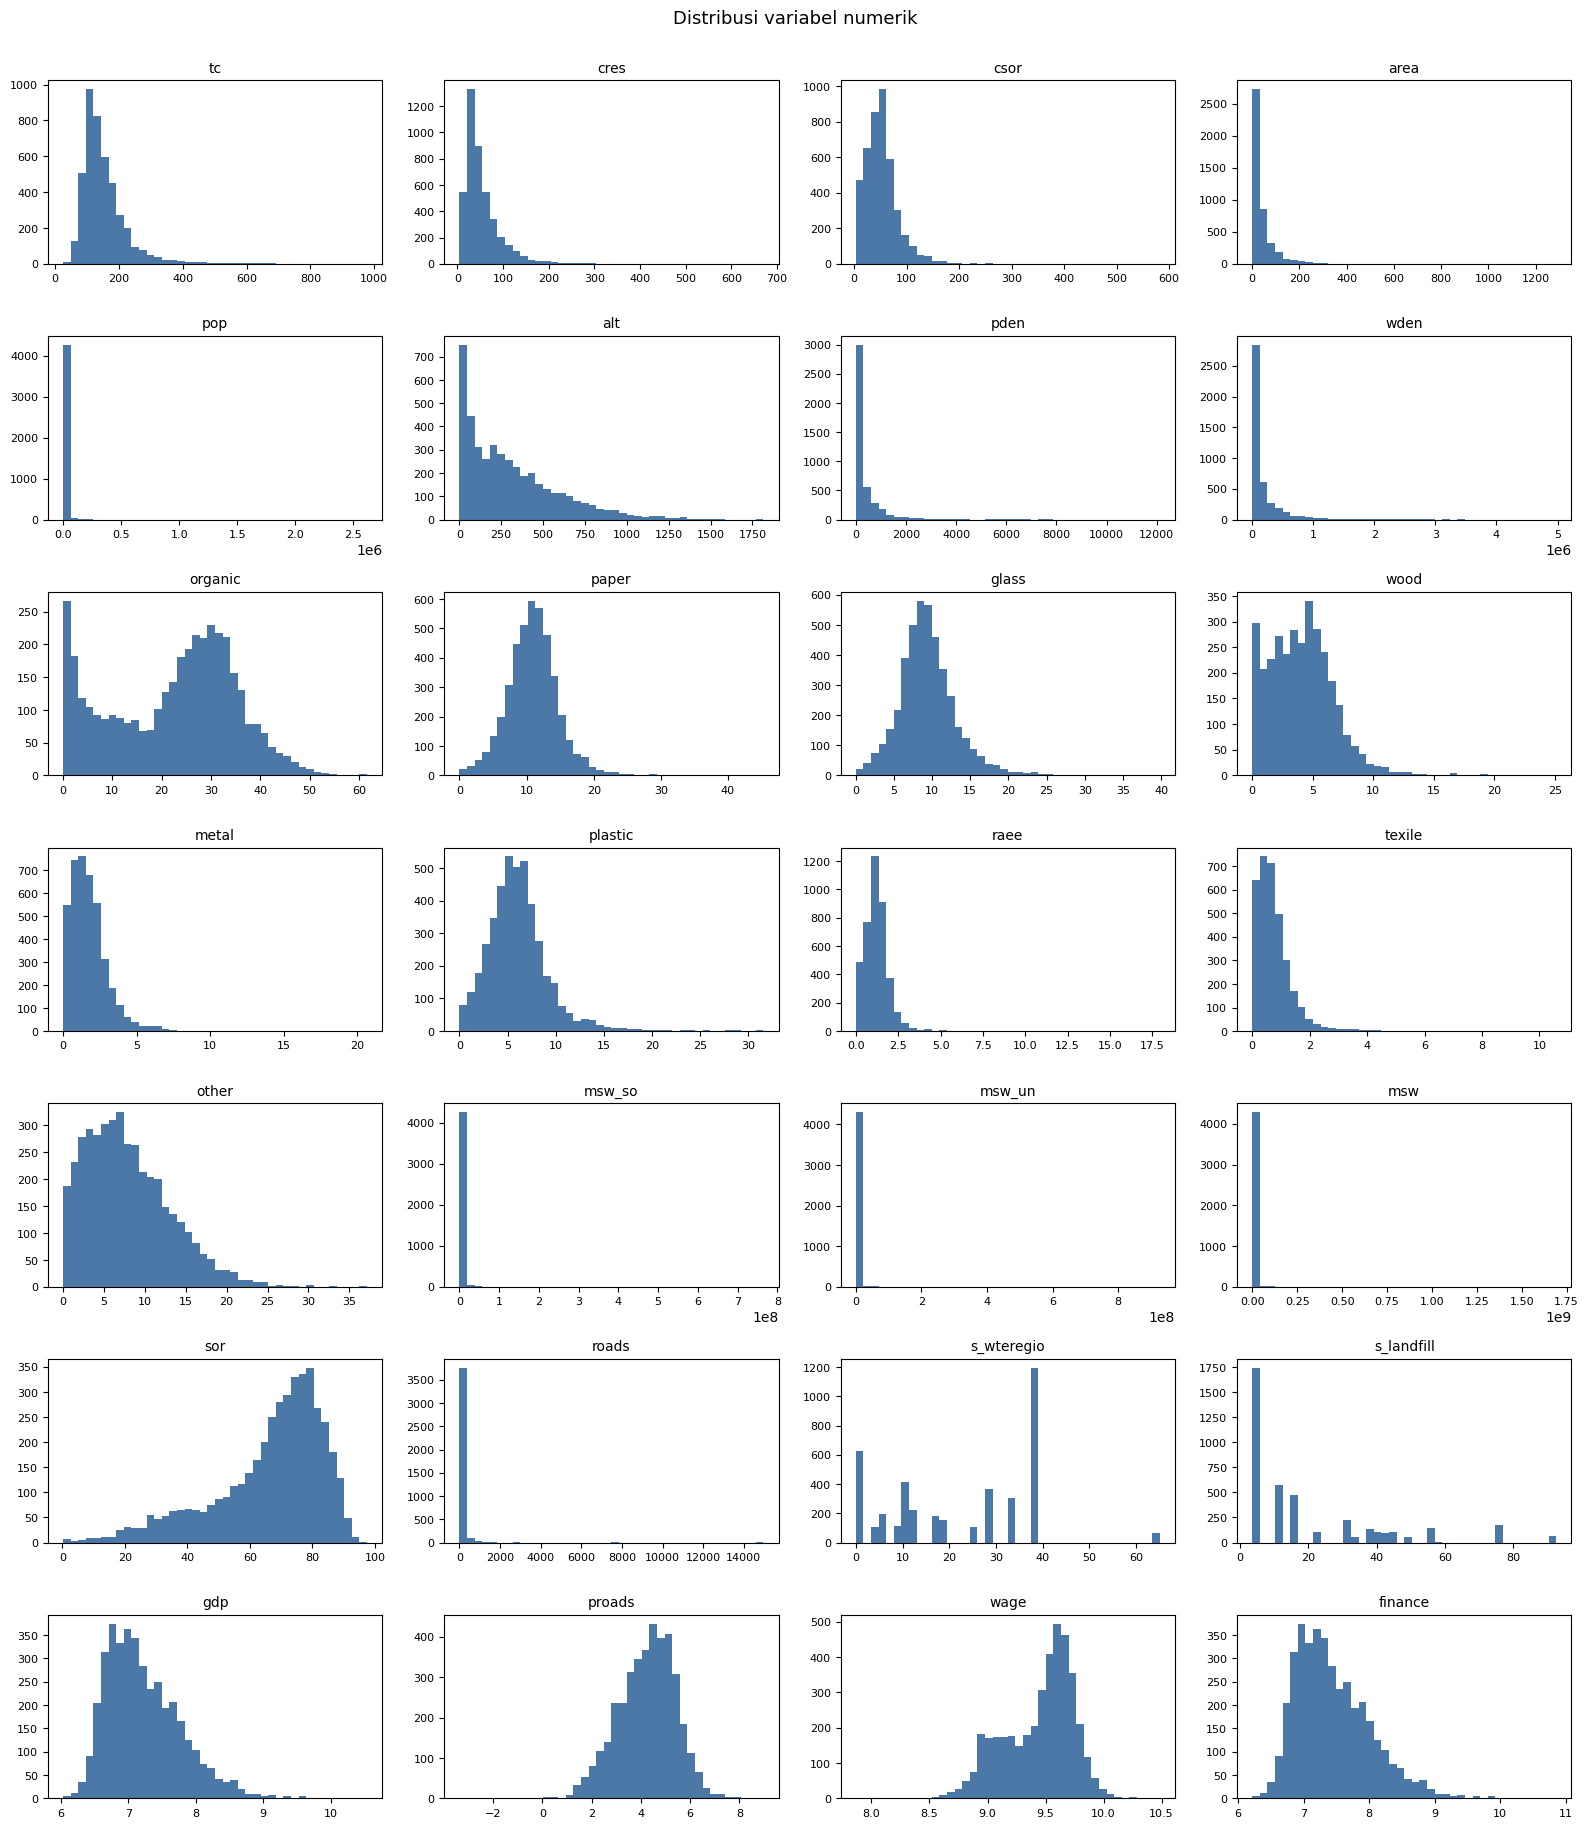

In [16]:
n = len(kolom_numerik)
n_col = 4
n_row = int(np.ceil(n / n_col))
fig, axes = plt.subplots(n_row, n_col, figsize=(16, 2.6 * n_row))
for ax, c in zip(axes.ravel(), kolom_numerik):
    ax.hist(df[c].dropna(), bins=40, color="#4C78A8")
    ax.set_title(c, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.suptitle("Distribusi variabel numerik", y=1.002, fontsize=13)
plt.tight_layout()
plt.show()

### 2.2 Variabel kategorikal

Untuk setiap variabel kategorikal dihitung: jumlah kategori, frekuensi tiap kategori, serta kategori dominan dan kategori sangat jarang.

**Definisi yang dipakai di notebook ini** (bisa diubah di parameter di bawah):
- **Dominan**: kategori dengan frekuensi tertinggi, dan dianggap *sangat dominan* bila ≥ 80% data.
- **Sangat jarang**: kategori dengan proporsi < 1% dari total baris.

In [17]:
AMBANG_JARANG = 0.01      # < 1% dianggap sangat jarang
AMBANG_DOMINAN = 0.80     # >= 80% dianggap sangat dominan

def tabel_frekuensi(data, kolom):
    vc = data[kolom].value_counts(dropna=False)
    out = pd.DataFrame({"frekuensi": vc, "persen": vc / len(data) * 100})
    out.index = out.index.map(lambda x: "(kosong/NaN)" if pd.isna(x) else x)
    out.index.name = kolom
    return out

def fmt(x):
    # tampilkan 3.0 sebagai 3, tetapi 1.5 tetap 1.5
    return int(x) if isinstance(x, (float, np.floating)) and float(x).is_integer() else x

def ringkasan_kategorikal(data, kolom_list):
    baris = []
    for c in kolom_list:
        vc = data[c].value_counts(dropna=True)
        prop = vc / vc.sum()
        jarang = prop[prop < AMBANG_JARANG]
        baris.append({
            "variabel": c,
            "n_kategori": data[c].nunique(),
            "n_kosong": int(data[c].isna().sum()),
            "kategori_dominan": fmt(vc.index[0]),
            "frek_dominan": int(vc.iloc[0]),
            "persen_dominan": prop.iloc[0] * 100,
            "sangat_dominan": prop.iloc[0] >= AMBANG_DOMINAN,
            "kategori_paling_jarang": fmt(vc.index[-1]),
            "frek_paling_jarang": int(vc.iloc[-1]),
            "n_kategori_jarang(<1%)": len(jarang),
        })
    return pd.DataFrame(baris).set_index("variabel")

ringkasan_kategorikal(df, kolom_kategorikal)

,n_kategori,n_kosong,kategori_dominan,frek_dominan,persen_dominan,sangat_dominan,kategori_paling_jarang,frek_paling_jarang,n_kategori_jarang(<1%)
variabel,,,,,,,,,
region,20,0,Lombardia,1230,28.334,False,Valle_d'Aosta,1,1
province,102,0,Bergamo,218,5.022,False,Aosta,1,62
fee,2,0,STANDARD,3784,87.169,True,PAYT,557,0
isle,2,6,0,4313,99.493,True,1,22,1
sea,2,6,0,3605,83.160,True,1,730,0
d_fee,2,0,0,3784,87.169,True,1,557,0
sample,2,0,1,2374,54.688,False,0,1967,0
urb,3,6,3,2349,54.187,False,1,225,0
geo,4,285,3,2359,58.161,False,1.500,3,1


#### Frekuensi tiap kategori: variabel dengan sedikit kategori

In [18]:
for c in ["fee", "d_fee", "sample", "isle", "sea", "urb", "geo"]:
    print(f"=== {c}: {kamus[c]} ===")
    display(tabel_frekuensi(df, c))
    print()

=== fee: fee scheme ===


,frekuensi,persen
fee,,
STANDARD,3784,87.169
PAYT,557,12.831



=== d_fee: dmmy PAYT ===


,frekuensi,persen
d_fee,,
0,3784,87.169
1,557,12.831



=== sample: Reg with PAYT ===


,frekuensi,persen
sample,,
1,2374,54.688
0,1967,45.312


... (4 outputs left out)


=== urb: urbanization index (1 low, 3 high) ===


,frekuensi,persen
urb,,
3.000,2349,54.112
2.000,1761,40.567
1.000,225,5.183
(kosong/NaN),6,0.138



=== geo: 1 South, 2 Center, 3 North ===


,frekuensi,persen
geo,,
3.000,2359,54.342
1.000,1178,27.137
2.000,516,11.887
(kosong/NaN),285,6.565
1.500,3,0.069


#### Frekuensi tiap kategori: `region` (20 kategori)

In [19]:
tabel_frekuensi(df, "region")

,frekuensi,persen
region,,
Lombardia,1230,28.334
Campania,405,9.330
Emilia_Romagna,308,7.095
Veneto,265,6.105
Toscana,231,5.321
Sicilia,212,4.884
Lazio,188,4.331
Friuli_Venezia_Giulia,183,4.216
Liguria,179,4.123


#### Frekuensi tiap kategori: `province` (kardinalitas tinggi)

Karena jumlah kategorinya banyak, ditampilkan 10 provinsi terbanyak dan 10 paling sedikit, serta daftar kategori yang sangat jarang.

In [20]:
freq_prov = tabel_frekuensi(df, "province")
print(f"Jumlah provinsi: {len(freq_prov)}")
print("\n10 provinsi dengan baris terbanyak:")
display(freq_prov.head(10))
print("10 provinsi dengan baris tersedikit:")
display(freq_prov.tail(10))

jarang_prov = freq_prov[freq_prov["persen"] < AMBANG_JARANG * 100]
print(f"Provinsi sangat jarang (< {AMBANG_JARANG:.0%} data): {len(jarang_prov)} dari {len(freq_prov)}")

Jumlah provinsi: 102

10 provinsi dengan baris terbanyak:


,frekuensi,persen
province,,
Bergamo,218,5.022
Brescia,172,3.962
Milano,131,3.018
Bolzano,115,2.649
Salerno,112,2.580
Como,106,2.442
Cremona,102,2.350
Udine,102,2.350
Varese,99,2.281


10 provinsi dengan baris tersedikit:


,frekuensi,persen
province,,
Barletta-Andria-Trani,7,0.161
Trieste,6,0.138
Prato,6,0.138
Oristano,5,0.115
Caltanissetta,3,0.069
Asti,2,0.046
Treviso,1,0.023
Vercelli,1,0.023
Torino,1,0.023


Provinsi sangat jarang (< 1% data): 62 dari 102


#### Visualisasi frekuensi kategorikal

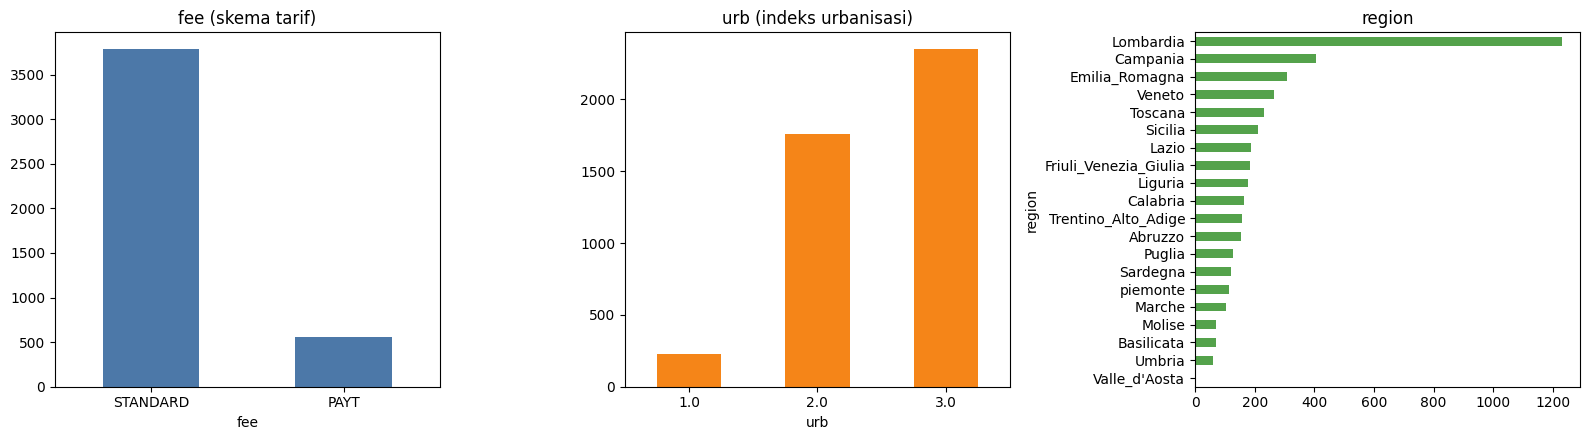

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df["fee"].value_counts().plot.bar(ax=axes[0], color="#4C78A8", rot=0)
axes[0].set_title("fee (skema tarif)")

df["urb"].value_counts().sort_index().plot.bar(ax=axes[1], color="#F58518", rot=0)
axes[1].set_title("urb (indeks urbanisasi)")

df["region"].value_counts().plot.barh(ax=axes[2], color="#54A24B")
axes[2].invert_yaxis()
axes[2].set_title("region")

plt.tight_layout()
plt.show()

### 2.3 Variabel teks (`name`) dan identifier (`istat`)

Variabel teks tidak punya "mean" atau "median", jadi diperiksa dari sisi keunikan dan panjang teks.

In [22]:
nama = df["name"]
print(f"Jumlah nilai terisi : {nama.notna().sum():,}")
print(f"Jumlah nilai unik   : {nama.nunique():,}")
print(f"Nama yang muncul lebih dari sekali:")
dup = nama[nama.duplicated(keep=False)].dropna()
display(df.loc[dup.index, ["name", "province", "region", "istat"]].sort_values("name"))

Jumlah nilai terisi : 4,335
Jumlah nilai unik   : 4,333
Nama yang muncul lebih dari sekali:


,name,province,region,istat
1175,Castro,Lecce,Puglia,75096
1875,Castro,Bergamo,Lombardia,16065
3498,Peglio,Pesaro e Urbino,Marche,41041
3778,Peglio,Como,Lombardia,13178


In [23]:
# Variabel 'istat' : identifier, bukan besaran numerik
print("istat unik   :", df["istat"].is_unique)
print("istat min/max:", df["istat"].min(), "/", df["istat"].max())

istat unik   : True
istat min/max: 1272 / 111107


---
## 3. EDA (Exploratory Data Analysis)

Bagian 1 dan 2 di atas adalah *data understanding* dasar: struktur data dan statistik deskriptif. Bagian 3 ini adalah **EDA**, yaitu penelusuran yang lebih dalam untuk menemukan anomali, pola, dan hubungan antarvariabel sebelum tahap clustering.

Bagian ini terdiri dari dua bagian:

| Bagian | Isi |
|---|---|
| **3.1 EDA dasar** | Kualitas dan konsistensi data, pola missing value, distribusi dan outlier, perbandingan kelompok, korelasi, pengaruh region, serta struktur multivariat (PCA dan statistik Hopkins). |
| **3.2 Pengujian hipotesis spesifik** | Pendalaman untuk menguji dugaan tertentu yang muncul dari EDA dasar. Setiap sub-bagian membahas satu dugaan. |

Hal yang sudah ada di bagian 1 dan 2 tidak diulang di sini: ukuran dan tipe data, tabel missing value per variabel, statistik deskriptif numerik, histogram distribusi rentang penuh, dan tabel frekuensi kategorikal. Variabel `df` dan pengelompokan variabel (`kelompok_numerik`) dari bagian sebelumnya langsung dipakai.

### 3.0 Persiapan EDA

In [24]:
# Library tambahan untuk EDA (pandas, numpy, matplotlib, dan df sudah dimuat di bagian 0)
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import statsmodels.formula.api as smf

# Bagian 0 mengubah format angka dan jumlah baris tampilan pandas.
pd.reset_option("display.float_format")
pd.reset_option("display.max_rows")

# Daftar kolom komposisi sampah terpilah (sama dengan kelompok di bagian 1.5)
kol_komp = list(kelompok_numerik["Komposisi sampah terpilah (%)"])
assert kol_komp == ["organic", "paper", "glass", "wood", "metal", "plastic", "raee", "texile", "other"]

### 3.1 EDA dasar

Pemeriksaan umum sebelum clustering: kualitas data, missing value, distribusi, outlier, hubungan antarvariabel, dan struktur multivariat.

#### 3.1.1 Identitas baris dan konsistensi variabel

Memeriksa baris duplikat dan baris tanpa nama, hubungan antara `fee`, `d_fee`, dan `sample`, serta apakah variabel turunan (`msw`, `sor`, `pden`, `wden`) konsisten dengan variabel asalnya. Ukuran data, tipe data, dan keunikan `istat` sudah dibahas di bagian 1.

In [25]:
# Bentuk data, tipe data, dan keunikan istat sudah ada di bagian 1; di sini hanya cek duplikat baris
print("Duplikat baris penuh      :", df.duplicated().sum())
print("Duplikat (name + province):", df.duplicated(subset=["name", "province"]).sum())

Duplikat baris penuh      : 0
Duplikat (name + province): 2


In [26]:
# Baris yang duplikat berdasarkan (name, province), keep=False agar semua anggota duplikat tampil
dup = df[df.duplicated(subset=["name", "province"], keep=False)]
print(dup[["region", "province", "name", "istat", "pop"]])

# Baris dengan nama kosong, dan apakah kolom geografinya ikut kosong
nama_kosong = df[df["name"].isna()]
print(nama_kosong[["region", "province", "name", "istat", "pop", "area", "alt", "urb"]])

      region province name  istat   pop
4336  Veneto  Vicenza  NaN  24125  5031
4339  Veneto  Vicenza  NaN  24127  4683
4340  Veneto  Vicenza  NaN  24126  5986
         region province name  istat    pop  area  alt  urb
4335  Lombardia   Milano  NaN  15251   5754   NaN  NaN  NaN
4336     Veneto  Vicenza  NaN  24125   5031   NaN  NaN  NaN
4337  Lombardia   Varese  NaN  12143   2623   NaN  NaN  NaN
4338     Veneto  Belluno  NaN  25074  13515   NaN  NaN  NaN
4339     Veneto  Vicenza  NaN  24127   4683   NaN  NaN  NaN
4340     Veneto  Vicenza  NaN  24126   5986   NaN  NaN  NaN


In [27]:
print(pd.crosstab(df["fee"], df["d_fee"]), "\n")
print(pd.crosstab(df["d_fee"], df["sample"]), "\n")

d_fee        0    1
fee                
PAYT         0  557
STANDARD  3784    0 

sample     0     1
d_fee             
0       1948  1836
1         19   538 



In [28]:
cek = pd.DataFrame({
    "msw - (msw_so + msw_un)": df["msw"] - (df["msw_so"] + df["msw_un"]),
    "sor - 100*msw_so/msw":    df["sor"] - 100 * df["msw_so"] / df["msw"],
    "pden - pop/area":         df["pden"] - df["pop"] / df["area"],
    "wden - msw/area":         df["wden"] - df["msw"] / df["area"],
})
print(cek.abs().describe().T[["count", "mean", "max"]])

                          count          mean           max
msw - (msw_so + msw_un)  4341.0  20237.986462  1.070164e+07
sor - 100*msw_so/msw     4341.0      0.002644  3.396587e-01
pden - pop/area          4335.0      0.000009  2.892242e-04
wden - msw/area          4335.0      0.004099  1.831845e-01


#### 3.1.2 Anomali awal

Tiga anomali dari pemeriksaan sebelumnya diselidiki lebih lanjut: (1) `msw` tidak sama dengan `msw_so + msw_un`, (2) nilai `geo = 1.5` dan `geo` yang kosong, dan (3) kota PAYT dengan `sample = 0`. Sel terakhir menindaklanjuti arah selisih `msw`, hubungannya dengan ukuran kota, dan apakah `geo` konstan per provinsi.

In [29]:
selisih = df["msw"] - (df["msw_so"] + df["msw_un"])
tidak_cocok = df[selisih.abs() > 1]   # toleransi 1 kg

print("Baris tidak cocok:", len(tidak_cocok), "dari", len(df))
print((selisih[tidak_cocok.index] / tidak_cocok["msw"]).abs().describe())

kolom = ["region", "province", "name", "pop", "msw", "msw_so", "msw_un", "sor"]
tampil = tidak_cocok.assign(selisih=selisih[tidak_cocok.index])
print(tampil.sort_values("selisih", key=abs, ascending=False)[kolom + ["selisih"]].head(10))

Baris tidak cocok: 1039 dari 4341
count    1.039000e+03
mean     3.014756e-02
std      3.215776e-02
min      5.655148e-07
25%      1.012915e-02
50%      2.179752e-02
75%      3.758662e-02
max      2.677384e-01
dtype: float64
                     region         province           name     pop        msw      msw_so     msw_un    sor     selisih
311                 Sicilia          Palermo        Palermo  657561  383636800  66707080.0  306228080  17.39  10701640.0
17    Friuli_Venezia_Giulia          Trieste        Trieste  202123   98664830  41642307.0   53991539  42.21   3030984.0
1838    Trentino_Alto_Adige           Trento         Trento  114198   56682920  46785040.0    8519580  82.54   1378300.0
3365                 Umbria          Perugia        Perugia  162449   95243896  67699101.0   26171583  71.08   1373212.0
135                Sardegna         Cagliari       Cagliari  149883   72649582  46722732.0   24626310  64.31   1300540.0
1355  Friuli_Venezia_Giulia            Udine     

In [30]:
print(df.loc[df["geo"] == 1.5, ["region", "province", "name", "istat", "pop"]], "\n")
print(df.loc[df["geo"].isna(), "region"].value_counts(), "\n")
print(df.groupby("region")["geo"].agg(lambda s: sorted(s.dropna().unique())))

       region         province                   name  istat   pop
2310   Marche  Pesaro e Urbino       Terre Roveresche  41070  5624
3716  Toscana          Pistoia  San Marcello Piteglio  47024  8469
3845  Toscana          Pistoia     Abetone Cutigliano  47023  2248 

region
Campania                 38
Sicilia                  36
Lombardia                34
Lazio                    27
Abruzzo                  24
Calabria                 24
Puglia                   17
Basilicata               14
Sardegna                 11
Toscana                  10
Veneto                    9
Umbria                    8
Liguria                   8
piemonte                  7
Molise                    6
Marche                    6
Emilia_Romagna            4
Friuli_Venezia_Giulia     1
Trentino_Alto_Adige       1
Name: count, dtype: int64 

region
Abruzzo                            [1.0]
Basilicata                         [1.0]
Calabria                           [1.0]
Campania                         

In [31]:
print(df.groupby("region")["sample"].nunique().value_counts(), "\n")
print(df.groupby("region")[["d_fee", "sample"]].mean().round(2), "\n")
print(df.loc[(df["d_fee"] == 1) & (df["sample"] == 0), ["region", "province", "name"]])

sample
1    20
Name: count, dtype: int64 

                       d_fee  sample
region                              
Abruzzo                 0.03     0.0
Basilicata              0.00     0.0
Calabria                0.00     0.0
Campania                0.00     0.0
Emilia_Romagna          0.25     1.0
Friuli_Venezia_Giulia   0.18     1.0
Lazio                   0.01     0.0
Liguria                 0.03     0.0
Lombardia               0.14     1.0
Marche                  0.01     0.0
Molise                  0.00     0.0
Puglia                  0.00     0.0
Sardegna                0.00     0.0
Sicilia                 0.00     0.0
Toscana                 0.10     1.0
Trentino_Alto_Adige     0.83     1.0
Umbria                  0.03     0.0
Valle_d'Aosta           0.00     0.0
Veneto                  0.38     1.0
piemonte                0.04     0.0 

        region   province                       name
40     Liguria  La Spezia                  La Spezia
138    Sicilia    Messina       San

In [32]:
# msw lebih besar atau lebih kecil dari so+un? Dan seberapa sering menurut ukuran kota?
selisih = df["msw"] - (df["msw_so"] + df["msw_un"])
print("msw > so+un:", (selisih > 1).sum(), "| msw < so+un:", (selisih < -1).sum())

kel_pop = pd.cut(df["pop"], [0, 5000, 20000, 50000, np.inf])
print((selisih.abs() > 1).groupby(kel_pop, observed=True).mean().round(3))

# Apakah geo konstan per province?
print(df.groupby("province")["geo"].nunique().value_counts())

msw > so+un: 1039 | msw < so+un: 0
pop
(0.0, 5000.0]         0.250
(5000.0, 20000.0]     0.222
(20000.0, 50000.0]    0.208
(50000.0, inf]        0.257
dtype: float64
geo
1    87
2    15
Name: count, dtype: int64


#### 3.1.3 Pola missing value

Jumlah dan persentase missing per variabel sudah ada di bagian 1.3, sehingga di sini difokuskan pada polanya: kombinasi kolom yang kosong bersamaan, sebaran per region, dan hubungannya dengan selisih antara `sor` dan jumlah komposisi sampah (`gap = sor - jumlah komposisi`).

In [33]:
# Jumlah missing per variabel sudah ada di bagian 1.3; di sini dilihat kombinasi kolom yang kosong bersamaan
kol_miss = df.columns[df.isna().any()].tolist()
pola = df[kol_miss].isna()
ringkas = pola.apply(lambda r: ", ".join(r.index[r]), axis=1).value_counts()
print(ringkas.head(15))

                                                                          2017
texile                                                                     438
wood                                                                       365
organic                                                                    267
wood, texile                                                               134
geo, roads, s_wteregio, s_landfill, gdp, proads, wage, finance              93
wood, raee                                                                  66
organic, texile                                                             48
wood, roads, gdp, proads, finance                                           38
wood, raee, texile                                                          37
wood, geo, roads, s_wteregio, s_landfill, gdp, proads, wage, finance        34
organic, wood, texile                                                       32
wood, metal                                         

In [34]:
kol_sosek = ["geo", "roads", "proads", "gdp", "finance", "wage", "s_wteregio", "s_landfill"]

pd.set_option("display.width", 250)
print(df[kol_sosek].isna().groupby(df["region"]).mean().round(2), "\n")
print(df[kol_komp].isna().groupby(df["region"]).mean().round(2))

                        geo  roads  proads   gdp  finance  wage  s_wteregio  s_landfill
region                                                                                 
Abruzzo                0.15   0.17    0.17  0.16     0.16  0.15        0.15        0.15
Basilicata             0.20   0.20    0.20  0.20     0.20  0.20        0.20        0.20
Calabria               0.15   0.17    0.17  0.15     0.15  0.15        0.15        0.15
Campania               0.09   0.14    0.14  0.10     0.10  0.09        0.09        0.09
Emilia_Romagna         0.01   0.04    0.04  0.03     0.03  0.01        0.01        0.01
Friuli_Venezia_Giulia  0.01   0.03    0.03  0.02     0.02  0.01        0.01        0.01
Lazio                  0.14   0.16    0.16  0.15     0.15  0.14        0.14        0.14
Liguria                0.04   0.07    0.07  0.06     0.06  0.04        0.04        0.04
Lombardia              0.03   0.04    0.04  0.03     0.03  0.03        0.03        0.03
Marche                 0.06   0.

In [35]:
komp = df[kol_komp]
uji = pd.DataFrame({
    "n_missing_komp": komp.isna().sum(axis=1),
    "gap": df["sor"] - komp.sum(axis=1),   # sum() mengabaikan NaN
})
print(uji.groupby("n_missing_komp")["gap"].describe().round(2))

                 count  mean    std  min   25%   50%    75%    max
n_missing_komp                                                    
0               2210.0  5.61  11.12 -0.0  0.00  0.00   0.29  46.63
1               1326.0  8.95  14.70 -0.0  0.00  0.06  20.48  50.21
2                496.0  3.40   9.61 -0.0  0.00  0.07   0.27  48.31
3                199.0  2.82   8.48 -0.0  0.00  0.10   0.43  37.65
4                 73.0  1.75   6.91 -0.0  0.00  0.08   0.30  36.05
5                 24.0  0.15   0.23 -0.0  0.01  0.08   0.19   1.04
6                  8.0  0.41   0.68 -0.0  0.00  0.09   0.45   1.92
7                  2.0  0.04   0.06  0.0  0.02  0.04   0.06   0.08
8                  3.0  0.08   0.14  0.0  0.00  0.00   0.13   0.25


**Pengecekan penutup analisis missing:** hubungan kekosongan `geo`, `roads`, dan `gdp`; apakah `s_wteregio` dan `s_landfill` konstan per region dan provinsi; serta selisih `gap` menurut region dan menurut kategori komposisi yang hilang.

In [36]:
m_geo, m_roads, m_gdp = df["geo"].isna(), df["roads"].isna(), df["gdp"].isna()
print(pd.crosstab([m_geo, m_gdp], m_roads, rownames=["geo NaN", "gdp NaN"], colnames=["roads NaN"]), "\n")
print(df.loc[df["name"].isna(), ["geo", "wage", "roads", "gdp"]].isna().sum())

roads NaN        False  True 
geo NaN gdp NaN              
False   False     3898     57
        True         0    101
True    True         0    285 

geo      6
wage     6
roads    6
gdp      6
dtype: int64


In [37]:
for lvl in ["region", "province"]:
    print(lvl)
    print(df.groupby(lvl)[["s_wteregio", "s_landfill"]].nunique().describe().loc[["min", "mean", "max"]].round(1), "\n")

region
      s_wteregio  s_landfill
min          1.0         1.0
mean         1.0         1.0
max          1.0         1.0 

province
      s_wteregio  s_landfill
min          1.0         1.0
mean         1.0         1.0
max          1.0         1.0 



In [38]:
gap = df["sor"] - df[kol_komp].sum(axis=1)
lengkap = df[kol_komp].notna().all(axis=1)

d = df.loc[lengkap].assign(gap=gap[lengkap])
print("gap > 1:", (d["gap"] > 1).mean().round(3), "| gap > 5:", (d["gap"] > 5).mean().round(3), "\n")
print((d["gap"] > 5).groupby(d["region"]).mean().round(2))

gap > 1: 0.224 | gap > 5: 0.218 

region
Abruzzo                  0.22
Basilicata               0.03
Calabria                 0.16
Campania                 0.57
Emilia_Romagna           0.38
Friuli_Venezia_Giulia    0.12
Lazio                    0.34
Liguria                  0.15
Lombardia                0.11
Marche                   0.10
Molise                   0.00
Puglia                   0.55
Sardegna                 0.59
Sicilia                  0.49
Toscana                  0.42
Trentino_Alto_Adige      0.02
Umbria                   0.30
Veneto                   0.13
piemonte                 0.02
Name: gap, dtype: float64


In [39]:
satu = df[df[kol_komp].isna().sum(axis=1) == 1].copy()
satu["kat_hilang"] = satu[kol_komp].isna().idxmax(axis=1)
satu["gap"] = satu["sor"] - satu[kol_komp].sum(axis=1)

print(satu.groupby("kat_hilang")["gap"].agg(
    n="count", median="median", rata2="mean", persen_gap_gt5=lambda s: (s > 5).mean()
).round(2))

              n  median  rata2  persen_gap_gt5
kat_hilang                                    
glass         8    0.00   4.52            0.12
metal        31    0.01   3.55            0.16
organic     279   32.09  28.36            0.86
other        17    0.15   0.26            0.00
plastic       7    0.04   0.05            0.00
raee         34    0.01   2.78            0.09
texile      487    0.00   1.99            0.08
wood        463    0.04   5.93            0.20


#### 3.1.4 Distribusi univariat dan nilai tidak wajar

Tabel skewness, statistik dasar, dan histogram rentang penuh sudah ada di bagian 2.1. Di sini ditambahkan persentil ekstrem (P1 dan P99), histogram 6×5 untuk 26 variabel numerik yang hanya menampilkan rentang P1 sampai P99 (jumlah data di bawah P1 dan di atas P99 ditulis di judul tiap panel) agar bentuk sebaran inti terlihat tanpa terdistorsi ekor ekstrem, lalu validasi rentang nilai (persentase di luar 0 sampai 100, nilai nol atau negatif, dan `msw` per kapita).

In [40]:
kol_num = ["tc", "cres", "csor", "area", "pop", "alt", "pden", "wden",
           "msw", "msw_so", "msw_un", "sor",
           "organic", "paper", "glass", "wood", "metal", "plastic", "raee", "texile", "other",
           "roads", "proads", "gdp", "wage", "finance"]

# kol_num (26 variabel numerik, tanpa s_wteregio dan s_landfill) dipakai juga di bagian 3.1.5
# Statistik dasar dan skewness sudah ada di bagian 2.1; di sini hanya persentil ekstrem P1 dan P99
desk = df[kol_num].describe(percentiles=[.01, .25, .5, .75, .99]).T
print(desk[["1%", "99%"]].round(2).to_string())

               1%          99%
tc          60.47       451.52
cres        10.47       213.52
csor         5.14       160.00
area         2.16       252.75
pop        203.20     94238.20
alt          3.00      1209.66
pden         9.22      3529.87
wden      3177.27   1767870.87
msw      75438.00  54674407.40
msw_so   27710.00  31486657.60
msw_un   22268.00  20224984.00
sor         14.22        90.84
organic      0.26        47.35
paper        1.91        21.82
glass        1.68        21.04
wood         0.00        12.07
metal        0.00         6.37
plastic      0.48        17.20
raee         0.00         3.67
texile       0.00         3.21
other        0.26        22.37
roads        4.00       832.24
proads       1.52         6.70
gdp          6.34         8.76
wage         8.73         9.98
finance      6.53         9.02


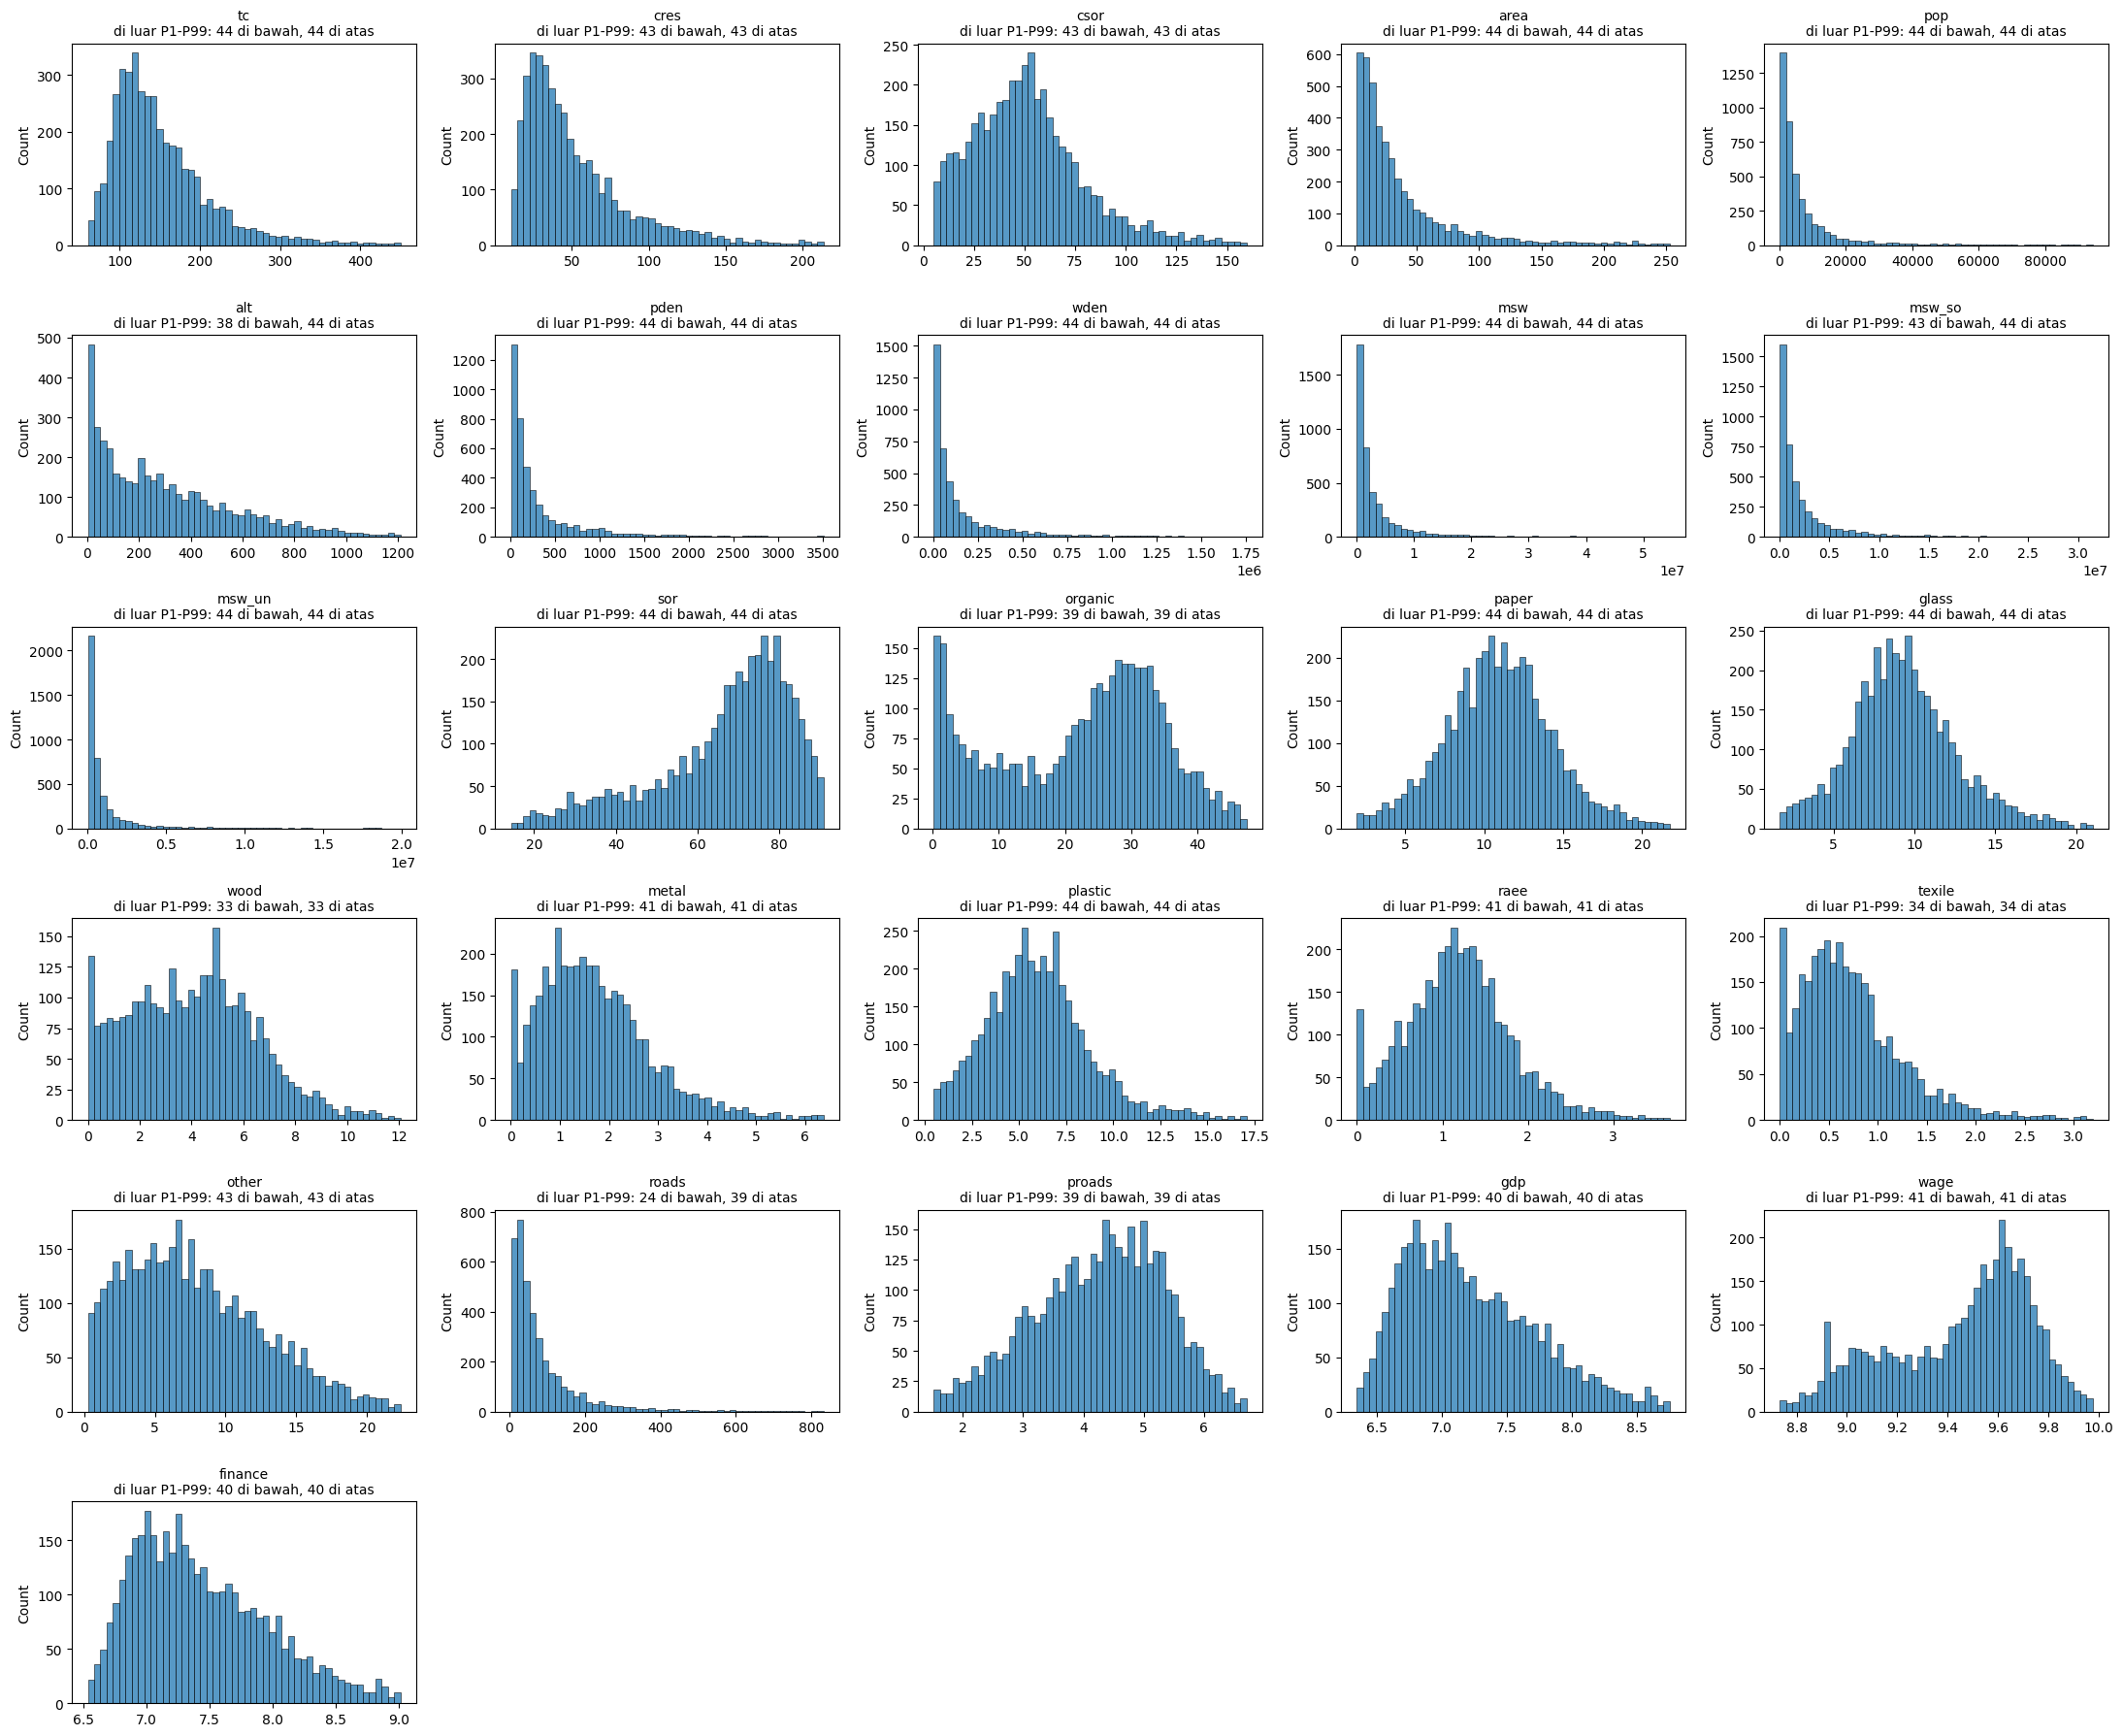

In [41]:
# Histogram pada rentang P1 sampai P99 (histogram rentang penuh ada di bagian 2.1).
# Ekor ekstrem dibuang dari gambar supaya bentuk sebaran inti terlihat; jumlah data yang dibuang ada di judul.
fig, axes = plt.subplots(6, 5, figsize=(22, 18))
for ax, kol in zip(axes.ravel(), kol_num):
    s = df[kol].dropna()
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    inti = s[(s >= lo) & (s <= hi)]
    sns.histplot(inti, bins=50, ax=ax)
    ax.set_title(f"{kol}\ndi luar P1-P99: {(s < lo).sum()} di bawah, {(s > hi).sum()} di atas", fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[len(kol_num):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [42]:
kol_persen = ["sor", "organic", "paper", "glass", "wood", "metal", "plastic", "raee", "texile", "other"]
kol_positif = ["tc", "cres", "csor", "area", "pop", "pden", "wden", "msw", "msw_so", "msw_un", "roads"]

print("Persentase < 0  :\n", (df[kol_persen] < 0).sum()[lambda s: s > 0], "\n")
print("Persentase > 100:\n", (df[kol_persen] > 100).sum()[lambda s: s > 0], "\n")
print("Nilai <= 0 pada kolom yang seharusnya positif:\n", (df[kol_positif] <= 0).sum()[lambda s: s > 0], "\n")
print("Altitude < 0:", (df["alt"] < 0).sum())

msw_pc = df["msw"] / df["pop"]   # kg per kapita, hanya untuk eksplorasi
print("\nmsw per kapita (kg):")
print(msw_pc.describe(percentiles=[.01, .05, .5, .95, .99]).round(1))

Persentase < 0  :
 Series([], dtype: int64) 

Persentase > 100:
 Series([], dtype: int64) 

Nilai <= 0 pada kolom yang seharusnya positif:
 Series([], dtype: int64) 

Altitude < 0: 0

msw per kapita (kg):
count    4341.0
mean      458.9
std       176.4
min       111.6
1%        192.3
5%        246.5
50%       435.8
95%       767.6
99%      1073.6
max      2971.1
dtype: float64


#### 3.1.5 Baris ekstrem, nilai nol, dan outlier

Menelusuri baris dengan nilai ekstrem (`msw_so`, `msw_pc`, `proads`, `tc`, `sor`), memeriksa nilai nol dan nilai `organic` yang sangat rendah, lalu menghitung outlier dengan aturan IQR (1,5 × IQR) beserta boxplot.

In [43]:
tmp = df.assign(msw_pc=df["msw"] / df["pop"], ln_pop_roads=np.log(df["pop"] / df["roads"]))

print(df.nsmallest(8, "msw_so")[["region", "province", "name", "pop", "msw", "msw_so", "sor"]], "\n")

kol = ["region", "province", "name", "pop", "msw_pc", "sea", "urb", "sor"]
print(tmp.nlargest(8, "msw_pc")[kol], "\n")
print(tmp.nsmallest(8, "msw_pc")[kol], "\n")

print((tmp["proads"] - tmp["ln_pop_roads"]).abs().describe().round(3), "\n")
print(tmp.nsmallest(5, "proads")[["region", "province", "name", "pop", "roads", "proads"]])

              region  province                   name   pop     msw   msw_so    sor
4174           Lazio     Rieti             Micigliano   131  108280     0.27   0.25
2894        Calabria   Cosenza  San Pietro in Amantea   534  146520     0.50   0.34
3571           Lazio     Rieti            Concerviano   311  149160  1040.00   0.70
3825      Basilicata   Potenza     San Martino d'Agri   825  201693  3343.00   1.66
4325         Abruzzo  L'Aquila             Campotosto   586  176393  4153.00   2.35
4016      Basilicata   Potenza     San Chirico Raparo  1161  305190  5700.00   1.87
4252       Lombardia     Lecco              Morterone    34   28975  8345.00  28.80
3932  Emilia_Romagna  Piacenza              Cerignale   155   89670  8760.00   9.77 

                     region      province                       name   pop       msw_pc  sea  urb    sor
911               Lombardia       Brescia           Limone sul Garda  1151  2971.131190  0.0  3.0  62.55
23    Friuli_Venezia_Giulia     

In [44]:
print(df.nlargest(6, "tc")[["region", "province", "name", "pop", "tc", "cres", "csor"]], "\n")
print(df.nsmallest(10, "sor")[["region", "province", "name", "pop", "msw", "msw_so", "sor"]])

                     region   province                name   pop          tc        cres        csor
4330              Lombardia    Bergamo             Foppolo   202  977.419983  469.290009   57.480000
4270              Lombardia    Bergamo             Valleve   136  948.109985  197.149994   44.529999
911               Lombardia    Brescia    Limone sul Garda  1151  853.219971  285.459991  338.500000
29                  Toscana      Lucca     Forte dei Marmi  7660  823.900024  126.459999  428.239990
632                 Liguria  La Spezia         Riomaggiore  1669  809.169983  144.559998   75.430000
23    Friuli_Venezia_Giulia      Udine  Lignano Sabbiadoro  6447  742.000000  258.589996  307.170013 

          region  province                   name   pop      msw    msw_so   sor
4174       Lazio     Rieti             Micigliano   131   108280      0.27  0.25
2894    Calabria   Cosenza  San Pietro in Amantea   534   146520      0.50  0.34
3571       Lazio     Rieti            Concervian

In [45]:
print(pd.DataFrame({"nol": (df[kol_komp] == 0).sum(), "NaN": df[kol_komp].isna().sum()}), "\n")

ada = df[df["organic"].notna()]
rendah = ada["organic"] < 2
print("organic < 2:", rendah.sum(), "dari", len(ada), "\n")
print(ada.groupby(rendah)[["sor", "tc", "pop"]].median().round(1), "\n")

tab = pd.DataFrame({"rendah": ada.loc[rendah, "region"].value_counts(),
                    "total": ada["region"].value_counts()}).fillna(0).astype(int)
tab["persen"] = (tab["rendah"] / tab["total"] * 100).round(1)
print(tab.sort_values("persen", ascending=False))

         nol   NaN
organic    0   512
paper      0    25
glass      0    33
wood       0  1095
metal      0   246
plastic    0    39
raee       0   314
texile     0  1013
other      0   136 

organic < 2: 339 dari 3829 

          sor     tc      pop
organic                      
False    72.7  130.0   3181.5
True     57.6  173.1  13295.0 

                       rendah  total  persen
region                                      
Puglia                     56    102    54.9
Toscana                    56    199    28.1
Sicilia                    39    194    20.1
Campania                   76    386    19.7
Abruzzo                    14    142     9.9
Basilicata                  4     42     9.5
Lazio                      12    158     7.6
Liguria                     8    155     5.2
Sardegna                    6    116     5.2
Calabria                    7    140     5.0
piemonte                    5    103     4.9
Molise                      3     62     4.8
Lombardia                  

In [46]:
def hitung_outlier(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return pd.Series({"n": len(s),
                      "atas": (s > q3 + 1.5 * iqr).sum(),
                      "bawah": (s < q1 - 1.5 * iqr).sum()})

out = df[kol_num].apply(hitung_outlier).T
out["persen"] = ((out["atas"] + out["bawah"]) / out["n"] * 100).round(1)
print(out.to_string())

            n  atas  bawah  persen
tc       4341   209      0     4.8
cres     4289   256      0     6.0
csor     4274   149      0     3.5
area     4335   382      0     8.8
pop      4341   431      0     9.9
alt      4335    98      0     2.3
pden     4335   504      0    11.6
wden     4335   480      0    11.1
msw      4341   470      0    10.8
msw_so   4341   457      0    10.5
msw_un   4341   544      0    12.5
sor      4341     0    159     3.7
organic  3829     0      0     0.0
paper    4316    83     48     3.0
glass    4308   125     21     3.4
wood     3246    46      0     1.4
metal    4095   136      0     3.3
plastic  4302   158      0     3.7
raee     4027   116      0     2.9
texile   3328   132      0     4.0
other    4205    50      0     1.2
roads    3898   335      0     8.6
proads   3898     9     17     0.7
gdp      3955    50      0     1.3
wage     4056     1      6     0.2
finance  3955    50      0     1.3


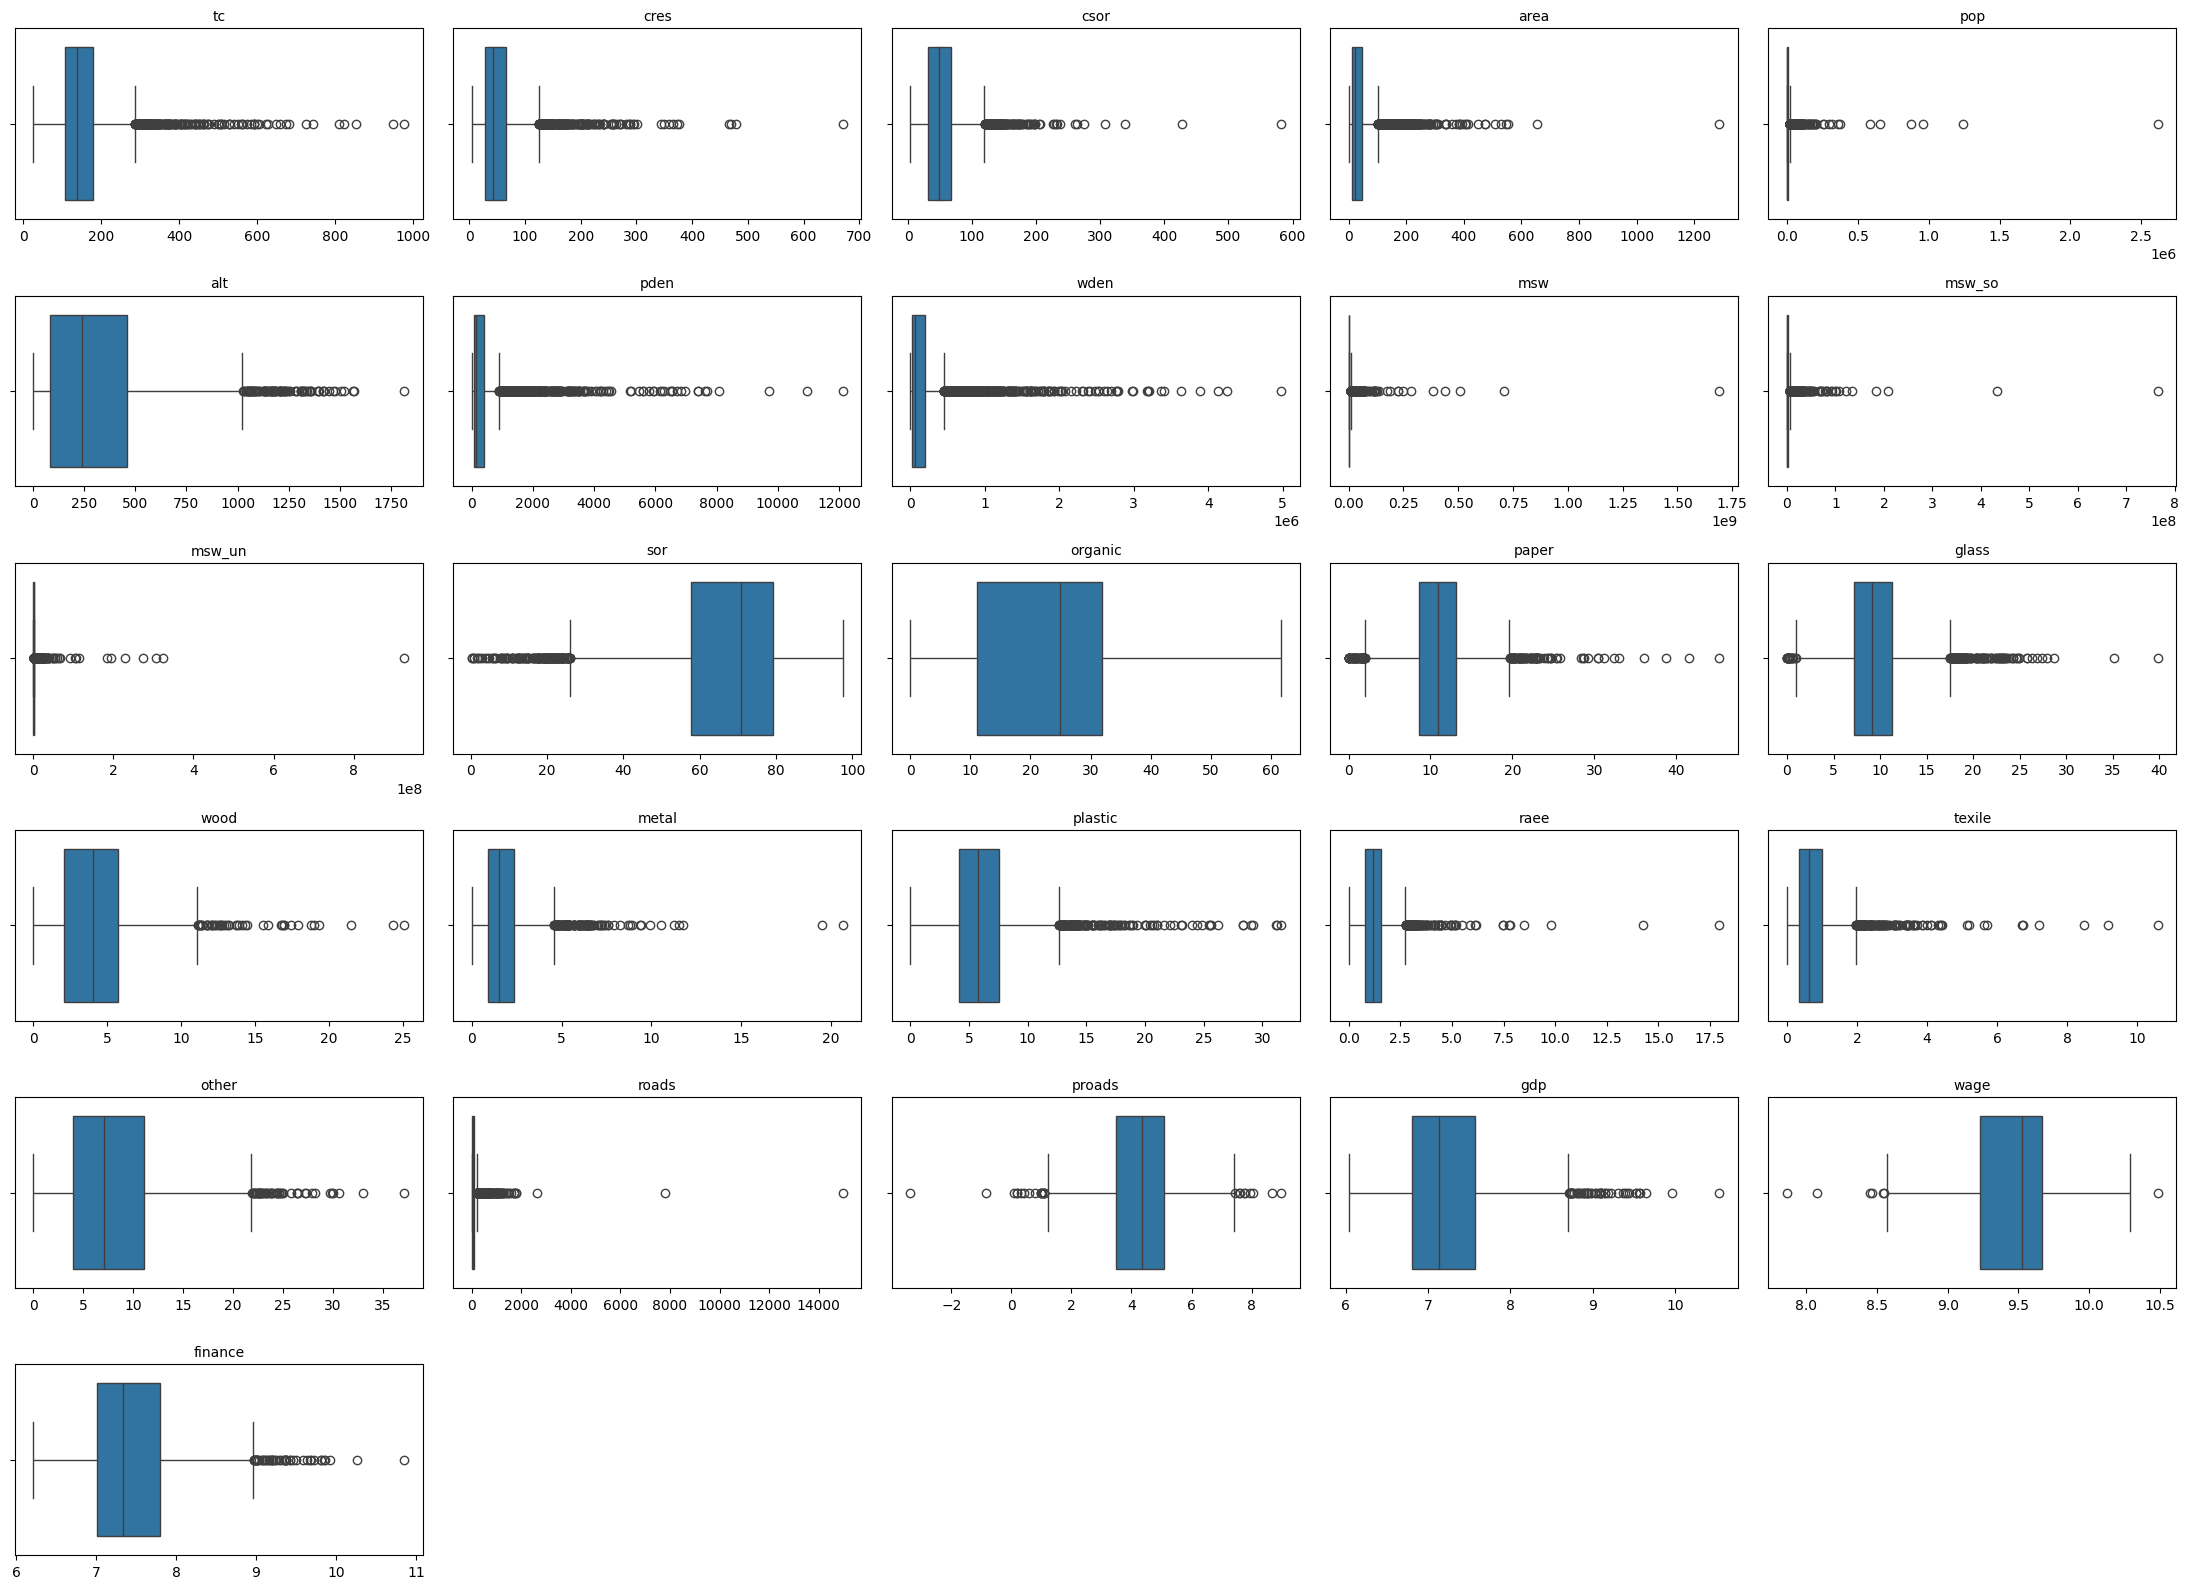

In [47]:
fig, axes = plt.subplots(6, 5, figsize=(22, 16))
for ax, k in zip(axes.ravel(), kol_num):
    sns.boxplot(x=df[k], ax=ax)
    ax.set_title(k, fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[len(kol_num):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### 3.1.6 Pemeriksaan kecurigaan terhadap variabel

Lima kecurigaan terhadap variabel diperiksa satu per satu. Pemeriksaan (c), (d), dan (e) langsung diikuti tindak lanjutnya.

**(a) `urb` terhadap `pop`, `pden`, dan `area`:** median ketiganya menurut `urb`, dan boxplot `pop` menurut `urb`.

         pop    pden  area
urb                       
1.0  32576.0  1946.7  12.0
2.0   7603.0   380.7  17.2
3.0   1903.0    70.3  27.3


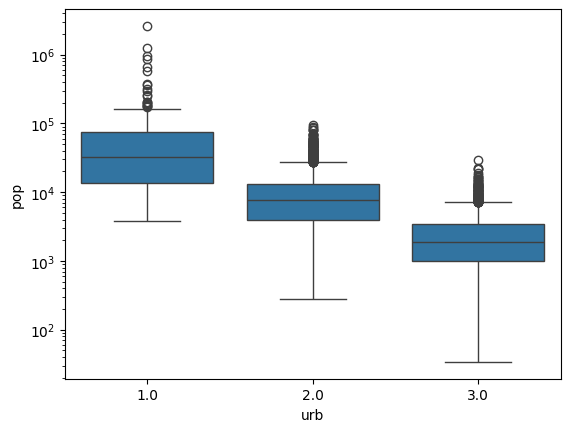

In [48]:
print(df.groupby("urb")[["pop", "pden", "area"]].median().round(1))

sns.boxplot(data=df, x="urb", y="pop")
plt.yscale("log")
plt.show()

**(b) `gdp` dan `finance`:** rasio, korelasi, dan scatterplot kedua variabel.

count    3955.00
mean        1.03
std         0.00
min         1.03
1%          1.03
50%         1.03
99%         1.03
max         1.03
dtype: float64 

           gdp  finance   wage
gdp      1.000    1.000 -0.317
finance  1.000    1.000 -0.317
wage    -0.317   -0.317  1.000 

hanya gdp terisi: 0 | hanya finance terisi: 0


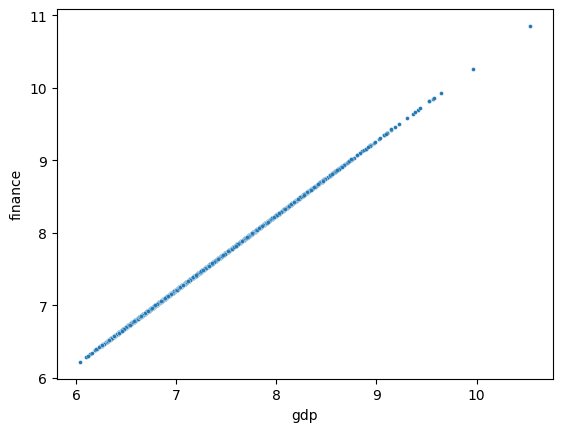

In [49]:
rasio = df["finance"] / df["gdp"]
print(rasio.describe(percentiles=[.01, .5, .99]).round(4), "\n")
print(df[["gdp", "finance", "wage"]].corr().round(3), "\n")
print("hanya gdp terisi:", (df["gdp"].notna() & df["finance"].isna()).sum(),
      "| hanya finance terisi:", (df["gdp"].isna() & df["finance"].notna()).sum())

sns.scatterplot(data=df, x="gdp", y="finance", s=8)
plt.show()

**(c) Kepadatan jalan (`roads` / `area`):** baris dengan kepadatan tertinggi dan hubungan `area` dengan `roads`. Tindak lanjut (sel berikutnya): jumlah baris di atas beberapa ambang kepadatan, dan apakah pola missing `roads` sama dengan `proads`.

count    3898.00
mean        3.53
std        12.01
min         0.04
50%         2.47
95%         8.23
99%        14.56
max       679.84
Name: road_dens, dtype: float64 

              region               province                     name    pop       area    roads   road_dens
4190          Molise                Isernia  Montenero Val Cocchiara    558  22.020000  14970.0  679.836498
2179       Lombardia  Monza e della Brianza                    Lesmo   8094   5.120000   1165.0  227.539068
743        Lombardia                Cremona       Pescarolo ed Uniti   1608  16.540001   1261.0   76.239415
1474        Campania                Caserta             Pietramelara   4657  23.930000   1689.0   70.580860
3729           Lazio                  Rieti                    Labro    344  11.740000    800.0   68.143102
881   Emilia_Romagna                Bologna      Casalecchio di Reno  35173  17.330000   1032.0   59.549914
580         Campania                Caserta       Portico di Caserta   771

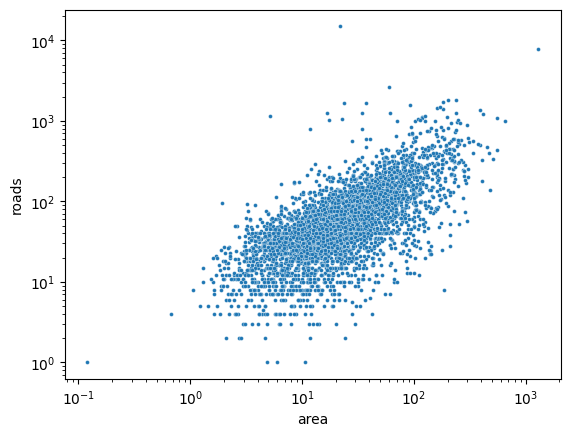

In [50]:
d = df.assign(road_dens=df["roads"] / df["area"])
print(d["road_dens"].describe(percentiles=[.5, .95, .99]).round(2), "\n")
print(d.nlargest(8, "road_dens")[["region", "province", "name", "pop", "area", "roads", "road_dens"]])

sns.scatterplot(data=d, x="area", y="roads", s=8)
plt.xscale("log"); plt.yscale("log")
plt.show()

In [51]:
# Ekor atas kepadatan jalan, dan apakah proads missing sama persis dengan roads
rd = df["roads"] / df["area"]
for batas in [15, 30, 50]:
    print(f"road_dens > {batas}:", (rd > batas).sum())
print("pola missing roads == proads:", (df["roads"].isna() == df["proads"].isna()).all(), "\n")

road_dens > 15: 37
road_dens > 30: 11
road_dens > 50: 6
pola missing roads == proads: True 



**(d) `organic` rendah dan selisih komposisi dengan `sor`:** apakah baris dengan `organic` < 2 sekaligus punya `gap` besar (> 5). Tindak lanjut: baris dengan `organic` normal tetapi `gap` besar, dan sebarannya per region.

In [52]:
lengkap = df[kol_komp].notna().all(axis=1)

c = df.loc[lengkap].copy()
c["gap"] = c["sor"] - c[kol_komp].sum(axis=1)
c["organic_rendah"] = c["organic"] < 2
c["gap_besar"] = c["gap"] > 5

print(pd.crosstab(c["organic_rendah"], c["gap_besar"], margins=True), "\n")
print(c.groupby("organic_rendah")["gap"].describe().round(2))

gap_besar       False  True   All
organic_rendah                   
False            1695   329  2024
True               34   152   186
All              1729   481  2210 

                 count   mean    std  min    25%    50%    75%    max
organic_rendah                                                       
False           2024.0   4.03   9.41 -0.0  -0.00   0.00   0.11  42.13
True             186.0  22.81  13.50 -0.0  13.58  26.13  33.71  46.63


In [53]:
# 329 baris: organic normal tapi gap besar
lengkap = df[kol_komp].notna().all(axis=1)
c = df.loc[lengkap].copy()
c["gap"] = c["sor"] - c[kol_komp].sum(axis=1)

dasar = c[c["organic"] >= 2]
besar = dasar[dasar["gap"] > 5]
print(len(besar)); print(besar["gap"].describe().round(1), "\n")

tab = pd.DataFrame({"gap_besar": besar["region"].value_counts(),
                    "total": dasar["region"].value_counts()}).fillna(0).astype(int)
tab["persen"] = (tab["gap_besar"] / tab["total"] * 100).round(1)
print(tab.sort_values("persen", ascending=False))

329
count    329.0
mean      24.5
std        6.6
min        5.5
25%       20.3
50%       23.8
75%       28.2
max       42.1
Name: gap, dtype: float64 

                       gap_besar  total  persen
region                                         
Sardegna                      17     30    56.7
Emilia_Romagna                68    179    38.0
Campania                      22     63    34.9
Sicilia                       18     57    31.6
Lazio                         17     54    31.5
Umbria                         9     32    28.1
Toscana                       31    117    26.5
Liguria                       12     84    14.3
Abruzzo                        9     70    12.9
Veneto                        22    176    12.5
Puglia                         3     25    12.0
Friuli_Venezia_Giulia          9     77    11.7
Lombardia                     78    725    10.8
Marche                         7     69    10.1
Calabria                       2     23     8.7
Trentino_Alto_Adige            3

**(e) `tc` dibanding `cres + csor`:** sebaran selisih `tc - (cres + csor)` dan korelasi ketiganya. Tindak lanjut: berapa baris yang selisihnya negatif atau hampir nol, beserta baris dengan selisih paling negatif.

In [54]:
sisa = df["tc"] - (df["cres"] + df["csor"])
print(sisa.describe(percentiles=[.01, .5, .99]).round(1))
print("sisa < 0:", (sisa < 0).sum(), "dari", sisa.notna().sum(), "\n")
print(df[["tc", "cres", "csor"]].corr().round(2))

count    4222.0
mean       48.9
std        47.8
min      -823.5
1%         -0.0
50%        38.0
99%       206.7
max       706.4
dtype: float64
sisa < 0: 50 dari 4222 

        tc  cres  csor
tc    1.00  0.64  0.46
cres  0.64  1.00  0.04
csor  0.46  0.04  1.00


In [55]:
# Seberapa material tc < cres + csor?
sisa = df["tc"] - (df["cres"] + df["csor"])
print("sisa < -1:", (sisa < -1).sum(), "| |sisa| <= 0.05:", (sisa.abs() <= 0.05).sum(), "dari", sisa.notna().sum())
print(df.assign(sisa=sisa).nsmallest(6, "sisa")[["region", "province", "name", "pop", "tc", "cres", "csor", "sisa"]], "\n")

sisa < -1: 2 | |sisa| <= 0.05: 112 dari 4222
       region               province                      name    pop          tc        cres        csor        sisa
87    Liguria                 Genova                 Portofino    453  124.980003  366.279999  582.159973 -823.459969
4312  Abruzzo               L'Aquila               Rivisondoli    663  109.230003  670.320007   89.949997 -651.040001
3307    Lazio                   Roma                    Casape    737  218.039993  199.830002   18.219999   -0.010008
948    Puglia  Barletta-Andria-Trani  San Ferdinando di Puglia  13916  181.500000  149.380005   32.130001   -0.010006
2132   Veneto                Vicenza                  Caltrano   2607   77.769997   41.490002   36.290001   -0.010006
3221  Abruzzo                Pescara                Abbateggio    441  129.669998   40.560001   89.120003   -0.010006 



#### 3.1.7 Profil kategori dan perbandingan kelompok

Ringkasan per region (jumlah kota, persentase PAYT, median `pop`, `tc`, `sor`), hubungan `urb` dan `geo` dengan skema tarif, serta perbandingan PAYT dan STANDARD pada variabel biaya dan pemilahan.

                          n  persen_payt  median_pop  median_tc  median_sor
region                                                                     
Lombardia              1230         14.1      3324.0      114.6        76.6
Campania                405          0.0      3832.0      158.9        65.1
Emilia_Romagna          308         24.7      6406.5      154.4        69.6
Veneto                  265         37.7      5061.0      104.1        78.7
Toscana                 231         10.4      6409.0      195.9        64.4
Sicilia                 212          0.5      6825.0      162.8        59.0
Lazio                   188          1.1      4102.0      161.3        66.3
Friuli_Venezia_Giulia   183         18.0      2877.0      114.4        73.8
Liguria                 179          2.8      1373.0      215.1        66.4
Calabria                165          0.0      2559.0      119.1        56.0
Trentino_Alto_Adige     157         83.4      2533.0       91.8        72.2
Abruzzo     

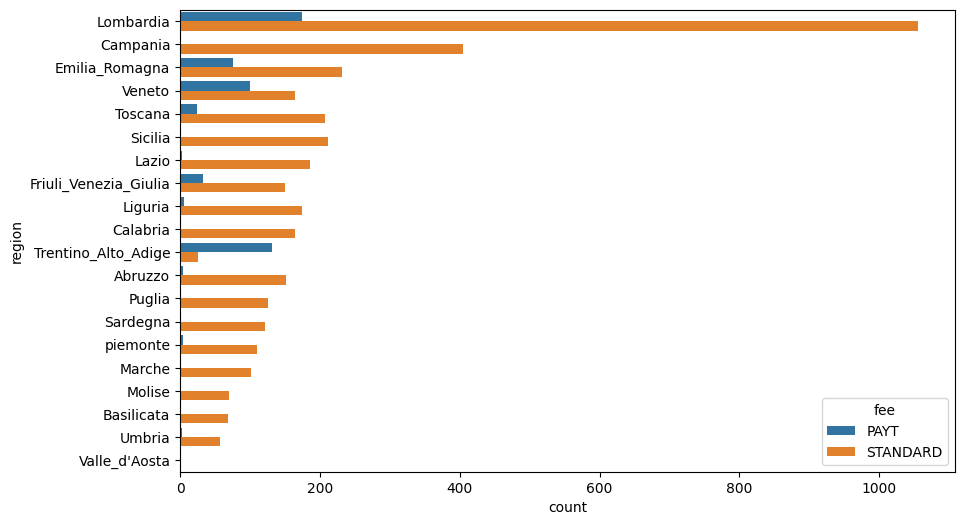

In [56]:
ringkas = df.groupby("region").agg(
    n=("istat", "size"),
    persen_payt=("d_fee", "mean"),
    median_pop=("pop", "median"),
    median_tc=("tc", "median"),
    median_sor=("sor", "median"),
)
ringkas["persen_payt"] = (ringkas["persen_payt"] * 100).round(1)
print(ringkas.sort_values("n", ascending=False).round(1), "\n")

print(pd.crosstab(df["urb"], df["fee"], normalize="index").round(3), "\n")
print(pd.crosstab(df["geo"], df["fee"], margins=True))

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y="region", order=df["region"].value_counts().index, hue="fee")
plt.show()

fee        PAYT  STANDARD
tc        115.8     140.0
cres       28.5      44.1
csor       47.3      49.4
sor        80.7      69.2
msw_pc    464.2     431.1
organic    29.8      24.2
plastic     6.4       5.7
pop      4644.0    3368.0 

                 tc          sor       msw_pc      
             median count median count median count
geo fee                                            
1.0 PAYT      170.8     4   74.6     4  270.2     4
    STANDARD  152.5  1174   65.2  1174  344.3  1174
1.5 STANDARD  172.2     3   43.4     3  514.6     3
2.0 PAYT      160.6    33   84.4    33  484.8    33
    STANDARD  184.1   483   66.8   483  463.9   483
3.0 PAYT      113.5   512   80.6   512  461.6   512
    STANDARD  121.9  1847   73.6  1847  466.8  1847


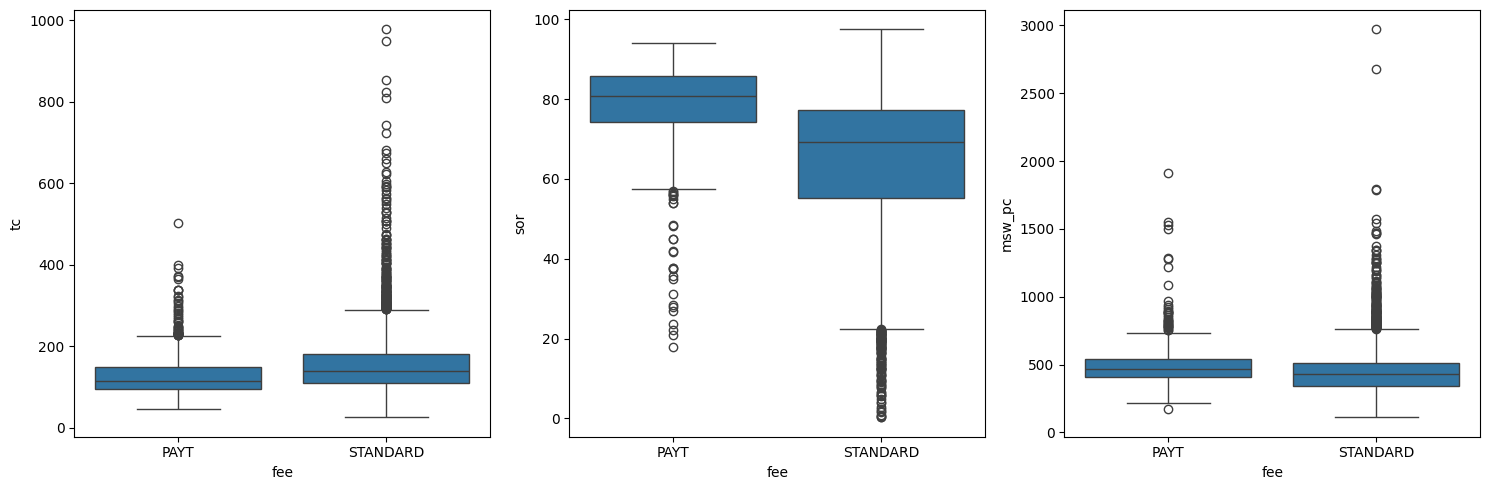

In [57]:
d = df.assign(msw_pc=df["msw"] / df["pop"])
kol_cmp = ["tc", "cres", "csor", "sor", "msw_pc", "organic", "plastic", "pop"]

print(d.groupby("fee")[kol_cmp].median().round(1).T, "\n")
print(d.groupby(["geo", "fee"])[["tc", "sor", "msw_pc"]].agg(["median", "count"]).round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axes, ["tc", "sor", "msw_pc"]):
    sns.boxplot(data=d, x="fee", y=k, ax=ax)
plt.tight_layout()
plt.show()

#### 3.1.8 Korelasi dan multikolinearitas

Korelasi Spearman dan Pearson antarvariabel numerik (pasangan dengan |ρ| ≥ 0,5 dan heatmap), korelasi antara `msw`, `msw_so`, `msw_un`, `pop`, dan `msw_pc`, korelasi variabel biaya dan pemilahan dengan variabel lain (|ρ| ≥ 0,3), serta scatterplot yang diwarnai menurut `geo`.

                       spearman  pearson
geo        wage            0.76     0.79
s_wteregio s_landfill     -0.71    -0.47
area       roads           0.70     0.40
pop        urb            -0.67    -0.25
cres       sor            -0.58    -0.47
tc         cres            0.57     0.64
geo        wood            0.54     0.48
organic    sor             0.52     0.54
pop        roads           0.52     0.47
geo        s_wteregio      0.52     0.43


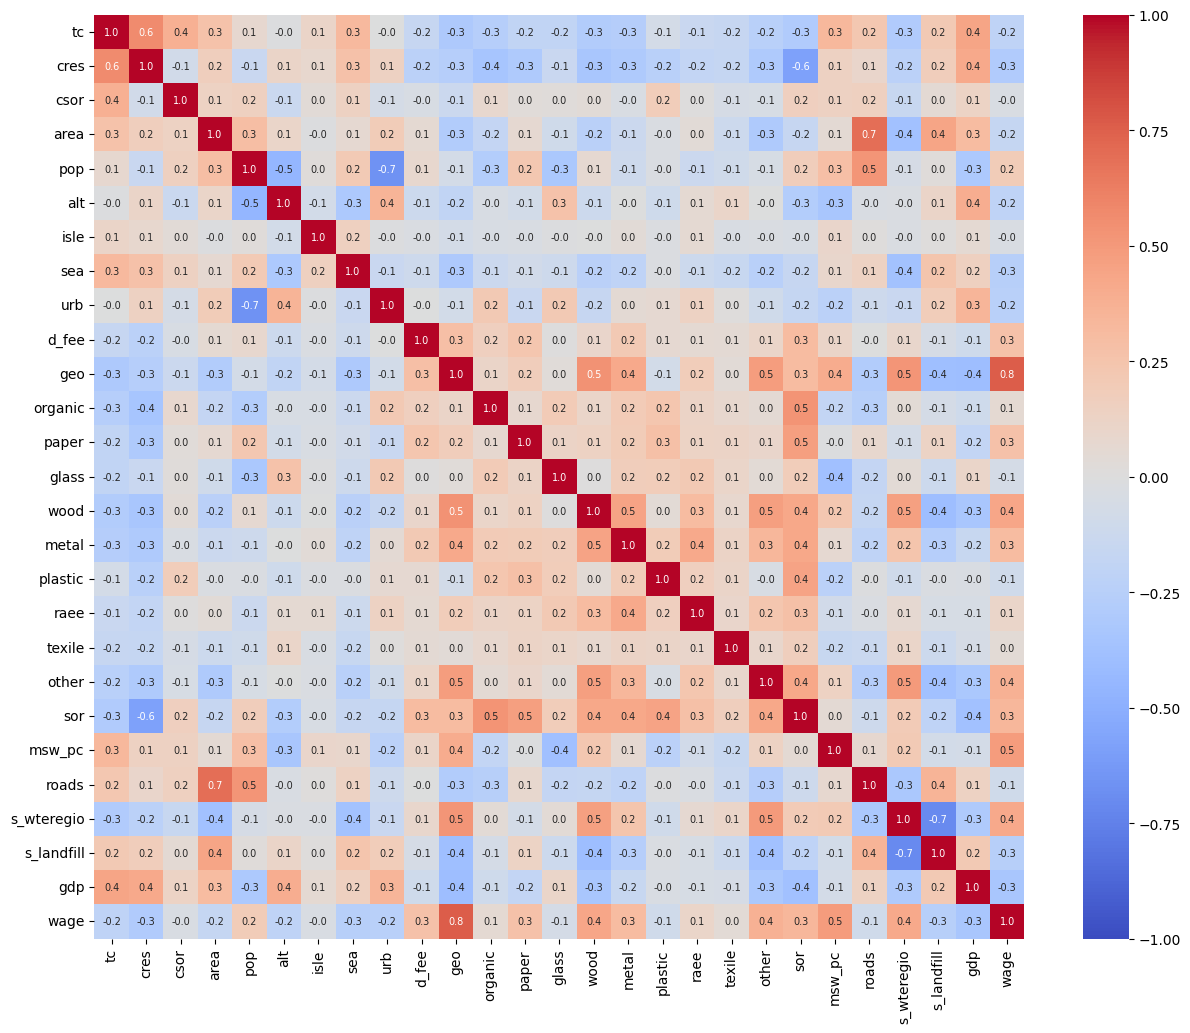

In [58]:
d = df.assign(msw_pc=df["msw"] / df["pop"])
kol_kor = ["tc", "cres", "csor", "area", "pop", "alt", "isle", "sea", "urb", "d_fee", "geo",
           "organic", "paper", "glass", "wood", "metal", "plastic", "raee", "texile", "other",
           "sor", "msw_pc", "roads", "s_wteregio", "s_landfill", "gdp", "wage"]

sp = d[kol_kor].corr(method="spearman")
pr = d[kol_kor].corr(method="pearson")

pasang = sp.where(np.triu(np.ones(sp.shape, dtype=bool), k=1)).stack().to_frame("spearman")
pasang["pearson"] = [pr.loc[a, b] for a, b in pasang.index]
pasang["abs"] = pasang["spearman"].abs()
print(pasang[pasang["abs"] >= 0.5].sort_values("abs", ascending=False).drop(columns="abs").round(2).to_string())

plt.figure(figsize=(15, 12))
sns.heatmap(sp, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.show()

In [59]:
print(d[["msw", "msw_so", "msw_un", "pop", "msw_pc"]].corr(method="spearman").round(2))

         msw  msw_so  msw_un   pop  msw_pc
msw     1.00    0.98    0.92  0.97    0.48
msw_so  0.98    1.00    0.83  0.95    0.45
msw_un  0.92    0.83    1.00  0.89    0.46
pop     0.97    0.95    0.89  1.00    0.28
msw_pc  0.48    0.45    0.46  0.28    1.00


In [60]:
for target in ["sor", "tc", "cres", "csor", "msw_pc"]:
    s = sp[target].drop(target)
    print(target)
    print(s[s.abs() >= 0.3].sort_values(key=abs, ascending=False).round(2).to_string(), "\n")

sor
cres      -0.58
organic    0.52
paper      0.47
plastic    0.45
metal      0.43
other      0.43
wood       0.42
gdp       -0.38
wage       0.34
geo        0.31
d_fee      0.31 

tc
cres      0.57
gdp       0.44
csor      0.38
msw_pc    0.33
sea       0.33
geo      -0.31 

cres
sor       -0.58
tc         0.57
gdp        0.42
organic   -0.35
wood      -0.34
other     -0.30 

csor
tc    0.38 

msw_pc
wage     0.49
geo      0.40
glass   -0.39
alt     -0.34
tc       0.33 



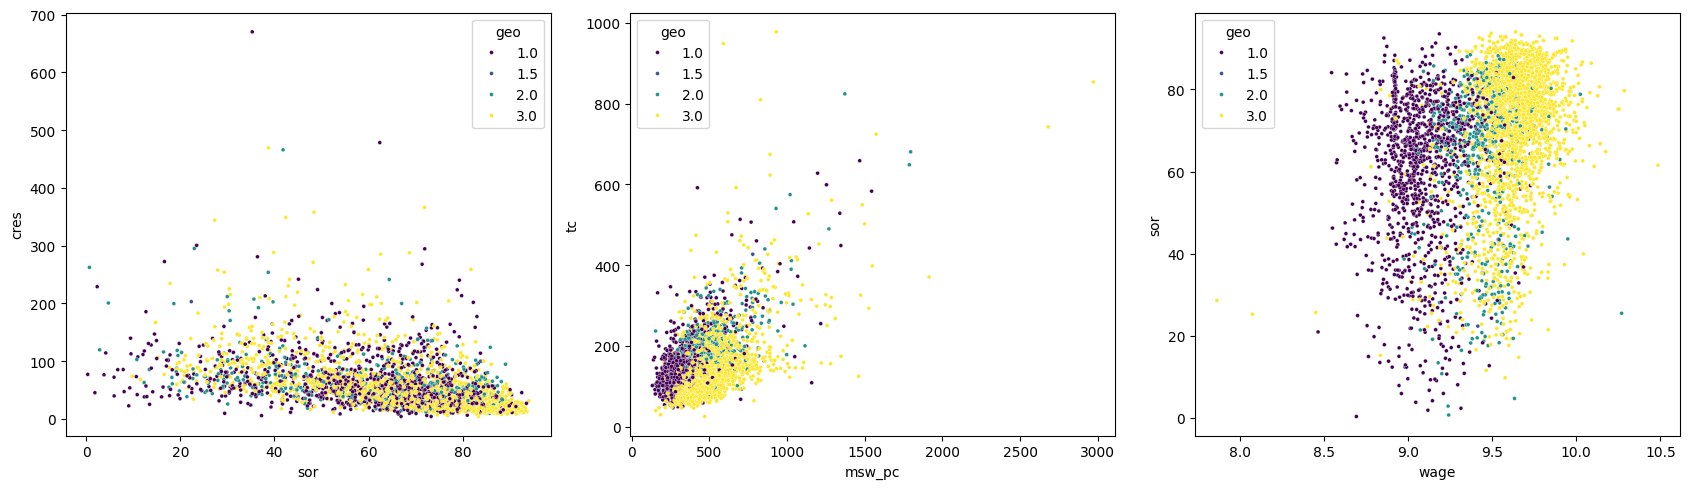

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=d, x="sor", y="cres", hue="geo", palette="viridis", s=8, ax=axes[0])
sns.scatterplot(data=d, x="msw_pc", y="tc", hue="geo", palette="viridis", s=8, ax=axes[1])
sns.scatterplot(data=d, x="wage", y="sor", hue="geo", palette="viridis", s=8, ax=axes[2])
plt.tight_layout()
plt.show()

#### 3.1.9 Pengaruh region terhadap variabel

Seberapa besar variasi tiap variabel dijelaskan oleh region dan provinsi (eta kuadrat), dan apakah korelasi antarvariabel tetap ada setelah rata-rata region dihilangkan (korelasi di dalam region).

In [62]:
def eta_kuadrat(data, kolom, grup):
    d_ = data[[kolom, grup]].dropna()
    rata = d_[kolom].mean()
    ss_total = ((d_[kolom] - rata) ** 2).sum()
    ss_antar = d_.groupby(grup)[kolom].apply(lambda s: len(s) * (s.mean() - rata) ** 2).sum()
    return ss_antar / ss_total

d = df.assign(msw_pc=df["msw"] / df["pop"])
kol_eta = ["tc", "cres", "csor", "sor", "msw_pc", "organic", "paper", "glass", "wood",
           "metal", "plastic", "raee", "texile", "other", "wage", "gdp"]

hasil = pd.DataFrame({
    "eta2_region":   [eta_kuadrat(d, k, "region") for k in kol_eta],
    "eta2_province": [eta_kuadrat(d, k, "province") for k in kol_eta],
}, index=kol_eta).round(2)
print(hasil.sort_values("eta2_region", ascending=False))

         eta2_region  eta2_province
wage            0.70           0.75
other           0.38           0.48
gdp             0.34           0.42
wood            0.29           0.42
msw_pc          0.23           0.31
metal           0.21           0.33
tc              0.20           0.30
sor             0.18           0.40
glass           0.17           0.32
plastic         0.17           0.37
paper           0.13           0.28
cres            0.12           0.21
organic         0.12           0.29
csor            0.08           0.17
raee            0.07           0.18
texile          0.05           0.13


In [63]:
kol_w = ["tc", "cres", "csor", "sor", "msw_pc", "organic", "paper", "glass",
         "plastic", "wage", "gdp", "alt"]

resid = d[kol_w] - d.groupby("region")[kol_w].transform("mean")
total = d[kol_w].corr(method="spearman")
dalam = resid.corr(method="spearman")

pas = total.where(np.triu(np.ones(total.shape, dtype=bool), k=1)).stack().to_frame("total")
pas["dalam_region"] = [dalam.loc[a, b] for a, b in pas.index]
print(pas[pas["total"].abs() >= 0.3].sort_values("total", key=abs, ascending=False).round(2).to_string())

                total  dalam_region
cres   sor      -0.58         -0.49
tc     cres      0.57          0.47
sor    organic   0.52          0.48
msw_pc wage      0.49          0.24
sor    paper     0.47          0.49
       plastic   0.45          0.52
tc     gdp       0.44          0.35
cres   gdp       0.42          0.28
gdp    alt       0.39          0.29
msw_pc glass    -0.39         -0.38
tc     csor      0.38          0.35
sor    gdp      -0.38         -0.19
cres   organic  -0.35         -0.28
wage   gdp      -0.34         -0.07
msw_pc alt      -0.34         -0.26
sor    wage      0.34          0.16
tc     msw_pc    0.33          0.49


#### 3.1.10 Struktur multivariat dan kecenderungan klaster

PCA dan statistik Hopkins pada variabel biaya, pemilahan, dan komposisi sampah, masing-masing dengan dua versi penskalaan (z-score dan rank). PCA di sini dipakai untuk melihat struktur data, bukan sebagai praproses. Dilanjutkan dengan posisi skor PC menurut `geo` dan `fee`.

In [64]:
def hopkins(X, seed=0):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    m = max(int(0.1 * n), 10)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = rng.choice(n, m, replace=False)
    u = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]          # jarak ke tetangga terdekat (selain dirinya)
    R = rng.uniform(X.min(0), X.max(0), size=(m, p))           # titik acak di kotak pembatas
    w = nn.kneighbors(R, n_neighbors=1)[0][:, 0]
    return w.sum() / (w.sum() + u.sum())

d = df.assign(msw_pc=df["msw"] / df["pop"])
kol_pca = ["tc", "cres", "csor", "sor", "msw_pc", "organic", "paper", "glass", "plastic", "metal", "other"]
X = d[kol_pca].dropna()
print("Baris lengkap:", len(X), "dari", len(d), "\n")

versi = {
    "z-score": pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=kol_pca),
    "rank":    X.rank(pct=True),
}

hasil_pca = {}
for nama, Z in versi.items():
    pca = PCA().fit(Z)
    skor = pd.DataFrame(pca.transform(Z)[:, :3], index=Z.index, columns=["PC1", "PC2", "PC3"])
    hasil_pca[nama] = skor
    print(f"=== {nama} ===")
    print("Varians per PC (5 pertama):", pca.explained_variance_ratio_[:5].round(3),
          "| kumulatif 3 PC:", pca.explained_variance_ratio_[:3].sum().round(3))
    print(pd.DataFrame(pca.components_[:3].T, index=kol_pca, columns=["PC1", "PC2", "PC3"]).round(2))
    h = [hopkins(Z.values, seed=s) for s in range(10)]
    print(f"Hopkins (10 seed): {np.mean(h):.3f} ± {np.std(h):.3f}\n")

Baris lengkap: 3441 dari 4341 

=== z-score ===
Varians per PC (5 pertama): [0.274 0.149 0.126 0.096 0.082] | kumulatif 3 PC: 0.549
          PC1   PC2   PC3
tc      -0.41  0.43 -0.06
cres    -0.43  0.10 -0.07
csor    -0.11  0.57 -0.15
sor      0.46  0.36  0.09
msw_pc  -0.28  0.40  0.41
organic  0.32  0.18 -0.16
paper    0.21  0.18  0.08
glass    0.20  0.09 -0.41
plastic  0.22  0.29 -0.38
metal    0.25  0.16  0.30
other    0.22  0.05  0.60
Hopkins (10 seed): 0.900 ± 0.002

=== rank ===
Varians per PC (5 pertama): [0.291 0.142 0.136 0.091 0.078] | kumulatif 3 PC: 0.568
          PC1   PC2   PC3
tc      -0.36  0.08  0.48
cres    -0.43 -0.07  0.04
csor    -0.02  0.05  0.66
sor      0.47  0.17  0.23
msw_pc  -0.15  0.63  0.16
organic  0.33 -0.13  0.16
paper    0.26  0.03  0.11
glass    0.21 -0.43 -0.02
plastic  0.24 -0.24  0.44
metal    0.32  0.25 -0.03
other    0.25  0.48 -0.18
Hopkins (10 seed): 0.600 ± 0.005



In [65]:
sk = hasil_pca["z-score"].join(df[["geo", "fee"]])
print(sk.groupby("geo")[["PC1", "PC2"]].agg(["median", "count"]).round(2), "\n")
print(sk.groupby("fee")[["PC1", "PC2"]].agg(["median", "count"]).round(2))

       PC1          PC2      
    median count median count
geo                          
1.0  -0.33   873  -0.29   873
1.5  -4.68     2  -0.19     2
2.0  -0.41   411   0.18   411
3.0   0.85  1961  -0.03  1961 

            PC1          PC2      
         median count median count
fee                               
PAYT       1.21   466   0.21   466
STANDARD   0.22  2975  -0.12  2975


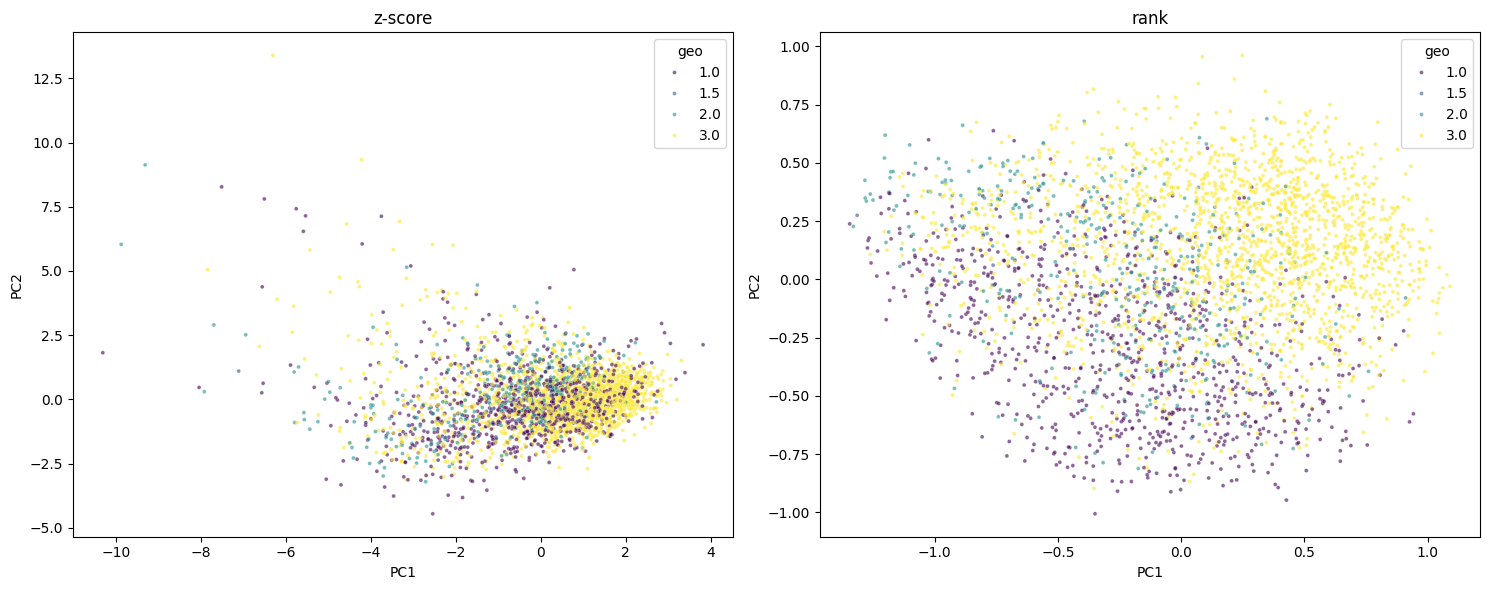

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (nama, skor) in zip(axes, hasil_pca.items()):
    sns.scatterplot(data=skor.join(df["geo"]), x="PC1", y="PC2", hue="geo",
                    palette="viridis", s=8, alpha=0.6, ax=ax)
    ax.set_title(nama)
plt.tight_layout()
plt.show()

**Pemeriksaan lanjutan struktur multivariat:** kepadatan titik pada ruang PC, apakah perbedaan PAYT dan STANDARD tetap ada di dalam `geo = 3`, posisi baris dengan `organic` < 2, dan baris dengan skor PC ekstrem.

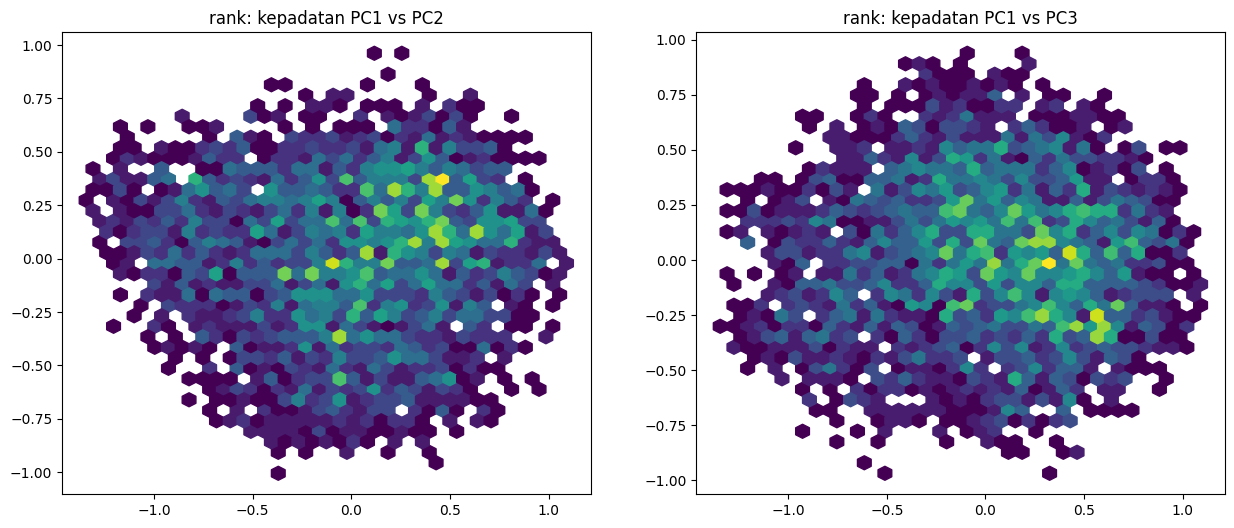

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sk = hasil_pca["rank"]
axes[0].hexbin(sk["PC1"], sk["PC2"], gridsize=35, cmap="viridis", mincnt=1)
axes[0].set_title("rank: kepadatan PC1 vs PC2")
axes[1].hexbin(sk["PC1"], sk["PC3"], gridsize=35, cmap="viridis", mincnt=1)
axes[1].set_title("rank: kepadatan PC1 vs PC3")
plt.show()

In [68]:
for nama, skor in hasil_pca.items():
    sk = skor.join(df[["geo", "fee"]])
    print(nama)
    print(sk[sk["geo"] == 3].groupby("fee")[["PC1", "PC2"]].agg(["median", "count"]).round(2), "\n")

z-score
            PC1          PC2      
         median count median count
fee                               
PAYT       1.29   427   0.23   427
STANDARD   0.73  1534  -0.10  1534 

rank
            PC1          PC2      
         median count median count
fee                               
PAYT       0.46   427   0.12   427
STANDARD   0.20  1534   0.16  1534 



organic_rendah
False    3140
True      301
Name: count, dtype: int64 

                     PC1   PC2
organic_rendah                
False          0.1 -0.65 -0.55
               0.5  0.10  0.04
               0.9  0.67  0.45
True           0.1 -1.05 -0.34
               0.5 -0.62  0.04
               0.9 -0.04  0.35


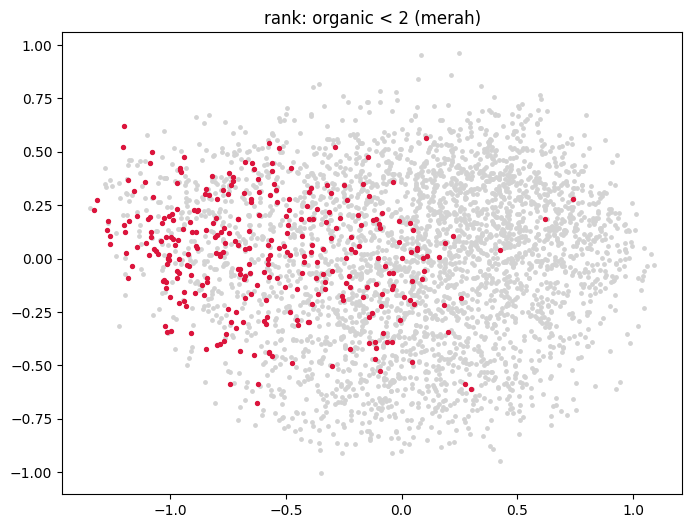

In [69]:
rendah = (d.loc[hasil_pca["rank"].index, "organic"] < 2).rename("organic_rendah")
o = hasil_pca["rank"].join(rendah)
print(o["organic_rendah"].value_counts(), "\n")
print(o.groupby("organic_rendah")[["PC1", "PC2"]].quantile([.1, .5, .9]).round(2))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(o["PC1"], o["PC2"], s=6, c="lightgray")
ax.scatter(o.loc[o["organic_rendah"], "PC1"], o.loc[o["organic_rendah"], "PC2"], s=8, c="crimson")
ax.set_title("rank: organic < 2 (merah)")
plt.show()

In [70]:
z = hasil_pca["z-score"].join(df[["region", "province", "name", "pop", "tc", "cres", "csor", "sor"]])
print(z.nlargest(8, "PC2").round(2).to_string(), "\n")
print(z.nsmallest(8, "PC1").round(2).to_string())

       PC1    PC2   PC3               region      province                        name   pop      tc    cres    csor    sor
87   -6.31  13.40 -3.14              Liguria        Genova                   Portofino   453  124.98  366.28  582.16  71.89
4333 -4.22   9.33  2.23  Trentino_Alto_Adige       Bolzano    Corvara in Badia/Corvara  1320  370.88   89.14  260.18  75.21
1094 -9.32   9.13  2.95              Toscana       Livorno                     Bibbona  3209  680.45  241.43  205.59  64.39
211  -7.52   8.27 -0.74             Sardegna       Sassari                    Stintino  1501  658.55  294.62  142.79  71.92
33   -5.28   8.01  0.30              Toscana       Livorno             Campo nell'Elba  4553  604.68  172.27  232.57  67.14
687  -6.51   7.80  0.77             Sardegna  Sud Sardegna                 Villasimius  3420  583.14  213.50  147.61  79.76
149  -5.76   7.42 -1.54              Sicilia       Trapani            San Vito Lo Capo  4415  507.22  125.32  273.93  65.26
2857 -5.

### 3.2 Pengujian hipotesis spesifik

Bagian ini menguji dugaan tertentu yang muncul dari EDA dasar di atas. Setiap sub-bagian memuat satu dugaan beserta pengecekan pendukungnya. Beberapa pengecekan memakai regresi OLS dengan error standar yang dikelompokkan per provinsi (`statsmodels`). Sel-sel di bagian ini dijalankan berurutan karena beberapa memakai variabel dari sel sebelumnya.

Fungsi bantu untuk bagian ini:

In [71]:
r = lambda x, n=1: round(float(x), n)   # pembulatan ringkas untuk cetakan


def klaster(data):
    return {"groups": pd.factorize(data["province"])[0]}   # kelompok = provinsi, untuk error standar klaster

#### 3.2.1 PAYT vs STANDARD setelah mengontrol lokasi

Kota PAYT tidak tersebar merata antar wilayah, sehingga perbedaan PAYT dan STANDARD bisa bercampur dengan perbedaan antar wilayah. Karena itu keduanya dibandingkan di dalam region (region dengan minimal 20 kota PAYT) dan di dalam provinsi (provinsi dengan minimal 5 kota di tiap skema).

In [72]:
d = df.assign(msw_pc=df["msw"] / df["pop"])

# PAYT vs STANDARD di dalam region (hanya region dengan >= 20 kota PAYT)
reg = d.groupby("region")["d_fee"].sum().loc[lambda s: s >= 20].index
sub = d[d["region"].isin(reg)]
print(sub.groupby(["region", "fee"])[["sor", "tc", "cres", "msw_pc"]].median().round(1)
         .join(sub.groupby(["region", "fee"]).size().rename("n")), "\n")

                                 sor     tc  cres  msw_pc     n
region                fee                                      
Emilia_Romagna        PAYT      84.8  169.9  32.8   546.6    76
                      STANDARD  64.2  150.4  49.0   651.7   232
Friuli_Venezia_Giulia PAYT      80.3  109.7  32.1   431.3    33
                      STANDARD  72.3  114.8  39.6   454.5   150
Lombardia             PAYT      84.9  111.6  22.2   464.1   174
                      STANDARD  75.5  115.1  31.8   459.9  1056
Toscana               PAYT      85.4  145.1  65.0   487.6    24
                      STANDARD  59.4  200.5  61.5   555.6   207
Trentino_Alto_Adige   PAYT      71.4   89.1  31.1   488.4   131
                      STANDARD  74.5   94.0  41.5   444.2    26
Veneto                PAYT      80.8  107.2  28.9   414.2   100
                      STANDARD  77.2  103.2  31.8   420.7   165 



In [73]:
# PAYT vs STANDARD di dalam provinsi (provinsi dengan >= 5 kota di tiap skema)
t = df.groupby(["province", "fee"])["sor"].agg(["median", "count"]).unstack("fee")
t.columns = [f"{a}_{b}" for a, b in t.columns]
ok = t[(t["count_PAYT"] >= 5) & (t["count_STANDARD"] >= 5)].copy()
ok["selisih_sor"] = ok["median_PAYT"] - ok["median_STANDARD"]
print(len(ok), "provinsi memenuhi syarat")
print("selisih > 0:", (ok["selisih_sor"] > 0).sum(), "| selisih < 0:", (ok["selisih_sor"] < 0).sum())
print(ok["selisih_sor"].describe().round(1), "\n")
print(ok.sort_values("selisih_sor").round(1).to_string())

23 provinsi memenuhi syarat
selisih > 0: 21 | selisih < 0: 2
count    23.0
mean     10.5
std      13.1
min     -26.4
25%       3.6
50%       8.5
75%      17.0
max      35.8
Name: selisih_sor, dtype: float64 

               median_PAYT  median_STANDARD  count_PAYT  count_STANDARD  selisih_sor
province                                                                            
Como                  41.6             68.1        11.0            95.0        -26.4
Pavia                 39.8             40.5        10.0            84.0         -0.7
Padova                77.3             76.5        37.0            23.0          0.9
Venezia               80.9             79.3        17.0            27.0          1.6
Mantova               89.0             85.9        41.0            22.0          3.1
Brescia               82.4             79.1        38.0           134.0          3.3
Pordenone             80.4             76.5        13.0            37.0          4.0
Varese                85.7

#### 3.2.2 Dugaan kota wisata

Dugaan: kota dengan `msw_pc` (sampah per kapita) tertinggi adalah kota wisata, yaitu kota pantai (`sea`), berketinggian ≥ 1.000 m, atau berpenduduk kecil. Diperiksa lewat 5% teratas `msw_pc` secara nasional dan per region (V13), regresi `log(msw/pop)` dengan efek tetap region atau provinsi (V17), dan cakupan geografi pada 5% teratas per region (V18).

In [74]:
d = df.assign(msw_pc=df["msw"] / df["pop"])

# Dugaan kota wisata: apakah msw_pc teratas (5%) lebih sering di kota pantai dan berpenduduk kecil?
atas = d["msw_pc"] > d["msw_pc"].quantile(.95)
print(d.groupby(atas)[["sea", "pop", "alt"]].agg(["mean", "median"]).round(2))

         sea              pop             alt       
        mean median      mean  median    mean median
msw_pc                                              
False   0.16    0.0  10228.70  3501.5  309.11  247.0
True    0.39    0.0   9731.32  4407.0  327.94   95.0


In [75]:
# V13: wisata vs geser region pada msw_pc
d = df.assign(msw_pc=df["msw"] / df["pop"])
atas = d["msw_pc"] > d["msw_pc"].quantile(.95)
cmp = pd.DataFrame({"persen_atas": d.loc[atas, "region"].value_counts(normalize=True),
                    "persen_data": d["region"].value_counts(normalize=True)}).fillna(0)
cmp["rasio"] = cmp["persen_atas"] / cmp["persen_data"]
print("V13 |\n", cmp.sort_values("rasio", ascending=False).round(3).head(8).to_string(), "\n")

d["pct_reg"] = d.groupby("region")["msw_pc"].rank(pct=True)
atas_reg = d["pct_reg"] > 0.95
print(d.groupby(atas_reg).agg(n=("sea", "size"), pantai=("sea", "mean"), alt_median=("alt", "median")).round(2))
print("alt >= 1000:", d.groupby(atas_reg)["alt"].apply(lambda s: (s >= 1000).mean()).round(3).to_dict(), "\n")

V13 |
                      persen_atas  persen_data  rasio
region                                              
Emilia_Romagna             0.290        0.071  4.092
Toscana                    0.143        0.053  2.685
Trentino_Alto_Adige        0.097        0.036  2.676
Liguria                    0.092        0.041  2.235
Sardegna                   0.041        0.028  1.488
Lombardia                  0.166        0.283  0.586
Lazio                      0.023        0.043  0.532
piemonte                   0.014        0.026  0.526 

            n  pantai  alt_median
pct_reg                          
False    4113    0.15       243.0
True      228    0.44       113.0
alt >= 1000: {False: 0.022, True: 0.101} 



In [76]:
# V17: regresi log(msw/pop)
d = df.assign(msw_pc=df["msw"] / df["pop"]).copy()
d["ln_pc"], d["ln_pop"] = np.log(d["msw_pc"]), np.log(d["pop"])
d["alt1000"] = (d["alt"] >= 1000).astype(int)
dd = d.dropna(subset=["sea", "alt"])
spec = {"region saja": "ln_pc ~ C(region)",
        "+ pantai, alt": "ln_pc ~ sea + alt1000 + C(region)",
        "+ ln_pop": "ln_pc ~ sea + alt1000 + ln_pop + C(region)",
        "FE provinsi": "ln_pc ~ sea + alt1000 + C(province)"}
print("\nV17 |")
for nama, f in spec.items():
    m = smf.ols(f, dd).fit(cov_type="cluster", cov_kwds=klaster(dd))
    teks = ", ".join(f"{k}: x{np.exp(m.params[k]):.2f} (p={m.pvalues[k]:.3f})" for k in ["sea", "alt1000"] if k in m.params)
    if "ln_pop" in m.params:
        teks += f", ln_pop: {m.params['ln_pop']:+.3f} (p={m.pvalues['ln_pop']:.3f})"
    print(f"   {nama:14s} R2={m.rsquared:.3f}  {teks}")


V17 |
   region saja    R2=0.318  
   + pantai, alt  R2=0.390  sea: x1.31 (p=0.000), alt1000: x1.21 (p=0.023)
   + ln_pop       R2=0.423  sea: x1.26 (p=0.000), alt1000: x1.27 (p=0.007), ln_pop: +0.052 (p=0.000)
   FE provinsi    R2=0.465  sea: x1.32 (p=0.000), alt1000: x1.21 (p=0.041)


In [77]:
# V18: cakupan geografi di 5% teratas per region dan pembulatan ke atas
atas = d.groupby("region")["msw_pc"].rank(pct=True) > 0.95
geo2 = (d["sea"] == 1) | (d["alt"] >= 1000)
print("\nV18 | n:", atas.sum(), "| pantai atau >=1000 m, teratas vs sisa:",
      round(float(geo2[atas].mean()), 3), "vs", round(float(geo2[~atas].mean()), 3))
print("   jumlah ceil(5% x n) per region:", int(np.ceil(0.05 * d["region"].value_counts()).sum()))


V18 | n: 228 | pantai atau >=1000 m, teratas vs sisa: 0.544 vs 0.175
   jumlah ceil(5% x n) per region: 228


#### 3.2.3 Baris dengan `tc` = `cres` + `csor`

Pada 112 baris, `tc` sama dengan `cres + csor` dengan selisih tidak lebih dari 0,05. Diperiksa di mana baris itu berada menurut region, provinsi, dan skema tarif; apakah wilayah Selatan lebih banyak di dalamnya, menurut definisi region maupun `geo` (V8); serta pembanding (baseline) `geo = 1` pada basis baris yang sama (V14 dan V19). V14 juga memeriksa selisih `proads` dengan `ln(pop/roads)`.

In [78]:
# Di mana 112 baris dengan tc = cres + csor berada?
sisa = df["tc"] - (df["cres"] + df["csor"])
sama = sisa.abs() <= 0.05
tab = pd.DataFrame({"n_sama": df.loc[sama, "region"].value_counts(),
                    "total": df.loc[sisa.notna(), "region"].value_counts()}).fillna(0).astype(int)
tab["persen"] = (tab["n_sama"] / tab["total"] * 100).round(1)
print(tab.sort_values("persen", ascending=False), "\n")
print(df.loc[sama, "province"].value_counts().head(8), "\n")
print(pd.crosstab(sama, df["fee"], normalize="columns").round(3))

                       n_sama  total  persen
region                                      
Trentino_Alto_Adige        18    157    11.5
Calabria                   13    150     8.7
Basilicata                  5     63     7.9
Molise                      5     64     7.8
Sicilia                    13    208     6.2
Lazio                       8    172     4.7
Campania                   17    395     4.3
Liguria                     5    175     2.9
Abruzzo                     4    150     2.7
Friuli_Venezia_Giulia       4    183     2.2
Umbria                      1     59     1.7
Puglia                      2    122     1.6
Lombardia                  13   1201     1.1
Marche                      1     96     1.0
Veneto                      1    262     0.4
Toscana                     1    227     0.4
Emilia_Romagna              1    308     0.3
Sardegna                    0    119     0.0
Valle_d'Aosta               0      1     0.0
piemonte                    0    110     0.0 

province

In [79]:
# V8: Selatan di antara baris tc = cres + csor, menurut definisi region vs geo
sisa = df["tc"] - (df["cres"] + df["csor"])
sama, ada = sisa.abs() <= 0.05, sisa.notna()
selatan = ["Abruzzo", "Basilicata", "Calabria", "Campania", "Molise", "Puglia", "Sardegna", "Sicilia"]
print("V8 | region:", r(df.loc[sama, "region"].isin(selatan).mean(), 3), "vs", r(df.loc[ada, "region"].isin(selatan).mean(), 3))
print("   geo==1:", (df.loc[sama, "geo"] == 1).sum(), "dari", df.loc[sama, "geo"].notna().sum(), "| geo NaN:", df.loc[sama, "geo"].isna().sum(), "\n")

V8 | region: 0.527 vs 0.301
   geo==1: 50 dari 101 | geo NaN: 11 



In [80]:
# V14: proads bertanda dan baseline Selatan pada basis yang sama
sisa = df["tc"] - (df["cres"] + df["csor"])
ada = sisa.notna()
ln_pr = np.log(df["pop"] / df["roads"])
print("V14 | proads - ln(pop/roads): median bertanda", round(float((df["proads"] - ln_pr).median()), 4),
      "| median absolut", round(float((df["proads"] - ln_pr).abs().median()), 4))
print("   baseline geo==1 pada 4.222 baris:", round(float((df.loc[ada, "geo"] == 1).sum() / df.loc[ada, "geo"].notna().sum()), 3))

V14 | proads - ln(pop/roads): median bertanda -0.0065 | median absolut 0.0304
   baseline geo==1 pada 4.222 baris: 0.287


In [81]:
# V19: basis baseline geo
sisa = df["tc"] - (df["cres"] + df["csor"])
print("\nV19 | biaya lengkap:", sisa.notna().sum(), "| biaya lengkap dan geo terisi:", (sisa.notna() & df["geo"].notna()).sum())


V19 | biaya lengkap: 4222 | biaya lengkap dan geo terisi: 3964


#### 3.2.4 Selisih `msw` terhadap `msw_so + msw_un`

Pada 1.039 baris `msw` lebih besar dari `msw_so + msw_un` (selisih > 1 kg), dan tidak ada baris yang lebih kecil dengan selisih sebesar itu. Diperiksa apakah selisih ini terkait region (V2), konsistensi `sor` dengan `100 * msw_so / msw` (V3), serta ukuran kota dan tingkat urbanisasi (V11, V15, V16).

In [82]:
# V2: selisih msw ketat dan per region
sel = df["msw"] - (df["msw_so"] + df["msw_un"])
print("V2 | >0:", (sel > 0).sum(), "| >1:", (sel > 1).sum(), "| <0:", (sel < 0).sum(), "| <-1:", (sel < -1).sum())
print((sel > 1).groupby(df["region"]).mean().round(3).sort_values(ascending=False).to_string(), "\n")

V2 | >0: 1046 | >1: 1039 | <0: 3 | <-1: 0
region
Valle_d'Aosta            1.000
Friuli_Venezia_Giulia    0.995
Umbria                   0.983
Marche                   0.903
Sardegna                 0.686
Trentino_Alto_Adige      0.510
Molise                   0.500
Toscana                  0.459
Veneto                   0.242
Sicilia                  0.241
piemonte                 0.175
Campania                 0.138
Calabria                 0.127
Lazio                    0.122
Liguria                  0.106
Emilia_Romagna           0.101
Lombardia                0.087
Puglia                   0.048
Basilicata               0.029
Abruzzo                  0.006 



In [83]:
# V3: selisih sor tanpa dua baris ber-ton
d_sor = (df["sor"] - 100 * df["msw_so"] / df["msw"]).abs()
print("V3 | maks selisih sor tanpa dua baris:", r(d_sor.drop(index=[4174, 2894]).max(), 4), "\n")

V3 | maks selisih sor tanpa dua baris: 0.0055 



In [84]:
# V11: mismatch msw menurut urb, di dalam Lombardia, dan dua pemotongan pop lain
sel = df["msw"] - (df["msw_so"] + df["msw_un"])
mis = sel > 1
print("V11 | menurut urb:", mis.groupby(df["urb"]).mean().round(3).to_dict())
lom = df["region"] == "Lombardia"
print("   Lombardia:", mis[lom].groupby(df.loc[lom, "urb"]).mean().round(3).to_dict())
for batas in ([0, 1000, 3000, 10000, 30000, np.inf], [0, 2000, 5000, 15000, 50000, np.inf]):
    print(mis.groupby(pd.cut(df["pop"], batas), observed=True).agg(["mean", "size"]).round(3), "\n")

V11 | menurut urb: {1.0: 0.12, 2.0: 0.187, 3.0: 0.291}
   Lombardia: {1.0: 0.02, 2.0: 0.04, 3.0: 0.167}
                     mean  size
pop                            
(0.0, 1000.0]       0.238   635
(1000.0, 3000.0]    0.276  1292
(3000.0, 10000.0]   0.223  1526
(10000.0, 30000.0]  0.214   653
(30000.0, inf]      0.221   235 

                     mean  size
pop                            
(0.0, 2000.0]       0.260  1390
(2000.0, 5000.0]    0.240  1271
(5000.0, 15000.0]   0.219  1144
(15000.0, 50000.0]  0.220   423
(50000.0, inf]      0.257   113 



In [85]:
# V15: mismatch vs pop dengan SE klaster provinsi
dm = df.assign(mis=((df["msw"] - (df["msw_so"] + df["msw_un"])) > 1).astype(int)).copy()
dm["kecil"] = (dm["pop"] <= dm["pop"].median()).astype(int)
print("V15 | laju kecil vs besar:", dm.groupby("kecil")["mis"].mean().round(3).to_dict())
for f in ["mis ~ kecil", "mis ~ kecil + C(region)"]:
    m = smf.ols(f, dm).fit(cov_type="cluster", cov_kwds=klaster(dm))
    print(f"   {f:28s} koef={m.params['kecil']:.3f}  p={m.pvalues['kecil']:.3f}")

V15 | laju kecil vs besar: {0: 0.217, 1: 0.262}
   mis ~ kecil                  koef=0.045  p=0.099
   mis ~ kecil + C(region)      koef=0.024  p=0.223


In [86]:
# V16: mismatch vs urb, kontrol region, dan arah per region
du = dm.dropna(subset=["urb"])
m = smf.ols("mis ~ urb + C(region)", du).fit(cov_type="cluster", cov_kwds=klaster(du))
print("\nV16 | urb dengan FE region: koef=%.3f p=%.3f" % (m.params["urb"], m.pvalues["urb"]))
t = du.groupby(["region", "urb"])["mis"].agg(["mean", "size"]).unstack("urb")
ok = (t["size"][3.0] >= 10) & (t["size"][2.0] >= 10)
selisih = (t["mean"][3.0] - t["mean"][2.0])[ok]
print("   region dengan >=10 baris di urb 2 dan 3:", ok.sum(), "| naik:", (selisih > 0).sum(), "| turun:", (selisih < 0).sum())
print(selisih.round(3).sort_values().to_string())


V16 | urb dengan FE region: koef=0.032 p=0.138
   region dengan >=10 baris di urb 2 dan 3: 17 | naik: 8 | turun: 9
region
Trentino_Alto_Adige     -0.177
Sardegna                -0.115
Sicilia                 -0.096
Toscana                 -0.080
Puglia                  -0.061
piemonte                -0.052
Umbria                  -0.021
Emilia_Romagna          -0.009
Friuli_Venezia_Giulia   -0.008
Abruzzo                  0.008
Liguria                  0.008
Veneto                   0.033
Calabria                 0.050
Campania                 0.086
Marche                   0.090
Lazio                    0.109
Lombardia                0.128


#### 3.2.5 Selisih jumlah komposisi sampah terhadap `sor`

`gap` adalah `sor` dikurangi jumlah persentase komposisi sampah. Diperiksa baris dengan `gap` > 5 dan nilai `organic` di dalamnya (V1), nilai komposisi yang mendekati nol (V4), dan baris yang jumlah komposisinya melebihi `sor` (V12).

In [87]:
# V1: selisih komposisi-sor > 5, dan organic di dalamnya
lengkap = df[kol_komp].notna().all(axis=1)
c = df.loc[lengkap].copy()
c["gap"] = c["sor"] - c[kol_komp].sum(axis=1)
b = c[c["gap"] > 5]
dasar = b[b["organic"] >= 2]
print("V1 | gap>5:", len(b), "| dengan organic>=2:", len(dasar))
print("   median organic (organic>=2):", r(dasar["organic"].median()), "| organic>=20:", (dasar["organic"] >= 20).sum())
print("   median organic baris konsisten:", r(c.loc[c["gap"] <= 5, "organic"].median()),
      "| median organic+gap di baris tak konsisten:", r((b["organic"] + b["gap"]).median()), "\n")

V1 | gap>5: 481 | dengan organic>=2: 329
   median organic (organic>=2): 6.6 | organic>=20: 2
   median organic baris konsisten: 28.3 | median organic+gap di baris tak konsisten: 31.2 



In [88]:
# V4: nilai mendekati nol di komposisi
print("V4")
for k in kol_komp:
    s = df[k].dropna()
    print(f"   {k:8s} min={s.min():.2e} | ==0: {(s == 0).sum()} | <0.001: {(s < 0.001).sum()} | <0.01: {(s < 0.01).sum()}")
print()

V4
   organic  min=1.37e-02 | ==0: 0 | <0.001: 0 | <0.01: 0
   paper    min=1.15e-05 | ==0: 0 | <0.001: 6 | <0.01: 8
   glass    min=1.11e-06 | ==0: 0 | <0.001: 5 | <0.01: 5
   wood     min=7.97e-09 | ==0: 0 | <0.001: 105 | <0.01: 106
   metal    min=5.14e-06 | ==0: 0 | <0.001: 168 | <0.01: 177
   plastic  min=1.39e-05 | ==0: 0 | <0.001: 20 | <0.01: 23
   raee     min=7.12e-07 | ==0: 0 | <0.001: 141 | <0.01: 155
   texile   min=1.08e-06 | ==0: 0 | <0.001: 195 | <0.01: 201
   other    min=2.95e-02 | ==0: 0 | <0.001: 0 | <0.01: 0



In [89]:
# V12: berapa baris Σkomposisi melebihi sor, dan seberapa jauh
lengkap = df[kol_komp].notna().all(axis=1)
lebih = df.loc[lengkap, "sor"] - df.loc[lengkap, kol_komp].sum(axis=1)
print("V12 | baris Σkomposisi > sor:", (lebih < 0).sum(), "| selisih terbesar:", round(float(-lebih.min()), 4), "\n")

V12 | baris Σkomposisi > sor: 539 | selisih terbesar: 0.0045 



#### 3.2.6 Pemeriksaan lain

Pengecekan terpisah yang tidak terhubung ke dugaan di atas: jumlah nilai berbeda pada `s_wteregio`, `s_landfill`, dan `sample` (V5); korelasi Spearman untuk sembilan variabel tambahan (V6); kota dengan `msw` per kapita di atas 1.000 kg (V7); nilai `geo = 1,5` dan Marche (V9); dan dugaan satuan meter pada ekor atas kepadatan jalan (V10).

In [90]:
# V5: jumlah nilai berbeda
print("V5 |", df[["s_wteregio", "s_landfill", "sample"]].nunique().to_dict())
print("   maks nunique per region:", df.groupby("region")[["s_wteregio", "s_landfill", "sample"]].nunique().max().to_dict(), "\n")

V5 | {'s_wteregio': 15, 's_landfill': 20, 'sample': 2}
   maks nunique per region: {'s_wteregio': 1, 's_landfill': 1, 'sample': 1} 



In [91]:
# V6: korelasi Spearman variabel yang sebelumnya dikecualikan
extra = ["sample", "geo", "urb", "pden", "wden", "proads", "pop", "area", "roads"]
sp2 = df[extra].corr(method="spearman")
pas = sp2.where(np.triu(np.ones(sp2.shape, dtype=bool), k=1)).stack()
print("V6 |\n", pas[pas.abs() >= 0.7].sort_values(key=abs, ascending=False).round(3).to_string(), "\n")

V6 |
 pden    wden      0.975
wden    proads    0.809
pden    proads    0.808
sample  geo       0.786
urb     pden     -0.769
        wden     -0.764 



In [92]:
# V7: msw per kapita di atas 1.000 kg
print("V7 |", ((df["msw"] / df["pop"]) > 1000).sum(), "kota > 1.000 kg/orang\n")

V7 | 63 kota > 1.000 kg/orang



In [93]:
# V9: Marche dan geo = 1,5
print("V9 |", df.loc[df["region"] == "Marche", "geo"].value_counts(dropna=False).to_dict())
print(df.loc[df["geo"] == 1.5, ["region", "name", "gdp", "finance", "wage", "roads"]], "\n")

V9 | {2.0: 71, 1.0: 25, nan: 6, 1.5: 1}
       region                   name  gdp  finance      wage  roads
2310   Marche       Terre Roveresche  NaN      NaN  9.446467    NaN
3716  Toscana  San Marcello Piteglio  NaN      NaN  9.541162    NaN
3845  Toscana     Abetone Cutigliano  NaN      NaN  9.415183    NaN 



In [94]:
# V10: hipotesis meter pada ekor kepadatan jalan
rd = df["roads"] / df["area"]
print("V10 |")
print(df.assign(rd=rd, rd_jika_meter=rd / 1000).nlargest(8, "rd")[["name", "pop", "area", "roads", "rd", "rd_jika_meter"]].round(2).to_string())

V10 |
                         name    pop   area    roads      rd  rd_jika_meter
4190  Montenero Val Cocchiara    558  22.02  14970.0  679.84           0.68
2179                    Lesmo   8094   5.12   1165.0  227.54           0.23
743        Pescarolo ed Uniti   1608  16.54   1261.0   76.24           0.08
1474             Pietramelara   4657  23.93   1689.0   70.58           0.07
3729                    Labro    344  11.74    800.0   68.14           0.07
881       Casalecchio di Reno  35173  17.33   1032.0   59.55           0.06
580        Portico di Caserta   7719   1.91     95.0   49.74           0.05
489                    Scalea  10152  22.56   1042.0   46.19           0.05


---
## 4. Preprocessing dan Feature Engineering

Bagian ini menjalankan rencana preprocessing dan feature engineering yang sudah dirancang pada dokumen *Rencana Preprocessing*. Semua langkah dikerjakan pada **salinan** data (`dfp`); `df` asli dan seluruh bagian 1 sampai 3 **tidak diubah**, sehingga bisa dijalankan ulang kapan saja.

Urutan eksekusi mengikuti dokumen, dengan **satu perubahan**: split train dan test disisipkan sebelum langkah yang menghitung statistik dari banyak baris, agar tidak terjadi kebocoran data.

| Tahap | Isi | Fit pada |
|---|---|---|
| A | Persiapan dan perbaikan data (index, tipe data, penyeragaman, koreksi nilai tidak wajar) | Tidak ada (aturan per baris) |
| B | Pembuangan baris tidak valid | Tidak ada (aturan per baris) |
| C | Fitur turunan dari data asli (`msw_pc`, `gap_flag`, `size_class`) | Tidak ada (aturan per baris) |
| **Split** | Pembagian train dan test, stratified menurut `region_impute` | |
| D | Imputasi median bertingkat | **Train saja** |
| E | `log1p`, winsorizing P1 sampai P99, standardisasi z-score pada 11 fitur | **Train saja** |

Keluaran akhir: `X_train_s` dan `X_test_s` (matriks fitur untuk clustering), `profil` (kolom penjelas klaster, tidak ikut jarak), `idx_train` dan `idx_test`, serta `dfp` (data setelah Tahap A sampai C, **belum diimputasi**).

### 4.1 Tahap A: persiapan dan perbaikan data

In [95]:
# Tahap A. Semua perubahan hanya pada salinan 'dfp'; 'df' asli tetap utuh.
from sklearn.preprocessing import StandardScaler   # dipakai di Tahap E

dfp = df.copy()
catatan_pp = {}   # ringkasan angka penting tiap langkah, dicetak di akhir bagian 4

# A1. istat sebagai ID/index (name tetap sebagai kolom label)
assert dfp["istat"].is_unique, "istat harus unik"
dfp = dfp.set_index("istat")

# Kolom bilangan bulat yang punya nilai kosong -> Int64 (menerima NaN tanpa berubah jadi float)
for k in ["isle", "sea", "urb"]:
    dfp[k] = dfp[k].astype("Int64")

# A2. Seragamkan penulisan "piemonte" -> "Piemonte" (114 baris)
m = dfp["region"] == "piemonte"
catatan_pp["A2 baris 'piemonte' diseragamkan"] = int(m.sum())
dfp.loc[m, "region"] = "Piemonte"

# A3. region_impute: salinan region, Valle d'Aosta (1 baris) digabung ke Piemonte. Kolom region tidak diubah.
assert (dfp["region"] == "Valle_d'Aosta").sum() == 1
dfp["region_impute"] = dfp["region"].where(dfp["region"] != "Valle_d'Aosta", "Piemonte")
catatan_pp["A3 jumlah region / region_impute"] = f'{dfp["region"].nunique()} / {dfp["region_impute"].nunique()}'

# A4. urb_rev = 4 - urb (3 = paling urban). Kolom urb asli tetap disimpan.
dfp["urb_rev"] = 4 - dfp["urb"]

# A5. geo = 1,5 bukan kode sah -> 2 (3 baris di Marche dan Toscana)
m = dfp["geo"] == 1.5
assert m.sum() == 3
catatan_pp["A5 geo 1,5 -> 2"] = dfp.loc[m, "region"].value_counts().to_dict()
dfp.loc[m, "geo"] = 2

# A6. Satuan msw_so San Pietro in Amantea (tercatat dalam ton) -> kg (x 1.000). Micigliano tidak dikoreksi (barisnya dibuang di Tahap B).
m = dfp["name"] == "San Pietro in Amantea"
assert m.sum() == 1
msw_so_lama = float(dfp.loc[m, "msw_so"].iloc[0])
dfp.loc[m, "msw_so"] = dfp.loc[m, "msw_so"] * 1000
cek_sor = 100 * float(dfp.loc[m, "msw_so"].iloc[0]) / float(dfp.loc[m, "msw"].iloc[0])
catatan_pp["A6 msw_so San Pietro in Amantea"] = f'{msw_so_lama} -> {msw_so_lama*1000:,.0f} kg; 100*msw_so/msw = {cek_sor:.3f}% vs sor = {float(dfp.loc[m, "sor"].iloc[0])}%'

# A7. roads dan proads Montenero Val Cocchiara (14.970 km untuk 558 jiwa) -> NaN; baris dipertahankan
m = dfp["name"] == "Montenero Val Cocchiara"
assert m.sum() == 1
dfp.loc[m, ["roads", "proads"]] = np.nan

print("Tahap A selesai. Bentuk data:", dfp.shape)
for k, v in catatan_pp.items():
    print(f"  {k}: {v}")

Tahap A selesai. Bentuk data: (4341, 40)
  A2 baris 'piemonte' diseragamkan: 114
  A3 jumlah region / region_impute: 20 / 19
  A5 geo 1,5 -> 2: {'Toscana': 2, 'Marche': 1}
  A6 msw_so San Pietro in Amantea: 0.5 -> 500 kg; 100*msw_so/msw = 0.341% vs sor = 0.34%


### 4.2 Tahap B: pembuangan baris tidak valid

Dua baris dengan `tc` jauh di bawah `cres + csor` dibuang, lalu baris yang tiga atau lebih dari enam kolom komposisinya kosong. Pembuangan dilakukan **sebelum** imputasi.

In [96]:
# Tahap B1. tc lebih kecil dari cres + csor (selisih negatif besar: Portofino -823, Rivisondoli -651)
selisih_biaya = dfp["tc"] - (dfp["cres"] + dfp["csor"])
m_biaya = selisih_biaya < -1          # selisih sekitar -0,01 dianggap pembulatan dan dibiarkan
print(dfp.loc[m_biaya, ["name", "province", "tc", "cres", "csor"]].assign(selisih=selisih_biaya[m_biaya].round(2)))
assert m_biaya.sum() == 2 and set(dfp.loc[m_biaya, "name"]) == {"Portofino", "Rivisondoli"}
n_awal = len(dfp)
dfp = dfp.loc[~m_biaya].copy()

# Tahap B2. >= 3 dari 6 kolom komposisi kosong (26 baris, termasuk Micigliano)
KOMP6 = ["organic", "metal", "other", "paper", "glass", "plastic"]
m_komp = dfp[KOMP6].isna().sum(axis=1) >= 3
assert m_komp.sum() == 26 and "Micigliano" in set(dfp.loc[m_komp, "name"])
dfp = dfp.loc[~m_komp].copy()

print(f"\nBaris awal {n_awal:,} -> dibuang {int(m_biaya.sum())} (biaya tidak valid) + {int(m_komp.sum())} (komposisi kosong) -> sisa {len(dfp):,} baris")
assert len(dfp) == 4313

              name  province          tc        cres        csor  selisih
istat                                                                    
10044    Portofino    Genova  124.980003  366.279999  582.159973  -823.46
66078  Rivisondoli  L'Aquila  109.230003  670.320007   89.949997  -651.04

Baris awal 4,341 -> dibuang 2 (biaya tidak valid) + 26 (komposisi kosong) -> sisa 4,313 baris


### 4.3 Tahap C: fitur turunan dari data asli

`msw_pc`, `gap_flag`, dan `size_class` dibuat **sebelum** `msw`, `msw_so`, `msw_un`, dan `pop` dikeluarkan dari fitur. `gap_flag` memakai `msw_so` yang sudah dikoreksi pada langkah A6.

In [97]:
# Tahap C1. Sampah per kapita (kg per jiwa)
dfp["msw_pc"] = dfp["msw"] / dfp["pop"]

# C2. Penanda selisih pelaporan: 1 jika msw - msw_so - msw_un > 1 kg
dfp["gap_flag"] = ((dfp["msw"] - dfp["msw_so"] - dfp["msw_un"]) > 1).astype(int)

# C3. Kategori ukuran kota: [0, 5.000), [5.000, 20.000), [20.000, inf)
dfp["size_class"] = pd.cut(dfp["pop"], bins=[0, 5000, 20000, np.inf],
                           labels=["kecil", "sedang", "besar"], right=False)

assert dfp["msw_pc"].notna().all() and np.isfinite(dfp["msw_pc"]).all()
print("msw_pc (kg/jiwa):")
print(dfp["msw_pc"].describe().round(1).to_string())
print(f"\ngap_flag = 1: {dfp['gap_flag'].sum():,} baris ({dfp['gap_flag'].mean():.1%})")
print("\nsize_class:")
print(dfp["size_class"].value_counts().to_string())

msw_pc (kg/jiwa):
count    4313.0
mean      459.1
std       175.1
min       111.6
25%       359.7
50%       435.9
75%       518.3
max      2971.1

gap_flag = 1: 1,026 baris (23.8%)

size_class:
size_class
kecil     2634
sedang    1292
besar      387


### 4.4 Split train dan test (sebelum imputasi dan penskalaan)

Split dilakukan **di sini**, setelah langkah per baris (A sampai C) dan **sebelum** langkah yang menghitung statistik dari banyak baris (D dan E).

| Langkah | Bergantung pada baris lain? | Posisi |
|---|---|---|
| A sampai C: koreksi nilai, pembuangan baris tidak valid, `msw_pc`, `gap_flag`, `size_class` | Tidak, aturannya per baris | Sebelum split |
| `log1p` | Tidak, fungsi per nilai | Bagian dari D/E, tetapi tidak menimbulkan kebocoran |
| **Imputasi median bertingkat** | **Ya**, median provinsi, region, dan nasional | **Setelah split, di-fit pada train** |
| **Winsorizing P1 sampai P99** | **Ya**, batas persentil | **Setelah split, di-fit pada train** |
| **Standardisasi z-score** | **Ya**, mean dan std | **Setelah split, di-fit pada train** |

Penskalaan sendiri bukan kebocoran. Yang menjadi kebocoran adalah **menghitung mean dan std (dan median serta persentil) dari data yang menyertakan baris test**. Tanpa label pun, informasi test ikut membentuk representasi data train.

Split dibuat **stratified menurut `region_impute`** agar komposisi wilayah di train dan test sama. Split ini **dibekukan** dan dipakai ulang oleh semua tahap berikutnya.

**Lapisan kedua: fold cross-validation di dalam train.** Split train/test dan k-fold bekerja berlapis. Test (luar) hanya untuk skor akhir yang jujur. Fold (dalam) dipakai untuk memilih hyperparameter pada tahap berikutnya dan untuk mengukur seberapa stabil skor. Fold dibuat **sekarang dan dibekukan**, sebelum ada hasil model apa pun, agar baseline dan semua kandidat dinilai pada pembagian fold yang persis sama. Fold hanya membagi ulang bagian train, jadi data test tidak berubah.

**Catatan tentang data test di 4.4 sampai 4.6.** Di bagian ini data test hanya ditransformasi dengan parameter train dan diperiksa secara **deskriptif**: keseimbangan split, jumlah nilai yang diimputasi, dan rentang z-score. Hasil pemeriksaan itu tidak dipakai untuk memilih fitur, model, atau hyperparameter, dan tidak ada model yang dilatih atau dinilai pada data test. Kalimat "data test tidak dipakai" di bagian 5 sampai 7 dibaca dalam arti ini: **tidak dipakai untuk memilih atau mengevaluasi model**.


In [98]:
from sklearn.model_selection import train_test_split, StratifiedKFold

SEED = 42          # dipakai untuk split dan model; dicatat agar hasil bisa diulang
TEST_SIZE = 0.20

FITUR = ["tc", "cres", "csor", "msw_pc", "sor", "organic", "paper", "glass", "plastic", "metal", "other"]
KOL_IMPUTASI = KOMP6 + ["cres", "csor", "tc", "sor"]   # tc dan sor ikut dicek; bila tidak kosong, tidak ada yang diisi
KOL_LOG = ["tc", "cres", "csor", "msw_pc", "metal"]    # lima fitur ber-ekor panjang

# Fitur SEBELUM imputasi: dfp pada titik ini belum diimputasi
X_pre = dfp[FITUR].copy()
meta = dfp[["province", "region_impute"]]              # kunci pengelompokan untuk imputasi bertingkat

# Penanda baris yang organic-nya akan diimputasi (untuk uji sensitivitas setelah clustering). Dihitung per baris, aman.
dfp["flag_imputasi"] = dfp["organic"].isna().astype(int)

semua = np.array(dfp.index)
idx_train, idx_test = train_test_split(semua, test_size=TEST_SIZE, random_state=SEED,
                                       shuffle=True, stratify=dfp["region_impute"])
idx_train = pd.Index(np.sort(idx_train), name="istat")
idx_test = pd.Index(np.sort(idx_test), name="istat")

assert len(idx_train.intersection(idx_test)) == 0       # tidak ada baris yang muncul di keduanya
assert len(idx_train) + len(idx_test) == len(dfp)       # tidak ada baris yang hilang

# Simpan split agar tahap berikutnya memakai pembagian yang sama persis
pd.concat([pd.Series("train", index=idx_train), pd.Series("test", index=idx_test)]).rename("subset") \
    .to_csv("baseline_split_istat.csv", header=True)

# Fold k-fold di DALAM train (stratified menurut region_impute), dibekukan dan disimpan
N_FOLD = 5
skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
fold_id = pd.Series(-1, index=idx_train, name="fold")
for f, (_, i_va) in enumerate(skf.split(np.zeros(len(idx_train)), dfp.loc[idx_train, "region_impute"])):
    fold_id.iloc[i_va] = f
assert (fold_id >= 0).all() and fold_id.nunique() == N_FOLD
fold_id.to_csv("baseline_folds_istat.csv", header=True)

print(f"Train: {len(idx_train):,} baris | Test: {len(idx_test):,} baris | seed split = {SEED}")
print(f"Fold di dalam train ({N_FOLD}-fold): ukuran per fold = {fold_id.value_counts().sort_index().tolist()}")

# Apakah train dan test seimbang? Variabel yang TIDAK dipakai untuk stratifikasi
def ringkas_split(i):
    return [dfp.loc[i, "d_fee"].mean(), dfp.loc[i, "sea"].mean(), dfp.loc[i, "isle"].mean(),
            dfp.loc[i, "pop"].median(), dfp.loc[i, "tc"].median(), dfp.loc[i, "sor"].median()]

cek = pd.DataFrame({"train": ringkas_split(idx_train), "test": ringkas_split(idx_test)},
                   index=["proporsi PAYT (d_fee)", "proporsi pantai (sea)", "proporsi pulau (isle)",
                          "median pop", "median tc", "median sor"])
print()
print(cek.round(3).to_string())

selisih_region = (dfp.loc[idx_train, "region_impute"].value_counts(normalize=True)
                  - dfp.loc[idx_test, "region_impute"].value_counts(normalize=True)).abs().max()
print(f"\nSelisih proporsi region terbesar antara train dan test: {selisih_region:.4f}")

Train: 3,450 baris | Test: 863 baris | seed split = 42
Fold di dalam train (5-fold): ukuran per fold = [690, 690, 690, 690, 690]

                          train      test
proporsi PAYT (d_fee)     0.125     0.145
proporsi pantai (sea)     0.171     0.160
proporsi pulau (isle)     0.005     0.005
median pop             3617.000  3450.000
median tc               136.935   136.130
median sor               70.975    70.690

Selisih proporsi region terbesar antara train dan test: 0.0006


### 4.5 Tahap D dan E: imputasi, transformasi, dan penskalaan (di-fit pada train)

Resep sama dengan rencana preprocessing: imputasi median bertingkat (provinsi dengan minimal 5 nilai terisi, lalu `region_impute`, lalu nasional), `log1p` pada lima fitur, winsorizing P1 sampai P99 pada ke-11 fitur (pada skala log untuk lima fitur ber-log), lalu z-score. `organic` tidak diisi dari selisih `sor` dikurangi jumlah komposisi.

Perbedaannya: semua parameter disimpan dalam objek yang di-`fit` **hanya pada train**, lalu dipakai apa adanya untuk mentransformasi test. Kolom penjelas (profiling) tidak ikut perhitungan jarak.

In [99]:
class PraprosesSampah:
    """Imputasi bertingkat -> log1p -> winsorizing -> z-score.
    Semua parameter dihitung dari data yang diberikan ke fit(), lalu dipakai ulang oleh transform()."""

    def __init__(self, fitur, kol_imputasi, kol_log, min_prov=5, q=(0.01, 0.99)):
        self.fitur, self.kol_imputasi, self.kol_log = list(fitur), list(kol_imputasi), list(kol_log)
        self.min_prov, self.q = min_prov, q

    def fit(self, X, meta):
        m = meta.loc[X.index]
        self.med_prov_, self.med_reg_, self.med_nas_ = {}, {}, {}
        for k in self.kol_imputasi:
            st = X[k].groupby(m["province"]).agg(["median", "count"])
            self.med_prov_[k] = st.loc[st["count"] >= self.min_prov, "median"]    # provinsi dengan minimal 5 nilai terisi
            self.med_reg_[k] = X[k].groupby(m["region_impute"]).median()
            self.med_nas_[k] = X[k].median()
        X_log = self._log(self.impute(X, meta))
        self.batas_ = X_log.quantile(list(self.q)).T
        self.batas_.columns = ["P1", "P99"]
        self.scaler_ = StandardScaler().fit(self._winsor(X_log))
        return self

    def impute(self, X, meta):
        X, m = X.copy(), meta.loc[X.index]
        for k in self.kol_imputasi:
            kosong = X[k].isna()
            if kosong.any():
                isi = m["province"].map(self.med_prov_[k])
                isi = isi.fillna(m["region_impute"].map(self.med_reg_[k])).fillna(self.med_nas_[k])
                X.loc[kosong, k] = isi[kosong]
        return X

    def sumber_imputasi(self, X, meta):
        m, hasil = meta.loc[X.index], {}
        for k in self.kol_imputasi:
            kosong = X[k].isna()
            dari_prov = kosong & m["province"].map(self.med_prov_[k]).notna()
            dari_reg = kosong & ~dari_prov & m["region_impute"].map(self.med_reg_[k]).notna()
            hasil[k] = {"diimputasi": int(kosong.sum()), "dari provinsi": int(dari_prov.sum()),
                        "dari region_impute": int(dari_reg.sum()),
                        "dari nasional": int((kosong & ~dari_prov & ~dari_reg).sum())}
        return pd.DataFrame(hasil).T

    def _log(self, X):
        X = X.copy()
        X[self.kol_log] = np.log1p(X[self.kol_log])
        return X

    def _winsor(self, X):
        return X.clip(lower=self.batas_["P1"], upper=self.batas_["P99"], axis=1)

    def transform(self, X, meta):
        Xw = self._winsor(self._log(self.impute(X, meta)))
        return pd.DataFrame(self.scaler_.transform(Xw), index=X.index, columns=self.fitur)


def buat_praproses():
    return PraprosesSampah(FITUR, KOL_IMPUTASI, KOL_LOG)

# Fit HANYA pada train, lalu transform train dan test dengan parameter train
pp = buat_praproses().fit(X_pre.loc[idx_train], meta)
X_train_imp = pp.impute(X_pre.loc[idx_train], meta)      # skala asli setelah imputasi (untuk profil cluster)
X_test_imp = pp.impute(X_pre.loc[idx_test], meta)
X_train_s = pp.transform(X_pre.loc[idx_train], meta)     # matriks fitur final untuk clustering
X_test_s = pp.transform(X_pre.loc[idx_test], meta)

assert X_train_imp[FITUR].isna().sum().sum() == 0 and X_test_imp[FITUR].isna().sum().sum() == 0
assert (X_train_imp >= 0).all().all() and (X_test_imp >= 0).all().all()

print("Jumlah nilai yang diimputasi per kolom (median dari data TRAIN):")
print("\nTrain:")
print(pp.sumber_imputasi(X_pre.loc[idx_train], meta).to_string())
print("\nTest:")
print(pp.sumber_imputasi(X_pre.loc[idx_test], meta).to_string())

# Kolom penjelas (profiling), tidak masuk perhitungan jarak
PROFIL = ["name", "region", "province", "region_impute", "d_fee", "urb_rev", "geo", "isle", "sea",
          "size_class", "gap_flag", "flag_imputasi", "pop", "area", "gdp", "wage", "proads", "roads",
          "s_wteregio", "s_landfill"]
TIDAK_DIPAKAI = ["wood", "texile", "raee", "finance", "wden", "msw", "msw_so", "msw_un", "fee", "sample"]
assert not set(FITUR) & set(PROFIL) and not set(FITUR) & set(TIDAK_DIPAKAI)
profil = dfp[PROFIL].copy()
imp_semua = pd.concat([X_train_imp, X_test_imp])
profil["csor_share"] = (imp_semua["csor"] / (imp_semua["cres"] + imp_semua["csor"])).reindex(profil.index)

Jumlah nilai yang diimputasi per kolom (median dari data TRAIN):

Train:
         diimputasi  dari provinsi  dari region_impute  dari nasional
organic         388            380                   8              0
metal           176            172                   4              0
other            80             80                   0              0
paper            14             14                   0              0
glass            21             21                   0              0
plastic          25             25                   0              0
cres             39             39                   0              0
csor             49             49                   0              0
tc                0              0                   0              0
sor               0              0                   0              0

Test:
         diimputasi  dari provinsi  dari region_impute  dari nasional
organic         103            102                   1              0
metal     

**Seberapa besar kebocoran jika parameter dihitung dari seluruh data?** Sebagai pembanding, objek yang sama di-`fit` pada seluruh data (**hanya untuk diagnostik, tidak dipakai untuk model**). Selisihnya menunjukkan besar pengaruh baris test terhadap parameter bila split tidak dilakukan lebih dulu.

In [100]:
pp_semua = buat_praproses().fit(X_pre, meta)     # DIAGNOSTIK SAJA

sd = pd.Series(pp_semua.scaler_.scale_, index=FITUR)
beda = pd.DataFrame({
    "selisih mean": (pd.Series(pp.scaler_.mean_, index=FITUR) - pd.Series(pp_semua.scaler_.mean_, index=FITUR)) / sd,
    "rasio std": pd.Series(pp.scaler_.scale_, index=FITUR) / sd,
    "selisih P1": (pp.batas_["P1"] - pp_semua.batas_["P1"]) / sd,
    "selisih P99": (pp.batas_["P99"] - pp_semua.batas_["P99"]) / sd,
})
print("Parameter fit-train vs fit-seluruh-data (satuan: std fit-seluruh-data):")
print(beda.round(3).to_string())

# Pada test, nilai di luar batas winsorizing TRAIN dipotong ke batas itu; z-score test boleh melewati rentang train
print("\nRentang z-score (min / max):")
print(pd.DataFrame({"train_min": X_train_s.min(), "train_max": X_train_s.max(),
                    "test_min": X_test_s.min(), "test_max": X_test_s.max()}).round(2).to_string())

Parameter fit-train vs fit-seluruh-data (satuan: std fit-seluruh-data):
         selisih mean  rasio std  selisih P1  selisih P99
tc              0.001      0.994      -0.003       -0.020
cres           -0.005      0.996       0.008       -0.009
csor            0.005      0.995       0.052        0.039
msw_pc         -0.000      0.996      -0.008       -0.025
sor             0.010      0.992       0.029       -0.014
organic         0.006      0.997      -0.001        0.010
paper           0.013      1.006       0.009        0.132
glass           0.005      1.004      -0.017        0.028
plastic        -0.003      1.004      -0.001        0.070
metal          -0.004      1.005      -0.000       -0.018
other           0.005      1.002       0.000       -0.040

Rentang z-score (min / max):
         train_min  train_max  test_min  test_max
tc           -2.21       3.01     -2.21      3.01
cres         -2.18       2.54     -2.18      2.54
csor         -3.05       2.04     -3.05      2.04
ms

### 4.6 Pemeriksaan hasil preprocessing

In [101]:
assert X_train_s.shape == (len(idx_train), 11) and X_test_s.shape == (len(idx_test), 11)
assert X_train_s.isna().sum().sum() == 0 and X_test_s.isna().sum().sum() == 0
assert X_train_s.index.is_unique and X_test_s.index.is_unique
# Standardisasi dihitung dari train, jadi mean 0 dan std 1 hanya berlaku pada TRAIN; test boleh sedikit menyimpang
assert np.allclose(X_train_s.mean(), 0, atol=1e-9) and np.allclose(X_train_s.std(ddof=0), 1, atol=1e-9)

print(f"X_train_s : {X_train_s.shape[0]:,} baris x {X_train_s.shape[1]} fitur, tanpa nilai kosong")
print(f"X_test_s  : {X_test_s.shape[0]:,} baris x {X_test_s.shape[1]} fitur, tanpa nilai kosong")
print(f"profil    : {profil.shape[0]:,} baris x {profil.shape[1]} kolom")
print(f"dfp       : {dfp.shape[0]:,} baris x {dfp.shape[1]} kolom (belum diimputasi)\n")

skew_tabel = pd.DataFrame({
    "sebelum (train)": X_train_imp.skew(),
    "setelah log1p": pp._log(X_train_imp).skew(),
    "setelah winsorizing": pp._winsor(pp._log(X_train_imp)).skew(),
}).round(2)
print("Skewness per fitur (data train):")
print(skew_tabel.to_string())

print("\nKorelasi antarfitur terbesar (|r| >= 0.6), setelah transformasi (train):")
kor = X_train_s.corr().where(np.triu(np.ones((11, 11), dtype=bool), k=1)).stack()
kor = kor[kor.abs() >= 0.6].sort_values(key=abs, ascending=False).round(2)
print(kor.to_string() if len(kor) else "  tidak ada pasangan fitur dengan |r| >= 0.6")

print("\nRingkasan z-score train (mean harus 0, std harus 1):")
X_train_s.describe().loc[["mean", "std", "min", "max"]].round(2)

X_train_s : 3,450 baris x 11 fitur, tanpa nilai kosong
X_test_s  : 863 baris x 11 fitur, tanpa nilai kosong
profil    : 4,313 baris x 21 kolom
dfp       : 4,313 baris x 44 kolom (belum diimputasi)

Skewness per fitur (data train):
         sebelum (train)  setelah log1p  setelah winsorizing
tc                  3.17           0.54                 0.46
cres                2.97           0.24                 0.25
csor                2.12          -0.78                -0.79
msw_pc              3.08           0.21                 0.09
sor                -1.08          -1.08                -1.03
organic            -0.22          -0.22                -0.25
paper               0.94           0.94                 0.25
glass               0.86           0.86                 0.60
plastic             1.81           1.81                 0.98
metal               2.25           0.06                -0.02
other               0.83           0.83                 0.66

Korelasi antarfitur terbesar (|r| >=

,tc,cres,csor,msw_pc,sor,organic,paper,glass,plastic,metal,other
mean,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.21,-2.18,-3.05,-2.47,-2.91,-1.77,-2.43,-2.19,-1.85,-2.05,-1.50
max,3.01,2.54,2.04,2.78,1.40,2.02,3.09,3.30,3.74,2.49,2.82


---
## 5. Baseline Clustering

Bagian ini membangun **satu model baseline**, yaitu K-Means dengan konfigurasi sederhana, lalu mengevaluasinya. Tujuannya bukan mendapatkan model terbaik, melainkan menetapkan **titik acuan** yang nanti dibandingkan dengan kandidat metode dan hasil sapuan jumlah cluster. Bagian 1 sampai 3 tidak diubah; bagian 4 direstrukturisasi agar langkah yang menghitung statistik dari banyak baris (imputasi, winsorizing, z-score) dijalankan **setelah split** dan di-fit hanya pada train. Sebelum menjalankan bagian ini, jalankan dulu bagian 0 dan bagian 4 (variabel `df`, `dfp`, `FITUR`, `profil`, dan lainnya dipakai di sini).

**Keputusan desain**

| Aspek | Keputusan | Alasan |
|---|---|---|
| Algoritma | K-Means | Algoritma clustering paling sederhana dan umum dipakai sebagai pembanding awal |
| Jumlah cluster | `k = 3`, **tetap, tidak disapu** | Sapuan k adalah tahap "jumlah cluster" dan berlaku setara untuk semua metode. Nilai 3 adalah titik awal a priori yang sejalan dengan struktur tiga tingkat pada `geo` dan `urb_rev`. Keduanya sengaja tidak menjadi fitur, jadi kecocokannya bisa diuji sebagai pemeriksaan eksternal (5.7) |
| Hyperparameter lain | Default scikit-learn (`init='k-means++'`, `max_iter=300`, `tol=1e-4`, `algorithm='lloyd'`). Dua tambahan hanya untuk keterulangan: `random_state=42` dan `n_init=10` | Nilai default `n_init` berbeda antarversi scikit-learn (10 sebelum 1.4, `'auto'` sesudahnya). Dikunci ke 10 supaya hasil tidak bergantung versi |
| Fitur | 11 fitur dari bagian 4 (`FITUR`), tidak diubah | Dataset, fitur, dan preprocessing dipertahankan agar perbandingan antartahap adil |
| Split | Hold-out 80:20, stratified menurut `region_impute`, `random_state=42` | Dibahas di 4.4. Split ini **dibekukan** dan dipakai ulang oleh semua tahap berikutnya |
| Cross-validation | **5-fold di dalam train**, stratified menurut `region_impute`, fold dibekukan di 4.4. Preprocessing di-fit ulang pada tiap fold | Memberi rata-rata ± simpangan baku, dan menyiapkan protokol yang sama untuk tahap sapuan k dan kandidat. Fold ini berperan sebagai *validation set* untuk membandingkan model dan memilih konfigurasi. |
| Preprocessing | Resep yang sama dengan bagian 4, tetapi parameternya **dihitung ulang hanya dari data train** | Mencegah kebocoran data (4.5) |
| Data test | **Tidak dipakai untuk memilih atau mengevaluasi model** di bagian 5, 6, dan 7 (hanya diperiksa secara deskriptif di 4.4 sampai 4.6) | Sesuai ketentuan materi: *validation set* (CV di dalam train) untuk memilih konfigurasi dan membandingkan kandidat; *test set* hanya untuk mengevaluasi model terpilih pada tahap akhir |

### 5.1 Persiapan dan konstanta

Konstanta split (`SEED`, `TEST_SIZE`) ada di 4.4. Konstanta model dikumpulkan di sel berikut agar tahap berikutnya memakai nilai yang persis sama.

In [102]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score)
import seaborn as sns

# SEED dan TEST_SIZE didefinisikan di 4.4 dan dipakai juga untuk model
K_BASELINE = 3     # k tetap, TIDAK disapu pada baseline
N_INIT = 10        # nilai default lama; dikunci agar tidak bergantung versi scikit-learn

### 5.2 Model baseline: K-Means dengan k tetap

Model dilatih **hanya pada data train**. Data test tidak dipakai di bagian ini.

Nomor cluster pada K-Means bersifat acak, jadi cluster diberi nomor ulang berdasarkan ukuran pada train (cluster 0 paling besar) supaya tabel dan grafik mudah dibaca.

In [103]:
baseline = KMeans(n_clusters=K_BASELINE, n_init=N_INIT, random_state=SEED)   # parameter lain: default
baseline.fit(X_train_s)

# Beri nomor ulang menurut ukuran cluster pada train (0 = terbesar)
urutan = pd.Series(baseline.labels_).value_counts().index.to_numpy()           # nomor lama, dari terbesar
peta = {lama: baru for baru, lama in enumerate(urutan)}
lab_train = pd.Series(baseline.labels_, index=X_train_s.index, name="cluster").map(peta)
pusat = pd.DataFrame(baseline.cluster_centers_[urutan], columns=FITUR)         # centroid (skala z-score), baris = cluster baru

print("Parameter model (default kecuali yang dikunci):")
print({k: v for k, v in baseline.get_params().items()})
print(f"\nIterasi sampai konvergen: {baseline.n_iter_} | inertia train: {baseline.inertia_:,.1f}")
print("\nUkuran cluster (train):")
print(pd.DataFrame({"n_train": lab_train.value_counts().sort_index()}).assign(
    persen_train=lambda t: (100 * t["n_train"] / t["n_train"].sum()).round(1)).to_string())


Parameter model (default kecuali yang dikunci):
{'algorithm': 'lloyd', 'copy_x': True, 'init': 'k-means++', 'max_iter': 300, 'n_clusters': 3, 'n_init': 10, 'random_state': 42, 'tol': 0.0001, 'verbose': 0}

Iterasi sampai konvergen: 17 | inertia train: 27,731.9

Ukuran cluster (train):
         n_train  persen_train
cluster                       
0           1460          42.3
1            997          28.9
2            993          28.8


### 5.3 Evaluasi: metrik internal

Tanpa label, kualitas cluster hanya bisa dinilai dari bentuk geometrinya. Lima ukuran dipakai, masing-masing menjawab pertanyaan yang berbeda:

| Metrik | Arah | Yang diukur |
|---|---|---|
| Silhouette (rata-rata) | makin tinggi makin baik, rentang −1 sampai 1 | Seberapa dekat tiap titik ke clusternya dibanding cluster tetangga terdekat. Di bawah sekitar 0,25 umumnya berarti struktur lemah |
| % sampel dengan silhouette < 0 | makin kecil makin baik | Proporsi titik yang lebih dekat ke cluster lain daripada clusternya sendiri (kemungkinan salah tempat) |
| Davies-Bouldin | makin rendah makin baik | Rata-rata kemiripan tiap cluster dengan cluster yang paling mirip dengannya (sebaran dalam dibanding jarak antar centroid) |
| Calinski-Harabasz | makin tinggi makin baik | Rasio sebaran antar cluster terhadap sebaran dalam cluster. **Bergantung pada jumlah data**, sehingga tidak dibandingkan langsung antar-kumpulan data yang ukurannya berbeda (mis. train penuh vs fold validasi). Sebagai gantinya dilaporkan rasio antar/dalam (B/W) = CH × (k−1) / (n−k) yang bebas dari n |
| SSE per sampel | makin rendah makin baik | Rata-rata kuadrat jarak ke centroid (inertia dibagi n), sehingga adil dibandingkan antar-kumpulan data berukuran berbeda. **Catatan:** K-Means meminimalkan SSE secara langsung, jadi metrik ini condong ke K-Means dan tidak dipakai untuk menilai model |

Evaluasi di sel berikut dilakukan pada **train** (dalam-sampel, yaitu data pembentuk model). Skor dalam-sampel cenderung optimis, jadi pembanding yang jujur adalah skor pada fold validasi di 5.4. **Data test tidak dipakai.**

In [104]:
def metrik_internal(X, lab):
    s = silhouette_samples(X, lab)
    return {"silhouette": s.mean(),
            "% sampel silhouette < 0": 100 * (s < 0).mean(),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab)}

m_train = metrik_internal(X_train_s, lab_train)
m_train["SSE per sampel"] = baseline.inertia_ / len(X_train_s)

# CH bergantung pada n; rasio sebaran antar/dalam cluster (B/W) = CH * (k-1) / (n-k) tidak bergantung pada n
m_train["rasio antar/dalam (B/W)"] = m_train["calinski_harabasz"] * (K_BASELINE - 1) / (len(X_train_s) - K_BASELINE)

tabel_metrik = pd.DataFrame({"train (dalam-sampel)": m_train})
tabel_metrik["arah"] = ["tinggi lebih baik", "rendah lebih baik", "rendah lebih baik", "tinggi lebih baik",
                        "rendah lebih baik", "tinggi lebih baik"]
print(tabel_metrik.round(3).to_string())


                         train (dalam-sampel)               arah
silhouette                              0.154  tinggi lebih baik
% sampel silhouette < 0                10.812  rendah lebih baik
davies_bouldin                          2.116  rendah lebih baik
calinski_harabasz                     635.039  tinggi lebih baik
SSE per sampel                          8.038  rendah lebih baik
rasio antar/dalam (B/W)                 0.368  tinggi lebih baik


In [105]:
# Rincian per cluster pada train: ukuran dan kualitas pemisahan tiap cluster
s_train = silhouette_samples(X_train_s, lab_train)
per_cluster = pd.DataFrame({
    "n_train": lab_train.value_counts().sort_index(),
    "silhouette_rata2": pd.Series(s_train, index=lab_train.index).groupby(lab_train).mean(),
    "% silhouette < 0": pd.Series(s_train < 0, index=lab_train.index).groupby(lab_train).mean() * 100,
})
print(per_cluster.round(3).to_string())

# Jarak antar centroid (skala z-score): seberapa berjauhan cluster satu sama lain
from scipy.spatial.distance import pdist, squareform
jarak_pusat = pd.DataFrame(squareform(pdist(pusat.values)), index=pusat.index, columns=pusat.index)
print("\nJarak antar centroid:")
print(jarak_pusat.round(2).to_string())


         n_train  silhouette_rata2  % silhouette < 0
cluster                                             
0           1460             0.220             0.000
1            997             0.145            12.839
2            993             0.066            24.673

Jarak antar centroid:
      0     1     2
0  0.00  3.48  2.34
1  3.48  0.00  3.13
2  2.34  3.13  0.00


### 5.4 Evaluasi: cross-validation di dalam train

Satu split train/test hanya memberi **satu** angka. Cross-validation memberi lima angka, sehingga terlihat seberapa besar skor berubah bila datanya sedikit berbeda. Ini yang nanti membedakan selisih nyata antar-model dari sekadar derau.

Prosedur per fold (lima fold dari 4.4, di dalam train):

1. Preprocessing (imputasi, winsorizing, z-score) di-**fit ulang** hanya pada 4 fold pelatihan. Memakai `X_train_s` di sini akan membocorkan informasi fold validasi, karena skalanya dihitung dari seluruh train.
2. K-Means dilatih pada 4 fold itu.
3. Fold sisanya dimasukkan ke centroid terdekat (`predict`), lalu metrik internal dihitung pada fold tersebut.

Hasil dilaporkan sebagai **rata-rata ± simpangan baku antar-fold**. Fungsi `cv_internal` dibuat generik (menerima pembuat model apa pun yang punya `fit` dan `predict`) agar tahap berikutnya memakai prosedur yang persis sama. Metode tanpa `predict` (misalnya DBSCAN dan hierarchical) membutuhkan aturan penugasan titik baru. Aturan itu diputuskan pada tahap kandidat (6.2) dan berupa **aturan bawaan tiap model**, bukan satu aturan yang sama untuk semua; pengaruhnya diperiksa di 7.8.

Data test **tidak disentuh** di sini.

In [106]:
def cv_internal(buat_model, k=None):
    """CV di dalam train. Preprocessing di-fit ulang pada tiap fold pelatihan.
    buat_model: fungsi tanpa argumen yang mengembalikan estimator dengan fit() dan predict()."""
    baris = []
    for f in range(N_FOLD):
        i_va = fold_id.index[fold_id == f]
        i_tr = fold_id.index[fold_id != f]
        pp_f = buat_praproses().fit(X_pre.loc[i_tr], meta)
        Xtr, Xva = pp_f.transform(X_pre.loc[i_tr], meta), pp_f.transform(X_pre.loc[i_va], meta)
        model = buat_model().fit(Xtr)
        lab_tr, lab_va = model.predict(Xtr), model.predict(Xva)
        kk = len(np.unique(lab_va)) if k is None else k
        m = metrik_internal(Xva, lab_va)
        m["rasio antar/dalam (B/W)"] = m["calinski_harabasz"] * (kk - 1) / (len(Xva) - kk)
        m["silhouette (fold latih)"] = silhouette_samples(Xtr, lab_tr).mean()
        baris.append({"fold": f, "n_latih": len(Xtr), "n_validasi": len(Xva), **m})
    return pd.DataFrame(baris).set_index("fold")

cv_hasil = cv_internal(lambda: KMeans(n_clusters=K_BASELINE, n_init=N_INIT, random_state=SEED), k=K_BASELINE)
kolom_cv = ["silhouette", "% sampel silhouette < 0", "davies_bouldin", "rasio antar/dalam (B/W)", "silhouette (fold latih)"]

print("Metrik pada fold validasi:")
print(cv_hasil[["n_latih", "n_validasi"] + kolom_cv].round(3).to_string())

ringkas_cv = pd.DataFrame({"rata-rata": cv_hasil[kolom_cv].mean(), "std antar-fold": cv_hasil[kolom_cv].std(ddof=1),
                           "min": cv_hasil[kolom_cv].min(), "max": cv_hasil[kolom_cv].max()})
print("\nRingkasan 5-fold CV (rata-rata dan sebaran antar-fold):")
print(ringkas_cv.round(3).to_string())
print(f"\nPembanding: silhouette train penuh (dalam-sampel) = {m_train['silhouette']:.3f}")

Metrik pada fold validasi:
      n_latih  n_validasi  silhouette  % sampel silhouette < 0  davies_bouldin  rasio antar/dalam (B/W)  silhouette (fold latih)
fold                                                                                                                            
0        2760         690       0.166                   11.594           2.012                    0.396                    0.152
1        2760         690       0.153                    8.696           2.109                    0.376                    0.158
2        2760         690       0.157                    9.710           2.082                    0.366                    0.159
3        2760         690       0.155                   11.884           2.118                    0.371                    0.154
4        2760         690       0.145                   10.725           2.186                    0.346                    0.156

Ringkasan 5-fold CV (rata-rata dan sebaran antar-fold):
             

### 5.5 Evaluasi: stabilitas hasil

Hasil K-Means bisa berubah bila inisialisasi acak berbeda atau bila sebagian data tidak ikut. Dua pemeriksaan dilakukan pada data train, diukur dengan **Adjusted Rand Index (ARI)** terhadap label baseline (1 = partisi identik, 0 = setara acak):

1. **Stabilitas terhadap seed.** Model dilatih ulang dengan 20 seed berbeda.
2. **Stabilitas terhadap sampel data.** Model dilatih ulang pada 20 subsampel acak 80% dari train, lalu seluruh data train diberi label dengan model itu.

Pemeriksaan ini menguji **keterulangan struktur** (apakah partisinya sama), melengkapi CV di 5.4 yang menguji **skor** pada data yang tidak dipakai melatih.

In [107]:
# (1) Stabilitas terhadap seed inisialisasi
ari_seed, sil_seed = [], []
for s in range(1000, 1020):
    lab_s = KMeans(n_clusters=K_BASELINE, n_init=N_INIT, random_state=s).fit_predict(X_train_s)
    ari_seed.append(adjusted_rand_score(lab_train, lab_s))
    sil_seed.append(silhouette_samples(X_train_s, lab_s).mean())

# (2) Stabilitas terhadap subsampel 80% data train
rng = np.random.default_rng(SEED)
ari_sub = []
for _ in range(20):
    pilih = rng.choice(len(X_train_s), size=int(0.8 * len(X_train_s)), replace=False)
    km = KMeans(n_clusters=K_BASELINE, n_init=N_INIT, random_state=SEED).fit(X_train_s.iloc[pilih])
    ari_sub.append(adjusted_rand_score(lab_train, km.predict(X_train_s)))

stab = pd.DataFrame({
    "ARI vs baseline: seed berbeda": pd.Series(ari_seed).describe()[["mean", "min", "max"]],
    "ARI vs baseline: subsampel 80%": pd.Series(ari_sub).describe()[["mean", "min", "max"]],
})
print(stab.round(3).to_string())
print(f"\nSilhouette train lintas 20 seed: min {min(sil_seed):.3f} | max {max(sil_seed):.3f} | baseline {m_train['silhouette']:.3f}")

      ARI vs baseline: seed berbeda  ARI vs baseline: subsampel 80%
mean                          0.987                           0.934
min                           0.957                           0.861
max                           1.000                           0.980

Silhouette train lintas 20 seed: min 0.154 | max 0.156 | baseline 0.154


### 5.6 Karakteristik cluster

Pertanyaan utama bagian ini: **apa yang membedakan satu cluster dari yang lain?** Centroid pada skala z-score menunjukkan fitur mana yang tinggi atau rendah relatif terhadap rata-rata seluruh kota/kabupaten; tabel median pada satuan asli memudahkan pembacaan substantif.

In [108]:
print("Centroid (skala z-score; positif = di atas rata-rata train):")
print(pusat.round(2).to_string())

print("\nMedian tiap fitur menurut cluster (satuan asli, setelah imputasi, data train):")
med_asli = X_train_imp.groupby(lab_train).median()
med_asli["csor_share"] = (X_train_imp["csor"] / (X_train_imp["cres"] + X_train_imp["csor"])).groupby(lab_train).median()
med_asli["pop"] = dfp.loc[idx_train, "pop"].groupby(lab_train).median()
print(med_asli.round(2).to_string())

Centroid (skala z-score; positif = di atas rata-rata train):
     tc  cres  csor  msw_pc   sor  organic  paper  glass  plastic  metal  other
0 -0.51 -0.61 -0.05    0.18  0.64     0.25   0.39  -0.07    -0.02   0.58   0.70
1  0.77  0.91 -0.12    0.51 -1.06    -0.84  -0.55  -0.57    -0.59  -0.55  -0.43
2 -0.02 -0.03  0.20   -0.78  0.13     0.47  -0.01   0.67     0.63  -0.30  -0.60

Median tiap fitur menurut cluster (satuan asli, setelah imputasi, data train):
             tc   cres   csor  msw_pc    sor  organic  paper  glass  plastic  metal  other  csor_share     pop
cluster                                                                                                       
0        115.54  28.99  47.09  454.22  78.65    27.55  12.21   9.07     5.94   2.18  11.08        0.62  4528.0
1        185.32  74.44  44.53  498.34  49.37     9.67   8.71   6.99     4.15   0.90   5.12        0.38  4577.0
2        139.79  42.09  55.87  334.89  70.08    29.15  10.78  11.40     7.38   1.16   4.35     

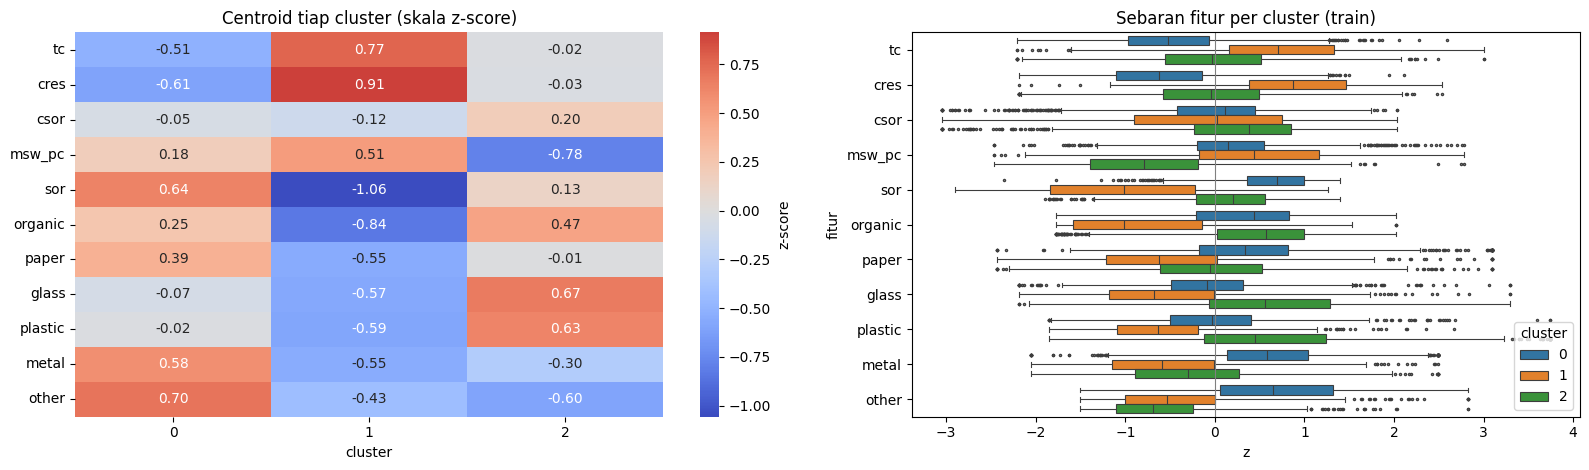

In [109]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

sns.heatmap(pusat.T, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[0],
            cbar_kws={"label": "z-score"})
axes[0].set_xlabel("cluster")
axes[0].set_title("Centroid tiap cluster (skala z-score)")

# Boxplot sebaran tiap fitur per cluster (skala z-score, data train)
panjang = X_train_s.assign(cluster=lab_train).melt(id_vars="cluster", var_name="fitur", value_name="z")
sns.boxplot(data=panjang, y="fitur", x="z", hue="cluster", palette="tab10", fliersize=1.5, linewidth=0.8, ax=axes[1])
axes[1].axvline(0, color="gray", lw=0.8)
axes[1].set_title("Sebaran fitur per cluster (train)")
axes[1].legend(title="cluster", loc="lower right")

plt.tight_layout()
plt.show()

### 5.7 Arti cluster terhadap masalah: pemeriksaan dengan variabel penjelas

Variabel penjelas (`geo`, `d_fee`, `urb_rev`, `region_impute`, dan lainnya) **tidak ikut membentuk cluster**. Karena itu hubungannya dengan cluster bisa dipakai untuk menafsirkan cluster dan menguji dugaan, misalnya apakah cluster mencerminkan wilayah geografis atau skema tarif PAYT. Ini **bukan** ground truth: nilai tinggi tidak berarti baseline "benar", dan nilai rendah tidak berarti "salah".

**Adjusted Mutual Information (AMI)** mengukur kesesuaian dua pengelompokan dan sudah dikoreksi dari kesesuaian kebetulan (0 = tidak berhubungan, 1 = identik). Dua variabel terakhir (`gap_flag`, `flag_imputasi`) adalah pemeriksaan artefak data: bila cluster sangat cocok dengannya, cluster itu mencerminkan cara data dicatat atau diisi, bukan pola pengelolaan sampah.

In [110]:
profil_tr = profil.loc[idx_train]

kandidat = ["geo", "region_impute", "d_fee", "urb_rev", "size_class", "sea", "isle", "gap_flag", "flag_imputasi"]
ami = {}
for v in kandidat:
    ada = profil_tr[v].notna()
    ami[v] = adjusted_mutual_info_score(profil_tr.loc[ada, v].astype(str), lab_train[ada])
print("AMI antara cluster baseline (train) dan variabel penjelas:")
print(pd.Series(ami).sort_values(ascending=False).round(3).to_string())

for v in ["geo", "d_fee", "urb_rev", "size_class"]:
    print(f"\nKomposisi tiap cluster menurut {v} (% baris dalam cluster):")
    print((pd.crosstab(lab_train, profil_tr[v], normalize="index") * 100).round(1).to_string())

AMI antara cluster baseline (train) dan variabel penjelas:
geo              0.185
region_impute    0.170
d_fee            0.070
sea              0.065
urb_rev          0.052
size_class       0.044
flag_imputasi    0.026
gap_flag         0.010
isle             0.005

Komposisi tiap cluster menurut geo (% baris dalam cluster):
geo       1.0   2.0   3.0
cluster                  
0         4.8   6.0  89.2
1        39.0  19.6  41.4
2        57.0  16.5  26.4

Komposisi tiap cluster menurut d_fee (% baris dalam cluster):
d_fee       0     1
cluster            
0        75.4  24.6
1        96.9   3.1
2        95.9   4.1

Komposisi tiap cluster menurut urb_rev (% baris dalam cluster):
urb_rev     1     2    3
cluster                 
0        40.4  54.0  5.6
1        51.2  39.3  9.5
2        75.6  23.0  1.4

Komposisi tiap cluster menurut size_class (% baris dalam cluster):
size_class  kecil  sedang  besar
cluster                         
0            54.5    38.6    6.8
1            51.6    29

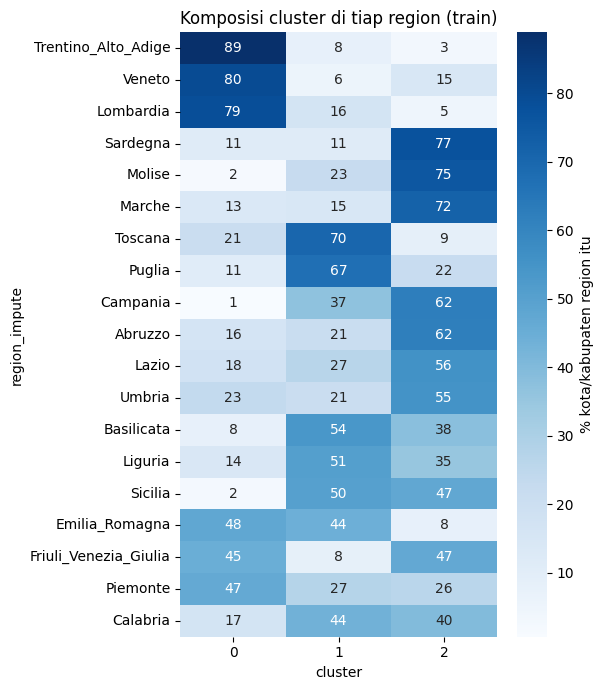

In [111]:
# Sebaran region di tiap cluster: persentase kota/kabupaten TIAP REGION yang masuk ke tiap cluster (baris = 100%)
tab_region = pd.crosstab(profil_tr["region_impute"], lab_train, normalize="index") * 100
tab_region = tab_region.loc[tab_region.max(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(6, 7))
sns.heatmap(tab_region, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% kota/kabupaten region itu"})
plt.xlabel("cluster")
plt.title("Komposisi cluster di tiap region (train)")
plt.tight_layout()
plt.show()

### 5.8 Visualisasi hasil cluster

Proyeksi PCA 2 dimensi dipakai **hanya untuk menggambar**: PCA di-`fit` pada train saja (data test tidak dipakai). Jarak pada gambar 2 dimensi tidak sama dengan jarak sebenarnya di 11 dimensi, jadi cluster yang tampak bertumpuk di sini belum tentu bertumpuk di ruang aslinya.

Varians yang dijelaskan: PC1 28.0%, PC2 15.2%, total 43.3%


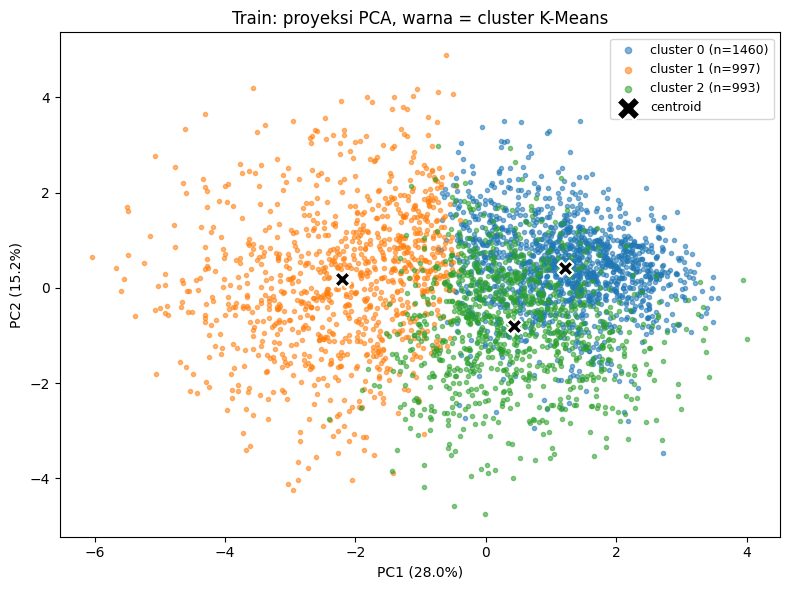

In [112]:
pca = PCA(n_components=2, random_state=SEED).fit(X_train_s)
P_train = pd.DataFrame(pca.transform(X_train_s), index=X_train_s.index, columns=["PC1", "PC2"])
P_pusat = pd.DataFrame(pca.transform(pusat), columns=["PC1", "PC2"])
ve = pca.explained_variance_ratio_
print(f"Varians yang dijelaskan: PC1 {ve[0]:.1%}, PC2 {ve[1]:.1%}, total {ve.sum():.1%}")

pal = sns.color_palette("tab10", K_BASELINE)
fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K_BASELINE):
    m_ = lab_train == c
    ax.scatter(P_train.loc[m_, "PC1"], P_train.loc[m_, "PC2"], s=9, alpha=0.55, color=pal[c], label=f"cluster {c} (n={m_.sum()})")
ax.scatter(P_pusat["PC1"], P_pusat["PC2"], marker="X", s=130, c="black", edgecolor="white", linewidth=1.5, label="centroid", zorder=5)
ax.set_title("Train: proyeksi PCA, warna = cluster K-Means")
ax.set_xlabel(f"PC1 ({ve[0]:.1%})")
ax.set_ylabel(f"PC2 ({ve[1]:.1%})")
ax.legend(markerscale=1.5, fontsize=9)
plt.tight_layout()
plt.show()


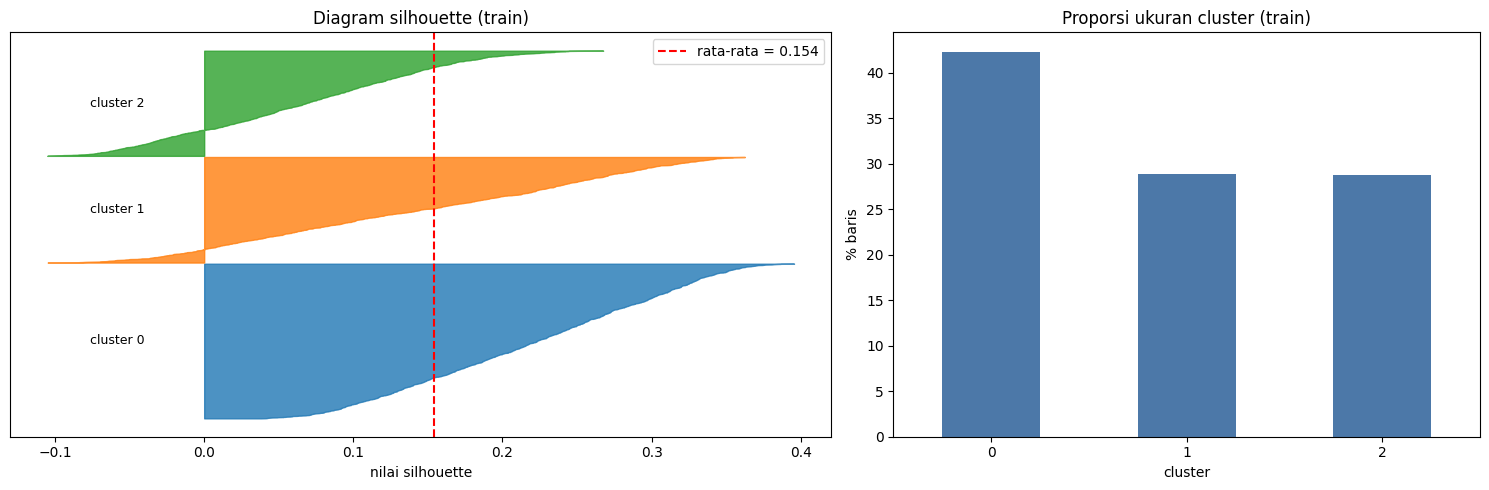

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})

# Diagram silhouette (train): lebar = jumlah titik, panjang = nilai silhouette tiap titik
ax = axes[0]
batas_bawah = 10
for c in range(K_BASELINE):
    sc = np.sort(s_train[lab_train.values == c])
    ax.fill_betweenx(np.arange(batas_bawah, batas_bawah + len(sc)), 0, sc, color=pal[c], alpha=0.8)
    ax.text(-0.04, batas_bawah + len(sc) / 2, f"cluster {c}", ha="right", va="center", fontsize=9)
    batas_bawah += len(sc) + 10
ax.axvline(m_train["silhouette"], color="red", ls="--", label=f"rata-rata = {m_train['silhouette']:.3f}")
ax.set_yticks([])
ax.set_xlabel("nilai silhouette")
ax.set_title("Diagram silhouette (train)")
ax.legend()

# Proporsi ukuran cluster (train)
(lab_train.value_counts(normalize=True).sort_index() * 100).plot.bar(ax=axes[1], rot=0, color="#4C78A8")
axes[1].set_xlabel("cluster")
axes[1].set_ylabel("% baris")
axes[1].set_title("Proporsi ukuran cluster (train)")

plt.tight_layout()
plt.show()


### 5.9 Ringkasan baseline (dibekukan)

Satu baris acuan berikut disimpan sebagai pembanding bagi semua tahap berikutnya. **Baseline tidak diubah lagi**, termasuk bila nanti ditemukan k yang lebih baik: hasil sapuan k menjadi entri baru, bukan pengganti baris ini.

In [114]:
baseline_ref = pd.DataFrame([{
    "model": "K-Means (baseline)", "k": K_BASELINE, "n_init": N_INIT, "seed": SEED,
    "n_train": len(X_train_s),
    "silhouette_train": m_train["silhouette"], "davies_bouldin_train": m_train["davies_bouldin"],
    "rasio_BW_train": m_train["rasio antar/dalam (B/W)"],
    "silhouette_cv_rata2": cv_hasil["silhouette"].mean(), "silhouette_cv_std": cv_hasil["silhouette"].std(ddof=1),
    "davies_bouldin_cv_rata2": cv_hasil["davies_bouldin"].mean(), "davies_bouldin_cv_std": cv_hasil["davies_bouldin"].std(ddof=1),
    "rasio_BW_cv_rata2": cv_hasil["rasio antar/dalam (B/W)"].mean(), "rasio_BW_cv_std": cv_hasil["rasio antar/dalam (B/W)"].std(ddof=1),
    "ARI_seed_rata2": np.mean(ari_seed), "ARI_subsampel_rata2": np.mean(ari_sub),
}]).set_index("model")
baseline_ref.to_csv("baseline_ref.csv")
baseline_ref.T.round(3)


model,K-Means (baseline)
k,3.000
n_init,10.000
seed,42.000
n_train,3450.000
silhouette_train,0.154
davies_bouldin_train,2.116
rasio_BW_train,0.368
silhouette_cv_rata2,0.155
silhouette_cv_std,0.008
davies_bouldin_cv_rata2,2.101


### 5.10 Temuan awal baseline

> Angka di bawah berasal dari eksekusi dengan `SEED = 42`. Jika versi library berbeda dan keluaran sel di atas sedikit berbeda, sesuaikan angkanya; kesimpulannya bergantung pada keluaran sel, bukan pada teks ini.

**Apa yang berhasil**

- **Prosedur bebas kebocoran.** Imputasi, winsorizing, dan z-score di-fit hanya pada train (4.5), dan split dilakukan sebelum ketiganya. Sebagai pembanding, fit pada seluruh data hanya menggeser parameter sangat kecil (selisih mean di bawah 0,02 std, kecuali batas P99 `paper` sekitar 0,13 std), jadi pada data ini kebocoran yang dicegah kecil. Prosedurnya tetap benar dan menutup pertanyaan itu secara empiris.
- **Skor validasi sejalan dengan skor latih.** Silhouette train penuh (dalam-sampel) 0,154 dan rata-rata fold validasi 0,155 ± 0,008 (rentang 0,145 sampai 0,166); Davies-Bouldin 2,10 ± 0,06 dan rasio B/W 0,371 ± 0,018. Silhouette fold latih (0,156) hampir sama dengan fold validasi (0,155), jadi tidak ada tanda overfit. Data test tidak dipakai.
- **Partisi dapat diulang.** ARI terhadap baseline 0,987 (seed berbeda, minimum 0,957) dan 0,934 (subsampel 80%, minimum 0,861).
- **Cluster bukan artefak pencatatan data.** AMI dengan `gap_flag` (0,010) dan `flag_imputasi` (0,026) praktis nol.
- **Cluster dapat ditafsirkan** (median pada satuan asli, data train):
  - *Cluster 0 (42%)*: pemilahan tinggi (`sor` 78,7%), biaya total paling rendah (`tc` 115,5 EUR), 89% kota berada di Utara; 24,6% PAYT.
  - *Cluster 1 (29%)*: biaya tertinggi (`tc` 185,3; `cres` 74,4), pemilahan terendah (`sor` 49,4%), sampah per kapita tertinggi (498 kg), porsi organik rendah (9,7%), kota paling besar (18,6% kelas besar), wilayah campuran (39% Selatan, 41% Utara).
  - *Cluster 2 (29%)*: kota kecil (79% kelas kecil, median penduduk 2.275), sampah per kapita rendah (335 kg), biaya menengah, porsi organik, kaca, dan plastik tinggi, 57% di Selatan.

  Secara ringkas, sumbu utama pembeda tampak sebagai gradien "biaya tinggi dan pemilahan rendah" (cluster 1) lawan "biaya rendah dan pemilahan tinggi" (cluster 0), dengan cluster 2 sebagai profil kota kecil dengan komposisi sampah berbeda.

**Masalah yang ditemukan**

- **Pemisahan cluster lemah.** Silhouette 0,154 (di bawah ambang kasar 0,25), Davies-Bouldin 2,12, dan 10,8% titik train berada lebih dekat ke cluster lain. Cluster 2 paling lemah (silhouette 0,066; 24,7% titik bersilhouette negatif) dan paling dekat ke cluster 0 (jarak centroid 2,34). Proyeksi PCA memperlihatkan titik yang bersambung dan saling tumpang tindih, bukan gugus terpisah (PCA 2 dimensi hanya menangkap 43,3% varians, jadi gambar ini bukan bukti tunggal).
- **Stabil belum berarti nyata.** ARI tinggi hanya menunjukkan K-Means memotong data dengan cara yang konsisten. Pada data yang berupa kontinum, pemotongan yang konsisten tetap mungkin, jadi stabilitas tidak membuktikan adanya kelompok alami.
- **Dugaan awal `k = 3` hanya sebagian didukung.** Hanya cluster 0 yang jelas berkaitan dengan wilayah Utara. AMI cluster terhadap `geo` hanya 0,185 dan terhadap `region_impute` 0,170, jadi cluster bukan sekadar pembagian geografis, dan juga bukan kecocokan satu lawan satu dengan tiga tingkat `geo`.
- **PAYT tidak boleh dibaca sebagai efek.** PAYT terkonsentrasi di cluster 0 (24,6% vs 3,1% dan 4,1%), tetapi cluster 0 juga hampir seluruhnya Utara. Seperti sudah ditunjukkan pada 3.2.1, PAYT dan wilayah saling bercampur, sehingga hubungan ini belum memisahkan keduanya.

**Kelemahan baseline**

- `k` dipilih a priori dan belum diuji terhadap alternatif.
- K-Means mengasumsikan cluster berbentuk bola dengan ukuran dan sebaran yang mirip, sedangkan data tampak berupa kontinum dengan kepadatan tidak merata.
- Semua fitur berbobot sama. `csor` hampir tidak membedakan cluster (selisih centroid antarcluster terbesar hanya sekitar 0,3 z-score), sehingga menambah derau tanpa menambah pemisahan. Karena fitur dipertahankan antartahap, ini dicatat sebagai keterbatasan, bukan diubah di sini.
- Evaluasi masih internal. Tanpa label, ukuran seperti silhouette tidak bisa menjawab apakah cluster berguna secara substantif.

**Yang perlu diperbaiki pada tahap berikutnya**

1. **Sapuan jumlah cluster** untuk K-Means dan semua kandidat dengan rentang dan metrik yang sama. Pilih k lewat 5-fold CV di dalam train memakai `cv_internal` dan fold yang sama (`baseline_folds_istat.csv`); data test hanya untuk pelaporan akhir. Simpangan baku antar-fold (silhouette sekitar 0,008 pada baseline) menjadi ambang derau: selisih antar-model yang jauh lebih kecil dari sekitar 0,02 sebaiknya tidak dianggap perbaikan nyata. Ini pedoman kasar karena hanya lima fold, bukan uji statistik.
2. **Kandidat metode** yang tidak mengasumsikan bentuk bola dan ukuran sama (misalnya GMM, hierarchical, DBSCAN), memakai split, fold, dan preprocessing yang sama persis (`baseline_split_istat.csv`, `baseline_folds_istat.csv`, kelas `PraprosesSampah`, fungsi `cv_internal`). Metode tanpa `predict` (DBSCAN, hierarchical) memerlukan aturan penugasan titik baru yang sama untuk semua metode.
3. **Bandingkan semua hasil terhadap `baseline_ref`** dengan tabel metrik yang sama (rata-rata ± simpangan baku antar-fold), ditambah stabilitas dan pemeriksaan variabel penjelas.

---
## 6. Kandidat Model

Bagian ini menguji **tiga kandidat metode** dan membandingkannya dengan baseline K-Means (bagian 5) dalam **satu tabel**. Bagian 1 sampai 4 tidak diubah; bagian 5 dan 6 direvisi agar data test **tidak dipakai untuk memilih atau mengevaluasi model**. Bagian 6 hanya memakai objek yang sudah ada (`X_train_s`, `X_pre`, `meta`, `fold_id`, `PraprosesSampah`, `metrik_internal`, `baseline_ref`). Jalankan bagian 0, 4, dan 5 lebih dulu.

**Aturan perbandingan yang setara**

| Aspek | Keputusan | Alasan |
|---|---|---|
| Data dan preprocessing | Sama persis dengan baseline: 11 fitur `FITUR`, `PraprosesSampah` di-fit hanya pada train, split 80:20 dan 5 fold yang dibekukan di 4.4 | Satu-satunya yang berbeda antar-model adalah algoritmanya |
| Metrik | Sama dengan baseline: silhouette, % silhouette < 0, Davies-Bouldin, SSE per sampel, rasio antar/dalam (B/W, pengganti Calinski-Harabasz yang bergantung pada n). Dilaporkan pada train (dalam-sampel) dan sebagai rata-rata ± simpangan baku 5-fold CV (fold validasi). Data test tidak dipakai | Perbandingan hanya adil bila diukur dengan penggaris yang sama |
| Hyperparameter | **Nilai dasar, tidak ada sapuan dan tidak ada tuning** (lihat tabel di bawah) | Sapuan hyperparameter dan sapuan jumlah cluster adalah tahap berikutnya, berlaku setara untuk semua model |
| Titik baru | Aturan **bawaan tiap model**; model tanpa `predict()` memakai 1-NN (DBSCAN: titik inti terdekat) (6.2) | Fold validasi memerlukan label untuk titik yang tidak dipakai melatih. Aturan ini **berbeda antar-model** dan memengaruhi besar selisih skor; efeknya diperiksa di 7.8 |

**Pemilihan kandidat.** Kelemahan baseline (5.10): K-Means mengasumsikan cluster berbentuk bola dengan ukuran dan sebaran mirip, sedangkan data tampak berupa kontinum dengan kepadatan tidak merata. Tiap kandidat dipilih karena menjawab satu kelemahan itu dengan cara yang berbeda:

| Kandidat | Mengapa relevan | Hyperparameter dasar dan justifikasi |
|---|---|---|
| **1. Gaussian Mixture (GMM)** | Mengizinkan cluster berbentuk elips dengan ukuran, orientasi, dan sebaran berbeda (`covariance_type='full'`), jadi langsung menguji asumsi "bola" milik K-Means. Memberi penugasan berbasis probabilitas, cocok untuk data kontinum | `n_components = 3` (alasan sama dengan baseline, lihat bawah). `covariance_type='full'` adalah **default** sklearn dan justru yang membedakannya dari K-Means. `n_init = 10` dan `random_state = 42` disamakan dengan baseline hanya agar jumlah restart dan keterulangan setara. Sisanya default (`max_iter=100`, `tol=1e-3`, `reg_covar=1e-6`, `init_params='kmeans'`) |
| **2. Hierarchical Agglomerative (Ward)** | Deterministik (tanpa inisialisasi acak), dan memakai tujuan yang sama dengan K-Means (meminimalkan sebaran dalam cluster) tetapi dengan strategi penggabungan bertahap. Bila hasilnya mirip baseline, struktur tersebut tidak bergantung pada cara optimasi K-Means; bila beda, K-Means kemungkinan terjebak pada optimum tertentu | `n_clusters = 3` (alasan sama dengan baseline). `linkage='ward'` dan jarak Euclidean adalah **default** |
| **3. DBSCAN** | Berbasis kepadatan: tidak mengasumsikan bentuk, tidak memaksa tiap titik masuk cluster (ada noise), dan jumlah cluster ditentukan data. Cocok untuk menguji dugaan "kepadatan tidak merata" | Tidak punya `k`. `min_samples = 2 × jumlah dimensi = 22` (aturan umum untuk data multidimensi). `eps` = **lutut kurva k-distance** (heuristik Ester dkk.), dihitung satu kali dari data latih dengan aturan tetap. Nilai bawaan sklearn (`eps=0.5`, `min_samples=5`) tidak dipakai karena pada data ini membuat hampir semua titik menjadi noise (diperiksa di 6.2) |

**Apakah tepat menyamakan nilai `k` untuk kandidat yang juga memakai `k`?** Untuk tahap ini, **ya**, dengan syarat dan batasan berikut:

1. **Menghindari pembaur.** Silhouette, Davies-Bouldin, dan B/W sangat dipengaruhi oleh jumlah cluster itu sendiri. Bila baseline memakai k = 3 dan GMM memakai k = 5, selisih skor tidak bisa dibaca sebagai selisih algoritma. Menyamakan k membuat perbedaan hasil dapat dikaitkan ke algoritmanya.
2. **Prinsip penetapan yang sama dengan baseline.** Baseline memakai k = 3 karena `geo` dan `urb_rev` memiliki tiga tingkat, sehingga tiga cluster mungkin memberi pemisahan alami. Prinsip yang sama dipakai untuk setiap hyperparameter jumlah-kelompok (`n_components` pada GMM, `n_clusters` pada Agglomerative), bukan angka yang diambil sembarang.
3. **Batasannya.** k = 3 adalah titik awal a priori, bukan nilai terbaik. Hasil bagian 5.10 sendiri menunjukkan dugaan ini hanya sebagian didukung. Karena itu, kesimpulan di bagian ini hanya berlaku untuk "pada k = 3". Pencarian k yang terbaik tetap tahap berikutnya dan dilakukan untuk semua model dengan rentang dan metrik yang sama.
4. **Kesetaraan k bukan kesetaraan kompleksitas.** Pada k yang sama, GMM `full` memiliki jauh lebih banyak parameter (66 parameter kovariansi per komponen pada 11 dimensi) daripada K-Means. Ini bagian dari sifat algoritmanya, dan dicatat saat membaca hasil.
5. **DBSCAN tidak mengikuti aturan ini** karena tidak punya `k`. Padanannya adalah `min_samples` dan `eps`, yang ditetapkan lewat aturan tetap di atas, bukan lewat pencarian.

### 6.1 Persiapan dan konstanta

Konstanta dikumpulkan di satu sel. `K_KANDIDAT` mengambil nilai `K_BASELINE` secara langsung, sehingga tidak mungkin berbeda dari baseline tanpa disengaja.

In [115]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# Hyperparameter dasar (dijustifikasi di tabel keputusan desain; TIDAK ada sapuan)
K_KANDIDAT = K_BASELINE            # jumlah cluster sama dengan baseline (k = 3), bukan hasil pencarian
D_FITUR = len(FITUR)               # jumlah dimensi = 11
MIN_SAMPLES_DBSCAN = 2 * D_FITUR   # aturan umum DBSCAN: min_samples = 2 x jumlah dimensi

print(f"k untuk GMM dan Agglomerative = {K_KANDIDAT} (sama dengan baseline)")
print(f"min_samples DBSCAN = 2 x {D_FITUR} dimensi = {MIN_SAMPLES_DBSCAN}")

k untuk GMM dan Agglomerative = 3 (sama dengan baseline)
min_samples DBSCAN = 2 x 11 dimensi = 22


### 6.2 Kandidat dan aturan penugasan titik baru

Semua kandidat dibungkus dengan antarmuka yang sama (`fit`, `labels_`, `predict`) supaya dapat dievaluasi oleh fungsi yang sama dengan baseline.

**Aturan penugasan titik baru** (diputuskan di 5.4 agar ditetapkan pada tahap kandidat):

| Model | Cara memberi label titik di luar data latih |
|---|---|
| GMM | `predict()` bawaan: komponen dengan probabilitas posterior tertinggi |
| Agglomerative | Tidak punya `predict()`. Titik baru diberi label **titik latih terdekat** (1-NN) |
| DBSCAN | Tidak punya `predict()`. Titik baru diberi label **titik inti terdekat** bila jaraknya ≤ `eps`; selain itu **noise** (`-1`), sesuai definisi DBSCAN |

**Penanganan noise.** Titik noise dikeluarkan dari perhitungan metrik dan dilaporkan terpisah sebagai `% noise`, karena silhouette dan Davies-Bouldin tidak terdefinisi untuk titik tanpa cluster. Bila suatu model hanya menghasilkan satu cluster, metrik ditulis `NaN` (tidak terdefinisi), bukan dipaksa menjadi angka.

Sel pertama di bawah berisi definisi tiap kandidat; sel kedua memeriksa nilai bawaan DBSCAN (satu kali jalan, bukan sapuan) untuk membenarkan aturan `eps`.

**Catatan.** Ini adalah aturan bawaan tiap model, **bukan satu aturan yang sama** untuk semua. Silhouette dan Davies-Bouldin memakai jarak Euclidean sehingga lebih sesuai untuk batas cluster ala K-Means (lurus); batas GMM yang melengkung bisa terkena penalti hanya karena bentuknya. Besar pengaruh ini diukur di 7.8.


In [116]:
# Setiap kandidat dibungkus dengan antarmuka yang sama: fit(X), labels_ (label train), predict(X) (label titik baru).
# Label -1 = noise (hanya mungkin pada DBSCAN).
# Argumen k / seed bersifat opsional: tanpa argumen, kelas berperilaku persis seperti di bagian 6 (k = 3, seed = 42).
# Argumen itu hanya dipakai oleh sapuan di bagian 7.

class KMeansKontrol:
    """K-Means lewat antarmuka bagian 6. Tanpa argumen = baseline (k = 3), dipakai untuk memeriksa bahwa fungsi
    evaluasi bagian 6 menghasilkan angka yang sama dengan bagian 5. Dengan k lain dipakai pada sapuan (bagian 7)."""
    def __init__(self, k=None, seed=None):
        self.k = K_BASELINE if k is None else k
        self.seed = SEED if seed is None else seed
    def fit(self, X):
        self.model = KMeans(n_clusters=self.k, n_init=N_INIT, random_state=self.seed).fit(np.asarray(X))
        self.labels_ = self.model.labels_
        return self
    def predict(self, X):
        return self.model.predict(np.asarray(X))


class GMMKandidat:
    """Gaussian Mixture: n_components = k, covariance_type='full' (default), parameter lain default."""
    def __init__(self, k=None, seed=None):
        self.k = K_KANDIDAT if k is None else k
        self.seed = SEED if seed is None else seed
    def fit(self, X):
        # n_init dan random_state disamakan dengan baseline (jumlah restart dan keterulangan), bukan tuning
        self.model = GaussianMixture(n_components=self.k, covariance_type="full",
                                     n_init=N_INIT, random_state=self.seed).fit(np.asarray(X))
        self.labels_ = self.model.predict(np.asarray(X))     # penugasan keras: komponen dengan probabilitas posterior tertinggi
        return self
    def predict(self, X):
        return self.model.predict(np.asarray(X))
    def ekstra(self, X_latih, X_val):
        """Pembanding bawaan GMM untuk sapuan k: BIC (data latih) dan log-likelihood per sampel (fold validasi)."""
        X_latih, X_val = np.asarray(X_latih), np.asarray(X_val)
        return {"BIC (latih, per sampel)": self.model.bic(X_latih) / len(X_latih),
                "log-likelihood validasi (per sampel)": self.model.score(X_val)}


class AgglomerativeKandidat:
    """Hierarchical agglomerative: n_clusters = k, linkage='ward', jarak Euclidean (semua default).
    Tidak punya predict(), sehingga titik baru diberi label titik latih terdekat (1-NN)."""
    def __init__(self, k=None):
        self.k = K_KANDIDAT if k is None else k
    def fit(self, X):
        X = np.asarray(X)
        self.labels_ = AgglomerativeClustering(n_clusters=self.k, linkage="ward").fit_predict(X)
        self.nn_ = NearestNeighbors(n_neighbors=1).fit(X)
        return self
    def predict(self, X):
        _, idx = self.nn_.kneighbors(np.asarray(X))
        return self.labels_[idx[:, 0]]


def eps_dari_knn(X, k):
    """Aturan eps DBSCAN tanpa sapuan: 'lutut' kurva k-distance (jarak ke tetangga ke-k, diurutkan naik).
    Lutut = titik yang paling jauh di bawah garis lurus dari ujung ke ujung kurva (kedua sumbu dinormalisasi).
    Dihitung hanya dari data latih, satu kali, tanpa melihat metrik evaluasi apa pun."""
    d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)     # tetangga ke-1 = titik itu sendiri, sesuai definisi min_samples sklearn
    kd = np.sort(d[:, -1])
    x = np.linspace(0, 1, len(kd))
    y = (kd - kd[0]) / (kd[-1] - kd[0])
    return float(kd[np.argmax(x - y)])


def eps_persentil(X, k, q):
    """eps = persentil ke-q dari jarak ke tetangga ke-k pada data latih (dipakai pada grid kecil bagian 7).
    Dihitung ulang dari data latih tiap fold, jadi tidak ada kebocoran."""
    d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    return float(np.percentile(d[:, -1], q))


class DBSCANKandidat:
    """DBSCAN: parameter lain default (metric Euclidean).
    Tanpa argumen: min_samples = 2 x dimensi, eps = lutut kurva k-distance (bagian 6).
    Dengan eps_pct / min_samples: eps = persentil ke-eps_pct dari k-distance (grid kecil bagian 7).
    Titik baru: label inti terdekat bila jaraknya <= eps, selain itu noise (-1), sesuai definisi DBSCAN."""
    def __init__(self, eps_pct=None, min_samples=None):
        self.eps_pct, self.min_samples = eps_pct, min_samples
    def fit(self, X):
        X = np.asarray(X)
        self.min_samples_ = MIN_SAMPLES_DBSCAN if self.min_samples is None else self.min_samples
        self.eps_ = eps_dari_knn(X, self.min_samples_) if self.eps_pct is None else eps_persentil(X, self.min_samples_, self.eps_pct)
        self.model = DBSCAN(eps=self.eps_, min_samples=self.min_samples_).fit(X)
        self.labels_ = self.model.labels_
        self.label_inti_ = self.labels_[self.model.core_sample_indices_]
        self.nn_ = NearestNeighbors(n_neighbors=1).fit(self.model.components_) if len(self.label_inti_) else None
        return self
    def predict(self, X):
        X = np.asarray(X)
        if self.nn_ is None:
            return np.full(len(X), -1)
        d, idx = self.nn_.kneighbors(X)
        return np.where(d[:, 0] <= self.eps_, self.label_inti_[idx[:, 0]], -1)
    def ekstra(self, X_latih, X_val):
        """Silhouette fold validasi bila noise dihitung sebagai kelompok sendiri (tidak dibuang).
        Silhouette biasa membuang noise, sehingga bisa terlalu menguntungkan DBSCAN."""
        lab = self.predict(X_val)
        ok = len(np.unique(lab)) >= 2
        return {"silhouette (noise = kelompok sendiri)": silhouette_score(np.asarray(X_val), lab) if ok else np.nan}


In [117]:
# Satu pemeriksaan (bukan sapuan) untuk membenarkan mengapa eps DBSCAN tidak memakai nilai bawaan sklearn:
# eps=0.5 dan min_samples=5 dirancang untuk data dengan skala jarak kecil, sedangkan 11 fitur z-score membuat
# jarak antar-tetangga jauh lebih besar.
db_bawaan = DBSCAN().fit(X_train_s.values)
print(f"DBSCAN bawaan sklearn (eps=0.5, min_samples=5): {len(set(db_bawaan.labels_)) - 1} cluster, "
      f"{100 * (db_bawaan.labels_ == -1).mean():.1f}% titik train menjadi noise")

# Skala jarak yang sebenarnya: jarak ke tetangga ke-22 (k-distance), ringkasan persentil
d22, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES_DBSCAN).fit(X_train_s.values).kneighbors(X_train_s.values)
print("Jarak ke tetangga ke-22 (train), persentil 10 / 50 / 90:",
      np.percentile(d22[:, -1], [10, 50, 90]).round(2).tolist())

DBSCAN bawaan sklearn (eps=0.5, min_samples=5): 1 cluster, 99.5% titik train menjadi noise
Jarak ke tetangga ke-22 (train), persentil 10 / 50 / 90: [1.38, 1.98, 2.78]


### 6.3 Fungsi evaluasi dan pemeriksaan konsistensi

`metrik_kandidat` memakai `metrik_internal` dari 5.3 apa adanya, ditambah SSE per sampel dan rasio B/W dengan rumus yang sama. Tanpa noise, hasilnya identik dengan bagian 5. `cv_kandidat` mengulang prosedur `cv_internal` (5.4): fold dibekukan, preprocessing di-fit ulang pada 4 fold latih, model dilatih di sana, fold sisanya diberi label lewat `predict()`. Data test tidak disentuh di CV.

**Pemeriksaan konsistensi:** sebelum menilai kandidat, baseline dijalankan melalui fungsi bagian 6 dan harus mereproduksi angka bagian 5. Bila tidak, ada `assert` yang gagal, sehingga selisih antara baseline dan kandidat tidak mungkin berasal dari perbedaan kode evaluasi.

In [118]:
def metrik_kandidat(X, lab, X_latih, lab_latih):
    """Metrik yang SAMA dengan baseline (metrik_internal + SSE per sampel + rasio B/W).
    Titik noise (-1) dikeluarkan dari perhitungan dan dilaporkan sebagai '% noise'.
    Bila kurang dari 2 cluster, metrik tidak terdefinisi (NaN). Tanpa noise, hasilnya identik dengan bagian 5.
    '% cluster terkecil' = porsi cluster terkecil dari titik non-noise (dipakai sebagai syarat ukuran minimum di bagian 7)."""
    X, lab = np.asarray(X), np.asarray(lab)
    ada = lab != -1
    kosong = {"silhouette": np.nan, "% sampel silhouette < 0": np.nan, "davies_bouldin": np.nan,
              "calinski_harabasz": np.nan, "SSE per sampel": np.nan, "rasio antar/dalam (B/W)": np.nan,
              "% cluster terkecil": np.nan}
    hasil = {"% noise": 100 * (~ada).mean(), "n_cluster": len(np.unique(lab[ada]))}
    if ada.any():
        _, cnt = np.unique(lab[ada], return_counts=True)
        hasil["% cluster terkecil"] = 100 * cnt.min() / ada.sum()
    kk = hasil["n_cluster"]
    if kk < 2 or ada.sum() <= kk:
        return {**kosong, **hasil}
    Xa, la = X[ada], lab[ada]
    hasil.update(metrik_internal(Xa, la))                      # fungsi baseline: silhouette, % < 0, DB, CH
    # SSE per sampel: jarak kuadrat ke pusat cluster hasil data LATIH (sama dengan inertia/score KMeans pada baseline)
    Xl, ll = np.asarray(X_latih), np.asarray(lab_latih)
    nama = np.unique(ll[ll != -1])
    pusat_l = np.vstack([Xl[ll == c].mean(axis=0) for c in nama])
    hasil["SSE per sampel"] = ((Xa - pusat_l[np.searchsorted(nama, la)]) ** 2).sum(axis=1).mean()
    hasil["rasio antar/dalam (B/W)"] = hasil["calinski_harabasz"] * (kk - 1) / (len(Xa) - kk)
    return {**kosong, **hasil}


def evaluasi_kandidat(buat_model):
    """Latih pada train penuh, lalu nilai pada train (dalam-sampel). Data test tidak dipakai."""
    model = buat_model().fit(X_train_s)
    lab_tr = np.asarray(model.labels_)
    m_tr = metrik_kandidat(X_train_s, lab_tr, X_train_s, lab_tr)
    return model, pd.Series(lab_tr, index=X_train_s.index), m_tr


def cv_kandidat(buat_model):
    """Cross-validation 5-fold di dalam train, persis prosedur 5.4: fold dibekukan (fold_id), preprocessing
    di-fit ulang pada 4 fold latih, model dilatih di sana, fold sisanya diberi label lewat predict().
    Fold validasi ini berperan sebagai validation set. Data test tidak disentuh."""
    baris, eps_fold = [], []
    for f in range(N_FOLD):
        i_va = fold_id.index[fold_id == f]
        i_tr = fold_id.index[fold_id != f]
        pp_f = buat_praproses().fit(X_pre.loc[i_tr], meta)
        Xtr, Xva = pp_f.transform(X_pre.loc[i_tr], meta), pp_f.transform(X_pre.loc[i_va], meta)
        model = buat_model().fit(Xtr)
        lab_tr, lab_va = np.asarray(model.labels_), np.asarray(model.predict(Xva))
        m = metrik_kandidat(Xva, lab_va, Xtr, lab_tr)
        m["silhouette (fold latih)"] = metrik_kandidat(Xtr, lab_tr, Xtr, lab_tr)["silhouette"]
        if hasattr(model, "ekstra"):                       # pembanding khusus model (BIC GMM, silhouette DBSCAN dengan noise)
            m.update(model.ekstra(Xtr, Xva))
        baris.append({"fold": f, "n_latih": len(Xtr), "n_validasi": len(Xva), **m})
        eps_fold.append(getattr(model, "eps_", np.nan))
    hasil = pd.DataFrame(baris).set_index("fold")
    hasil["eps"] = eps_fold
    return hasil


In [119]:
# Pemeriksaan konsistensi: baseline dijalankan lewat fungsi bagian 6 harus sama dengan angka bagian 5 (tanpa noise)
model_k, lab_k_tr, mk_tr = evaluasi_kandidat(KMeansKontrol)
cv_k = cv_kandidat(KMeansKontrol)

assert np.isclose(mk_tr["silhouette"], m_train["silhouette"])
assert np.isclose(mk_tr["davies_bouldin"], m_train["davies_bouldin"])
assert np.isclose(mk_tr["SSE per sampel"], m_train["SSE per sampel"], rtol=1e-3)   # selisih ~1e-6: pusat dari rata-rata label vs pusat akhir KMeans
assert np.isclose(mk_tr["rasio antar/dalam (B/W)"], m_train["rasio antar/dalam (B/W)"])
# CV: cocok per fold, bukan hanya rata-ratanya
assert np.allclose(cv_k["silhouette"].values, cv_hasil["silhouette"].values)
assert np.allclose(cv_k["davies_bouldin"].values, cv_hasil["davies_bouldin"].values)
assert np.allclose(cv_k["rasio antar/dalam (B/W)"].values, cv_hasil["rasio antar/dalam (B/W)"].values)
assert np.allclose(cv_k["% sampel silhouette < 0"].values, cv_hasil["% sampel silhouette < 0"].values)
print("OK: fungsi evaluasi bagian 6 mereproduksi angka baseline bagian 5 (train dan tiap fold CV).")
print(f"   silhouette train {mk_tr['silhouette']:.3f} | CV {cv_k['silhouette'].mean():.3f}")


OK: fungsi evaluasi bagian 6 mereproduksi angka baseline bagian 5 (train dan tiap fold CV).
   silhouette train 0.154 | CV 0.155


### 6.4 Menjalankan kandidat

Tiap kandidat dilatih pada train penuh (untuk angka train dan label cluster) dan dijalankan di 5-fold CV. Nomor cluster diurutkan menurut ukuran pada train (0 = terbesar), seperti 5.2. Tidak ada parameter yang diubah antar-jalan.

In [120]:
def urut_ukuran(lab_tr):
    """Nomor cluster diurutkan menurut ukuran pada train (0 = terbesar), seperti 5.2. Noise tetap -1."""
    besar = lab_tr[lab_tr != -1].value_counts().index.to_numpy()
    peta = {lama: baru for baru, lama in enumerate(besar)} | {-1: -1}
    return lab_tr.map(peta)


KANDIDAT = {
    "Kandidat 1: GMM":                  GMMKandidat,
    "Kandidat 2: Agglomerative (Ward)": AgglomerativeKandidat,
    "Kandidat 3: DBSCAN":               DBSCANKandidat,
}

hasil_kand = {}
for nama, kelas in KANDIDAT.items():
    model, lab_tr, m_tr = evaluasi_kandidat(kelas)
    lab_tr = urut_ukuran(lab_tr)
    hasil_kand[nama] = {"model": model, "lab_train": lab_tr, "m_train": m_tr, "cv": cv_kandidat(kelas)}

# Parameter akhir tiap kandidat (semua dasar; satu-satunya yang dihitung dari data adalah eps DBSCAN, lewat aturan tetap)
print("Parameter model:")
print("  GMM          :", {k: v for k, v in hasil_kand["Kandidat 1: GMM"]["model"].model.get_params().items()
                          if k in ("n_components", "covariance_type", "n_init", "max_iter", "tol", "reg_covar", "init_params", "random_state")})
print("  Agglomerative:", {"n_clusters": K_KANDIDAT, "linkage": "ward", "metric": "euclidean"}, "(semua default; k sama dengan baseline)")
db = hasil_kand["Kandidat 3: DBSCAN"]
print(f"  DBSCAN       : min_samples={MIN_SAMPLES_DBSCAN}, eps (train penuh) = {db['model'].eps_:.3f}, "
      f"eps per fold = {db['cv']['eps'].round(3).tolist()}")

# Konvergensi GMM (n_init = 10 restart)
print(f"\nGMM konvergen: {hasil_kand['Kandidat 1: GMM']['model'].model.converged_} "
      f"({hasil_kand['Kandidat 1: GMM']['model'].model.n_iter_} iterasi pada restart terbaik)")

print("\nUkuran cluster pada train dan jumlah cluster:")
for nama, h in hasil_kand.items():
    ut = h["lab_train"].value_counts().sort_index()
    print(f"  {nama}: train {ut.to_dict()}")


Parameter model:
  GMM          : {'covariance_type': 'full', 'init_params': 'kmeans', 'max_iter': 100, 'n_components': 3, 'n_init': 10, 'random_state': 42, 'reg_covar': 1e-06, 'tol': 0.001}
  Agglomerative: {'n_clusters': 3, 'linkage': 'ward', 'metric': 'euclidean'} (semua default; k sama dengan baseline)
  DBSCAN       : min_samples=22, eps (train penuh) = 2.737, eps per fold = [2.861, 2.824, 2.803, 2.821, 2.807]

GMM konvergen: True (14 iterasi pada restart terbaik)

Ukuran cluster pada train dan jumlah cluster:
  Kandidat 1: GMM: train {0: 1224, 1: 1201, 2: 1025}
  Kandidat 2: Agglomerative (Ward): train {0: 1523, 1: 1080, 2: 847}
  Kandidat 3: DBSCAN: train {-1: 62, 0: 3388}


### 6.5 Tabel perbandingan: baseline dan semua kandidat (k = 3)

Satu tabel untuk semua model, memuat **semua metrik yang dipakai baseline**. Setiap sel adalah rata-rata ± simpangan baku antar-fold (5-fold CV di dalam train, yang berperan sebagai *validation set*). **Data test tidak dipakai.**

Baris baseline dihitung lewat fungsi yang sama dengan kandidat (`cv_kandidat`) dan dicek persis sama dengan `baseline_ref` (5.9) pada tiga metrik yang dibekukan.

(*) **SSE per sampel hanya ditampilkan, tidak dipakai untuk menilai model.** K-Means meminimalkannya secara langsung, sehingga metrik ini condong ke baseline. Sel diberi "tidak terdefinisi" bila ada fold yang tidak punya minimal dua cluster. Tabel disimpan ke `kandidat_perbandingan.csv` (tampilan) dan `kandidat_perbandingan_angka.csv` (angka mentah).

In [121]:
METRIK_TABEL = [("Silhouette ↑", "silhouette"),
                ("% silhouette < 0 ↓", "% sampel silhouette < 0"),
                ("Davies-Bouldin ↓", "davies_bouldin"),
                ("Rasio B/W ↑", "rasio antar/dalam (B/W)"),
                ("SSE per sampel ↓ (*)", "SSE per sampel")]

def mean_sd(s):
    # rata-rata ± simpangan baku antar-fold; "tidak terdefinisi" bila ada fold yang NaN (bukan rata-rata parsial)
    return "tidak terdefinisi" if s.isna().any() else f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"

def rentang_int(s):
    return str(int(s.min())) if s.min() == s.max() else f"{int(s.min())}–{int(s.max())}"

def tabel_cv(daftar):
    """daftar: {nama model: DataFrame hasil cv_kandidat}. Satu baris per model."""
    baris = {}
    for nama, cv in daftar.items():
        r = {lab: mean_sd(cv[kol]) for lab, kol in METRIK_TABEL}
        r["Jumlah cluster"] = rentang_int(cv["n_cluster"])
        r["% noise"] = f"{cv['% noise'].mean():.1f}"
        baris[nama] = r
    return pd.DataFrame(baris).T.rename_axis("Model")

def tabel_angka(daftar):
    baris = {}
    for nama, cv in daftar.items():
        r = {}
        for lab, kol in METRIK_TABEL:
            r[f"{kol}_rata2"] = cv[kol].mean(skipna=False)
            r[f"{kol}_std"] = cv[kol].std(ddof=1, skipna=False)
        baris[nama] = r
    return pd.DataFrame(baris).T.rename_axis("Model")

def tabel_per_fold(daftar, kol):
    """Format tabel materi: satu baris per model; kolom Fold 1 sampai 5, Rata-rata, dan Standar deviasi."""
    kol_fold = [f"Fold {i + 1}" for i in range(N_FOLD)]
    d = pd.DataFrame({nama: cv[kol].values for nama, cv in daftar.items()}, index=kol_fold).T
    d["Rata-rata"] = d[kol_fold].mean(axis=1, skipna=False)
    d["Standar deviasi"] = d[kol_fold].std(axis=1, ddof=1, skipna=False)
    d.index.name = "Model"
    return d.apply(lambda c: c.map(lambda x: "tidak terdefinisi" if pd.isna(x) else f"{x:.3f}"))

def selisih_berpasangan(daftar, kol, acuan="Baseline: K-Means (k=3)"):
    """Selisih per fold terhadap baseline. Fold-nya sama, jadi selisih bisa dihitung berpasangan.
    Format sama dengan tabel_per_fold (baris = model, kolom = Fold 1 sampai 5, Rata-rata, Standar deviasi)."""
    kol_fold = [f"Fold {i + 1}" for i in range(N_FOLD)]
    d = pd.DataFrame({nama: cv[kol].values - daftar[acuan][kol].values for nama, cv in daftar.items() if nama != acuan},
                     index=kol_fold).T
    d["Rata-rata"] = d[kol_fold].mean(axis=1, skipna=False)
    d["Standar deviasi"] = d[kol_fold].std(axis=1, ddof=1, skipna=False)
    d.index.name = "Model"
    return d.apply(lambda c: c.map(lambda x: "tidak terdefinisi" if pd.isna(x) else f"{x:+.3f}"))

def cetak_per_fold(daftar, simpan=None):
    """Satu tabel per metrik (kelima metrik di METRIK_TABEL), format tabel per fold. Opsional disimpan ke CSV."""
    semua = []
    for lab, kol in METRIK_TABEL:
        t = tabel_per_fold(daftar, kol)
        print(f"\n=== {lab}: skor per fold ===")
        print(t.to_string())
        semua.append(t.reset_index().assign(Metrik=lab))
    if simpan:
        pd.concat(semua).to_csv(simpan, index=False)

# Baris baseline dari cv_k (fungsi yang sama dengan kandidat); cocokkan dengan baseline_ref yang dibekukan (5.9)
b = baseline_ref.iloc[0]
assert np.isclose(cv_k["silhouette"].mean(), b["silhouette_cv_rata2"]) and np.isclose(cv_k["silhouette"].std(ddof=1), b["silhouette_cv_std"])
assert np.isclose(cv_k["davies_bouldin"].mean(), b["davies_bouldin_cv_rata2"]) and np.isclose(cv_k["davies_bouldin"].std(ddof=1), b["davies_bouldin_cv_std"])
assert np.isclose(cv_k["rasio antar/dalam (B/W)"].mean(), b["rasio_BW_cv_rata2"]) and np.isclose(cv_k["rasio antar/dalam (B/W)"].std(ddof=1), b["rasio_BW_cv_std"])

CV_K3 = {"Baseline: K-Means (k=3)": cv_k, **{nama: h["cv"] for nama, h in hasil_kand.items()}}
tabel_banding = tabel_cv(CV_K3)
tabel_banding.to_csv("kandidat_perbandingan.csv")
tabel_angka(CV_K3).to_csv("kandidat_perbandingan_angka.csv")

print("Arah metrik: ↑ tinggi = baik | ↓ rendah = baik. Sel = rata-rata ± simpangan baku 5-fold CV (validation set). Test tidak dipakai.\n")
print(tabel_banding.T.to_string())


Arah metrik: ↑ tinggi = baik | ↓ rendah = baik. Sel = rata-rata ± simpangan baku 5-fold CV (validation set). Test tidak dipakai.

Model                Baseline: K-Means (k=3) Kandidat 1: GMM Kandidat 2: Agglomerative (Ward) Kandidat 3: DBSCAN
Silhouette ↑                   0.155 ± 0.008   0.080 ± 0.007                    0.092 ± 0.013  tidak terdefinisi
% silhouette < 0 ↓            10.522 ± 1.327  40.087 ± 2.532                  32.435 ± 10.050  tidak terdefinisi
Davies-Bouldin ↓               2.101 ± 0.063   2.768 ± 0.102                    2.581 ± 0.199  tidak terdefinisi
Rasio B/W ↑                    0.371 ± 0.018   0.222 ± 0.013                    0.247 ± 0.018  tidak terdefinisi
SSE per sampel ↓ (*)           8.061 ± 0.254   9.047 ± 0.341                    8.856 ± 0.381  tidak terdefinisi
Jumlah cluster                             3               3                                3                  1
% noise                                  0.0             0.0                   

#### Tabel per fold (format materi) dan selisih berpasangan

Tabel per fold dibuat **untuk kelima metrik** (Silhouette, % silhouette < 0, Davies-Bouldin, Rasio B/W, SSE per sampel), satu tabel per metrik. Tiap tabel mengikuti format materi: **baris = model**, **kolom = Fold 1 sampai 5, Rata-rata, dan Standar deviasi**. Semua tabel juga disimpan ke `kandidat_perfold.csv`. Karena fold-nya **sama** untuk semua model, selisih terhadap baseline bisa dihitung **per fold** (berpasangan) untuk dua metrik utama (Silhouette dan Davies-Bouldin; pada Davies-Bouldin selisih negatif berarti lebih baik). Selisih yang bertanda sama di kelima fold lebih meyakinkan daripada membandingkan dua simpangan baku terpisah. Lima fold bukan uji statistik dan fold latihnya saling tumpang tindih, jadi ini tetap pedoman kasar. SSE per sampel hanya ditampilkan (condong ke K-Means).


In [122]:
cetak_per_fold(CV_K3, simpan="kandidat_perfold.csv")

for lab, kol in [("Silhouette ↑", "silhouette"), ("Davies-Bouldin ↓", "davies_bouldin")]:
    print(f"\n=== Selisih {lab} per fold terhadap baseline (kandidat - baseline) ===")
    print(selisih_berpasangan(CV_K3, kol).to_string())



=== Silhouette ↑: skor per fold ===
                                             Fold 1             Fold 2             Fold 3             Fold 4             Fold 5          Rata-rata    Standar deviasi
Model                                                                                                                                                                
Baseline: K-Means (k=3)                       0.166              0.153              0.157              0.155              0.145              0.155              0.008
Kandidat 1: GMM                               0.092              0.072              0.078              0.079              0.080              0.080              0.007
Kandidat 2: Agglomerative (Ward)              0.091              0.090              0.108              0.099              0.074              0.092              0.013
Kandidat 3: DBSCAN                tidak terdefinisi  tidak terdefinisi  tidak terdefinisi  tidak terdefinisi  tidak terdefinisi  tida

### 6.6 Rincian tambahan: metrik lengkap, kesepakatan antar-partisi, dan variabel penjelas

Tiga pemeriksaan melengkapi tabel utama:

1. **Metrik lengkap 5.3** (termasuk % sampel silhouette < 0 dan SSE per sampel) pada train (dalam-sampel). Data test tidak dipakai.
2. **ARI antar-partisi** (train): seberapa mirip pengelompokan antar-model. Nilai rendah berarti hasil sangat bergantung pada algoritma.
3. **AMI dengan variabel penjelas** (seperti 5.7). Ini bukan ground truth dan tidak dipakai untuk memilih model; hanya melihat apakah cluster kandidat menangkap hal yang berbeda dari baseline. Model dengan kurang dari 2 cluster dilewati.

In [123]:
kolom_eval = ["silhouette", "% sampel silhouette < 0", "davies_bouldin", "SSE per sampel", "rasio antar/dalam (B/W)"]

# Rincian tambahan: metrik lain dari 5.3 pada train (dalam-sampel), supaya semua metrik baseline punya pasangan di kandidat
rinci = {"Baseline: K-Means (k=3)": pd.Series(m_train).reindex(kolom_eval)}
for nama, h in hasil_kand.items():
    rinci[nama] = pd.Series(h["m_train"])[kolom_eval]
print("Metrik lengkap 5.3 (train, dalam-sampel):")
print(pd.DataFrame(rinci).T.round(3).to_string())

# Kesesuaian partisi dengan baseline dan dengan variabel penjelas (seperti 5.7). Noise dihitung sebagai kelompok tersendiri.
peta_lab = {"Baseline: K-Means (k=3)": lab_train, **{n: h["lab_train"] for n, h in hasil_kand.items()}}
ada_cl = {n: l[l != -1].nunique() >= 2 for n, l in peta_lab.items()}

print("\nARI antar-partisi (train):")
nama_ = list(peta_lab)
ari = pd.DataFrame([[adjusted_rand_score(peta_lab[a], peta_lab[c]) if ada_cl[a] and ada_cl[c] else np.nan
                     for c in nama_] for a in nama_], index=nama_, columns=nama_)
print(ari.round(3).to_string())

print("\nAMI antara cluster dan variabel penjelas (train; hanya model dengan >= 2 cluster):")
ami_semua = {}
for n, l in peta_lab.items():
    if not ada_cl[n]:
        continue
    r = {}
    for v in kandidat:                       # daftar variabel penjelas yang sama dengan 5.7
        ada = profil_tr[v].notna()
        r[v] = adjusted_mutual_info_score(profil_tr.loc[ada, v].astype(str), l[ada])
    ami_semua[n] = r
print(pd.DataFrame(ami_semua).round(3).to_string())

Metrik lengkap 5.3 (train, dalam-sampel):
                                  silhouette  % sampel silhouette < 0  davies_bouldin  SSE per sampel  rasio antar/dalam (B/W)
Baseline: K-Means (k=3)                0.154                   10.812           2.116           8.038                    0.368
Kandidat 1: GMM                        0.082                   40.029           2.783           9.028                    0.218
Kandidat 2: Agglomerative (Ward)       0.087                   26.261           2.450           8.807                    0.249
Kandidat 3: DBSCAN                       NaN                      NaN             NaN             NaN                      NaN

ARI antar-partisi (train):
                                  Baseline: K-Means (k=3)  Kandidat 1: GMM  Kandidat 2: Agglomerative (Ward)  Kandidat 3: DBSCAN
Baseline: K-Means (k=3)                             1.000            0.307                             0.318                 NaN
Kandidat 1: GMM                      

### 6.7 Visualisasi

Proyeksi PCA 2D dari 5.8 (di-fit pada train), diwarnai menurut label tiap model. Seperti di 5.8, gambar 2 dimensi hanya menangkap 43,3% varians sehingga bukan bukti tunggal. Titik noise DBSCAN ditandai dengan `x`.

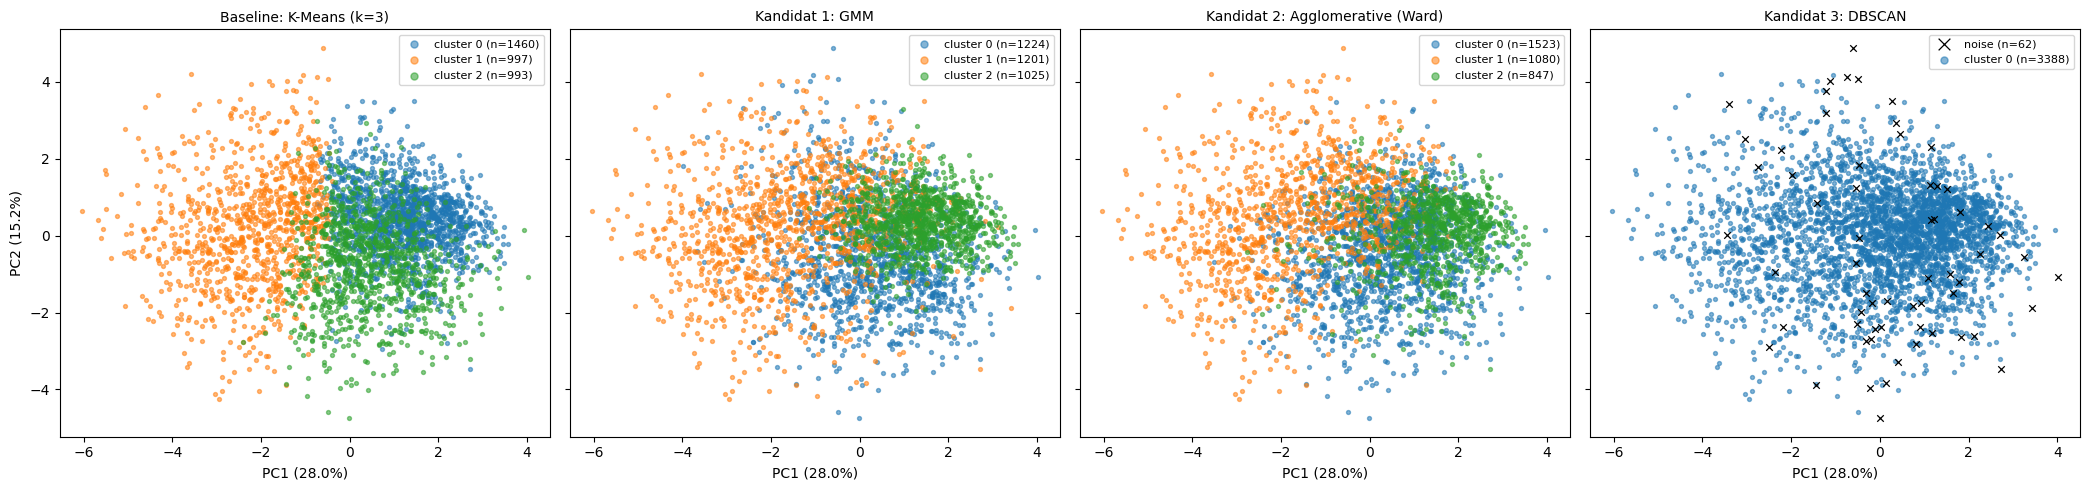

In [124]:
# Proyeksi PCA 2D (PCA dari 5.8, di-fit pada train). Hanya untuk menggambar.
panel = [("Baseline: K-Means (k=3)", lab_train)] + [(n, h["lab_train"]) for n, h in hasil_kand.items()]
fig, axes = plt.subplots(1, 4, figsize=(21, 5), sharex=True, sharey=True)
for ax, (nama, lab) in zip(axes, panel):
    noise = lab.values == -1
    if noise.any():
        ax.scatter(P_train.loc[noise, "PC1"], P_train.loc[noise, "PC2"], s=22, color="black", marker="x",
                   linewidths=0.9, label=f"noise (n={noise.sum()})", zorder=4)
    for c in sorted(set(lab.values) - {-1}):
        m_ = lab.values == c
        ax.scatter(P_train.loc[m_, "PC1"], P_train.loc[m_, "PC2"], s=8, alpha=0.55, color=pal[c % len(pal)],
                   label=f"cluster {c} (n={m_.sum()})")
    ax.set_title(nama, fontsize=10)
    ax.set_xlabel(f"PC1 ({ve[0]:.1%})")
    ax.legend(markerscale=1.8, fontsize=8)
axes[0].set_ylabel(f"PC2 ({ve[1]:.1%})")
plt.tight_layout()
plt.show()

### 6.8 Temuan kandidat

> Angka di bawah berasal dari eksekusi dengan `SEED = 42` (scikit-learn 1.9). Jika versi library berbeda dan keluaran sel di atas sedikit berbeda, sesuaikan angkanya; kesimpulannya bergantung pada keluaran sel, bukan pada teks ini. **Semua angka berasal dari train dan fold validasi (5-fold CV); data test tidak dipakai untuk memilih atau mengevaluasi model.**

**Ringkasan tabel (k = 3, hyperparameter dasar, tanpa tuning)**

| Model | Silhouette (CV) ↑ | % silhouette < 0 (CV) ↓ | Davies-Bouldin (CV) ↓ | Rasio B/W (CV) ↑ | Jumlah cluster | % noise |
|---|---|---|---|---|---|---|
| Baseline: K-Means | 0,155 ± 0,008 | 10,5 ± 1,3 | 2,101 ± 0,063 | 0,371 ± 0,018 | 3 | 0,0 |
| Kandidat 1: GMM | 0,080 ± 0,007 | 40,1 ± 2,5 | 2,768 ± 0,102 | 0,222 ± 0,013 | 3 | 0,0 |
| Kandidat 2: Agglomerative (Ward) | 0,092 ± 0,013 | 32,4 ± 10,1 | 2,581 ± 0,199 | 0,247 ± 0,018 | 3 | 0,0 |
| Kandidat 3: DBSCAN | tidak terdefinisi | tidak terdefinisi | tidak terdefinisi | tidak terdefinisi | 1 | 1,7 |

**Yang ditemukan**

- **Tidak ada kandidat yang mengalahkan baseline pada metrik utama.** Selisih silhouette terhadap baseline negatif di **kelima fold**: GMM −0,066 sampai −0,081 (rata-rata −0,075) dan Agglomerative −0,049 sampai −0,076 (rata-rata −0,063). Selisih ini jauh di atas pedoman derau 0,02, dan pola yang sama terlihat pada Davies-Bouldin, rasio B/W, dan % silhouette negatif.
- **Titik yang salah tempat jauh lebih banyak.** Proporsi sampel dengan silhouette negatif pada train (dalam-sampel): 40,0% (GMM) dan 26,3% (Agglomerative) vs 10,8% (baseline).
- **Pemisahan lemah bukan khas K-Means.** Ketiga metode yang menghasilkan cluster berada di bawah ambang kasar 0,25, dan proyeksi PCA (6.7) memperlihatkan titik yang bersambung pada semua metode. Ini memperkuat temuan 5.10 bahwa data lebih mirip kontinum daripada gugus terpisah.
- **Partisi sangat bergantung pada algoritma.** ARI antar-partisi hanya sekitar 0,31 (baseline–GMM 0,307, baseline–Agglomerative 0,318, GMM–Agglomerative 0,306). Tiga metode memotong kontinum yang sama dengan cara berbeda, dan tidak ada pengelompokan "konsensus" pada k = 3. Cluster kandidat juga tidak lebih selaras dengan wilayah: AMI terhadap `geo` 0,130 (GMM) dan 0,121 (Agglomerative) vs 0,185 (baseline). Beberapa variabel penjelas memiliki AMI sedikit lebih tinggi pada model kandidat, terutama size_class (GMM 0,092 dan Agglomerative 0,065 dibanding baseline 0,044). Selain itu, terdapat peningkatan kecil pada beberapa variabel lain, seperti urb_rev, flag_imputasi, sea, dan gap_flag, bergantung pada modelnya. Namun, seluruh nilai AMI tersebut relatif rendah sehingga belum dapat dianggap sebagai bukti keterkaitan yang kuat.
- **DBSCAN hanya menemukan satu cluster.** Dengan `min_samples = 22` dan `eps` dari lutut kurva k-distance (sekitar 2,7 pada train, 2,80 sampai 2,86 per fold), DBSCAN menggabungkan hampir semua titik menjadi satu komponen padat dan hanya menandai sekitar 1,7% titik sebagai noise (pencilan di tepi sebaran). Metrik tidak terdefinisi pada satu cluster, jadi baris ini tidak bisa dibandingkan angka demi angka. Nilai bawaan sklearn tidak lebih baik: 99,5% titik menjadi noise (6.2). Grid kecil di 7.5 menguji pengaturan lain.

**Batasan yang perlu diingat saat membaca tabel**

- **Metrik condong ke baseline.** Silhouette, Davies-Bouldin, B/W, dan SSE mengukur kekompakan geometris cluster berbentuk bola. K-Means secara langsung meminimalkan SSE, sedangkan GMM memaksimalkan likelihood dan Ward memakai kriteria penggabungan bertahap. Jadi keunggulan baseline sebagian bawaan dari tujuan optimasinya, dan tidak serta-merta berarti cluster K-Means lebih bermakna. Metrik yang sama tetap dipakai karena itu syarat perbandingan setara.
- **Aturan penugasan titik baru berbeda antar-model** (6.2): K-Means ke centroid terdekat, GMM ke posterior tertinggi, Ward ke 1-NN. Karena metrik memakai jarak Euclidean, besar selisih skor ikut dipengaruhi aturan ini, tidak hanya algoritmanya. Pengaruhnya diukur di 7.8.
- **Hanya k = 3.** Kesimpulan di sini tidak menyatakan GMM atau Ward lebih buruk pada k terbaiknya masing-masing; sapuan k dikerjakan di bagian 7.
- **Lima fold bukan uji statistik**, dan fold latihnya saling tumpang tindih. Simpangan baku antar-fold dan selisih berpasangan dipakai sebagai pedoman kasar.
- **Evaluasi masih internal.** Seperti baseline, tabel belum menjawab apakah cluster berguna secara substantif.


---
## 7. Sapuan Jumlah Cluster dan Parameter DBSCAN

Bagian 6 membandingkan semua model pada satu nilai k yang sama (k = 3). Bagian ini menanyakan: **bagaimana bila k berbeda?** Semua model disapu dengan prosedur yang sama, memakai `cv_kandidat`, fold yang sama, dan preprocessing yang di-fit ulang pada tiap fold latih.

**Keputusan desain**

| Aspek | Keputusan | Alasan |
|---|---|---|
| Data test | **Tidak dipakai untuk memilih atau mengevaluasi model** di bagian 5, 6, dan 7 (hanya diperiksa secara deskriptif di 4.4 sampai 4.6) | Sesuai materi: validation set (5-fold CV di dalam train) untuk memilih konfigurasi dan membandingkan kandidat; test set hanya untuk mengevaluasi model terpilih pada tahap akhir. Karena belum ada model terpilih final, test belum dipakai untuk evaluasi |
| Yang disapu: K-Means, GMM, Ward | Hanya jumlah cluster `k = 2 sampai 8`, rentang sama untuk semua | Satu hyperparameter dengan rentang kecil. Hyperparameter lain tetap seperti bagian 6 (tanpa tuning) |
| Yang disapu: DBSCAN | Grid kecil 4 × 4 = 16 konfigurasi: `min_samples` ∈ {5, 11, 22, 44} (5 = bawaan sklearn; 11, 22, 44 = 1×, 2×, 4× jumlah dimensi) dan `eps` = persentil ke-{20, 40, 60, 80} dari k-distance data latih | DBSCAN tidak punya k; padanannya adalah `eps` dan `min_samples`. `eps` sebagai persentil dihitung ulang dari data latih tiap fold. Persentil 20 sampai 80 mencakup dari noise tinggi (sekitar 60% sampai 70%) sampai noise rendah (sekitar 2% sampai 10%). Rentang diperiksa pada data latih hanya lewat jumlah cluster dan noise, bukan skor. Grid tidak diperhalus: tujuannya memeriksa ada tidaknya struktur berbasis kepadatan, bukan mengoptimalkan DBSCAN |
| Evaluasi | Metrik yang sama dengan bagian 6, pada fold validasi | Perbandingan setara |
| Aturan memilih k untuk K-Means, GMM, Ward (**aturan utama, ditetapkan sebelum menjalankan**) | (1) **Filter ukuran:** hanya k dengan cluster terkecil ≥ 5% titik (rata-rata fold validasi). (2) Ambil k dengan **silhouette CV** tertinggi. (3) Bila ada k yang lebih kecil dengan silhouette dalam satu simpangan baku dari yang tertinggi, pilih k terkecil itu. (4) Davies-Bouldin, rasio B/W, dan elbow/BIC dicek apakah searah dan ketidaksesuaian dicatat | Mencegah cluster yang nyaris tidak berarti dan memilih k paling sederhana bila selisihnya masih dalam derau |
| Analisis eksploratif: skor gabungan (**ditambahkan setelah melihat hasil aturan utama**) | Pada k yang lolos filter ukuran, tiga komponen dinormalkan min-max ke 0 sampai 1 (1 = terbaik): silhouette CV ↑, Davies-Bouldin CV ↓, dan kriteria internal model, yaitu kekuatan siku SSE per sampel fold validasi untuk K-Means dan Ward, atau BIC latih ↓ untuk GMM. Skor gabungan = rata-rata ketiganya (bobot sama); seri dipilih k terkecil. Rasio B/W dan % silhouette < 0 tidak dimasukkan | **Keterbukaan:** dirumuskan setelah aturan utama memilih k = 2 untuk ketiga model, karena silhouette condong ke k kecil. Karena dirumuskan setelah melihat hasil, analisis ini hanya sensitivitas dan **tidak menggantikan aturan utama**. Komponen siku bernilai 0 di ujung rentang sehingga secara bawaan merugikan k = 2; bobot sama adalah penyederhanaan, jadi 7.6 menampilkan semua komponen |
| Aturan konfigurasi DBSCAN | Layak bila di setiap fold ada ≥ 2 cluster, cluster terkecil ≥ 5% titik non-noise, dan noise ≤ 20%. Dari yang layak diambil silhouette CV tertinggi. Bila tidak ada yang layak, DBSCAN dilaporkan tanpa konfigurasi terpilih | Syarat ukuran sama dengan model lain. Silhouette DBSCAN membuang noise sehingga bisa menguntungkan; syarat noise dan ukuran mencegah konfigurasi yang hanya menyisakan segelintir titik |

**Catatan penting.** Baseline K-Means k = 3 tetap **dibekukan** (bagian 5.9). Hasil sapuan adalah entri baru, bukan pengganti. Silhouette cenderung tertinggi pada k kecil (terutama k = 2) karena memotong data menjadi dua bagian itu mudah; hasil tersebut adalah sifat metrik, belum tentu pola yang bermakna. Karena itu skor gabungan ditambahkan sebagai analisis eksploratif, dan perbandingan antara k yang berbeda (mis. k = 2 dengan baseline k = 3) tetap dibaca hati-hati.

### 7.1 Persiapan dan konstanta

Rentang dan syarat dikumpulkan di satu sel, ditetapkan **sebelum** menjalankan sapuan.

In [125]:
# Rentang dan syarat sapuan (ditetapkan sebelum menjalankan; lihat tabel keputusan di atas)
K_RENTANG = list(range(2, 9))                              # k = 2..8, sama untuk semua model
EPS_PERSENTIL = [20, 40, 60, 80]                           # eps DBSCAN = persentil ke-q dari k-distance data latih
MIN_SAMPLES_GRID = [5, D_FITUR, 2 * D_FITUR, 4 * D_FITUR]  # 5 (bawaan sklearn), 11, 22, 44 (1x, 2x, 4x jumlah dimensi)
SYARAT_UKURAN_MIN = 5.0                                    # % cluster terkecil minimal
SYARAT_NOISE_MAKS = 20.0                                   # % noise maksimal (DBSCAN)

print(f"k disapu: {K_RENTANG[0]} sampai {K_RENTANG[-1]} untuk K-Means, GMM, Agglomerative (Ward)")
print(f"DBSCAN: min_samples {MIN_SAMPLES_GRID} x eps persentil {EPS_PERSENTIL} = {len(MIN_SAMPLES_GRID) * len(EPS_PERSENTIL)} konfigurasi")


k disapu: 2 sampai 8 untuk K-Means, GMM, Agglomerative (Ward)
DBSCAN: min_samples [5, 11, 22, 44] x eps persentil [20, 40, 60, 80] = 16 konfigurasi


### 7.2 Menjalankan sapuan k (K-Means, GMM, Agglomerative)

Tiap kombinasi (model, k) dijalankan lewat `cv_kandidat`: 5 fold yang sama, preprocessing di-fit ulang pada 4 fold latih, label fold validasi lewat aturan bawaan tiap model. **Hanya skor fold validasi yang dihitung**; tidak ada skor test.

Sebagai pemeriksaan, hasil pada k = 3 harus sama persis dengan bagian 6.

In [126]:
MODEL_K = {"K-Means": KMeansKontrol, "GMM": GMMKandidat, "Agglomerative (Ward)": AgglomerativeKandidat}

cv_sapuan = {}
for nama, kelas in MODEL_K.items():
    for k in K_RENTANG:
        cv_sapuan[(nama, k)] = cv_kandidat(lambda kelas=kelas, k=k: kelas(k=k))

# Konsistensi: k = 3 pada sapuan harus identik dengan bagian 6
assert np.allclose(cv_sapuan[("K-Means", 3)]["silhouette"].values, cv_k["silhouette"].values)
assert np.allclose(cv_sapuan[("GMM", 3)]["silhouette"].values, hasil_kand["Kandidat 1: GMM"]["cv"]["silhouette"].values)
assert np.allclose(cv_sapuan[("Agglomerative (Ward)", 3)]["silhouette"].values,
                   hasil_kand["Kandidat 2: Agglomerative (Ward)"]["cv"]["silhouette"].values)
print("OK: hasil sapuan pada k = 3 sama dengan bagian 6.\n")

def ringkas_sapuan(nama):
    baris = {}
    for k in K_RENTANG:
        cv = cv_sapuan[(nama, k)]
        r = {"sil_rata2": cv["silhouette"].mean(), "sil_std": cv["silhouette"].std(ddof=1),
             "db_rata2": cv["davies_bouldin"].mean(), "db_std": cv["davies_bouldin"].std(ddof=1),
             "bw_rata2": cv["rasio antar/dalam (B/W)"].mean(), "bw_std": cv["rasio antar/dalam (B/W)"].std(ddof=1),
             "neg_rata2": cv["% sampel silhouette < 0"].mean(), "sse_rata2": cv["SSE per sampel"].mean(),
             "pct_terkecil": cv["% cluster terkecil"].mean()}
        if "BIC (latih, per sampel)" in cv:
            r["bic"] = cv["BIC (latih, per sampel)"].mean()
            r["ll_val"] = cv["log-likelihood validasi (per sampel)"].mean()
        baris[k] = r
    return pd.DataFrame(baris).T.rename_axis("k")

sapuan = {nama: ringkas_sapuan(nama) for nama in MODEL_K}

def tampil_sapuan(nama):
    t = sapuan[nama]
    d = pd.DataFrame({
        "Silhouette ↑": [f"{a:.3f} ± {s:.3f}" for a, s in zip(t["sil_rata2"], t["sil_std"])],
        "% silhouette < 0 ↓": t["neg_rata2"].round(1).values,
        "Davies-Bouldin ↓": [f"{a:.3f} ± {s:.3f}" for a, s in zip(t["db_rata2"], t["db_std"])],
        "Rasio B/W ↑": [f"{a:.3f} ± {s:.3f}" for a, s in zip(t["bw_rata2"], t["bw_std"])],
        "% cluster terkecil": t["pct_terkecil"].round(1).values,
    }, index=t.index)
    if "bic" in t:
        d["BIC latih /n ↓"] = t["bic"].round(3).values
        d["log-lik. validasi /n ↑"] = t["ll_val"].round(3).values
    return d

for nama in MODEL_K:
    print(f"=== {nama}: sapuan k (rata-rata ± simpangan baku 5-fold CV; validation set) ===")
    print(tampil_sapuan(nama).to_string())
    print()


OK: hasil sapuan pada k = 3 sama dengan bagian 6.

=== K-Means: sapuan k (rata-rata ± simpangan baku 5-fold CV; validation set) ===
    Silhouette ↑  % silhouette < 0 ↓ Davies-Bouldin ↓    Rasio B/W ↑  % cluster terkecil
k                                                                                       
2  0.202 ± 0.007                 4.1    1.891 ± 0.044  0.237 ± 0.015                34.3
3  0.155 ± 0.008                10.5    2.101 ± 0.063  0.371 ± 0.018                26.8
4  0.152 ± 0.009                 9.9    1.934 ± 0.045  0.501 ± 0.021                17.3
5  0.144 ± 0.008                11.2    1.958 ± 0.034  0.572 ± 0.021                 9.7
6  0.118 ± 0.007                13.0    1.982 ± 0.051  0.649 ± 0.031                 8.6
7  0.111 ± 0.004                14.4    1.996 ± 0.061  0.722 ± 0.030                 7.6
8  0.111 ± 0.003                15.8    1.914 ± 0.043  0.795 ± 0.043                 6.8

=== GMM: sapuan k (rata-rata ± simpangan baku 5-fold CV; validatio

### 7.3 Grafik sapuan dan elbow

Baris atas: tiga metrik utama menurut k (garis putus-putus abu-abu = k = 3 baseline; batang galat = simpangan baku antar-fold). Baris bawah: **elbow** (SSE per sampel menurut k) dan, khusus GMM, BIC dan log-likelihood fold validasi. Elbow dan BIC dibaca **di dalam satu model**, bukan untuk membandingkan model. Keduanya juga dipakai di 7.6 sebagai komponen analisis eksploratif (skor gabungan; elbow untuk K-Means dan Ward, BIC untuk GMM), tetap dihitung **di dalam tiap model**.


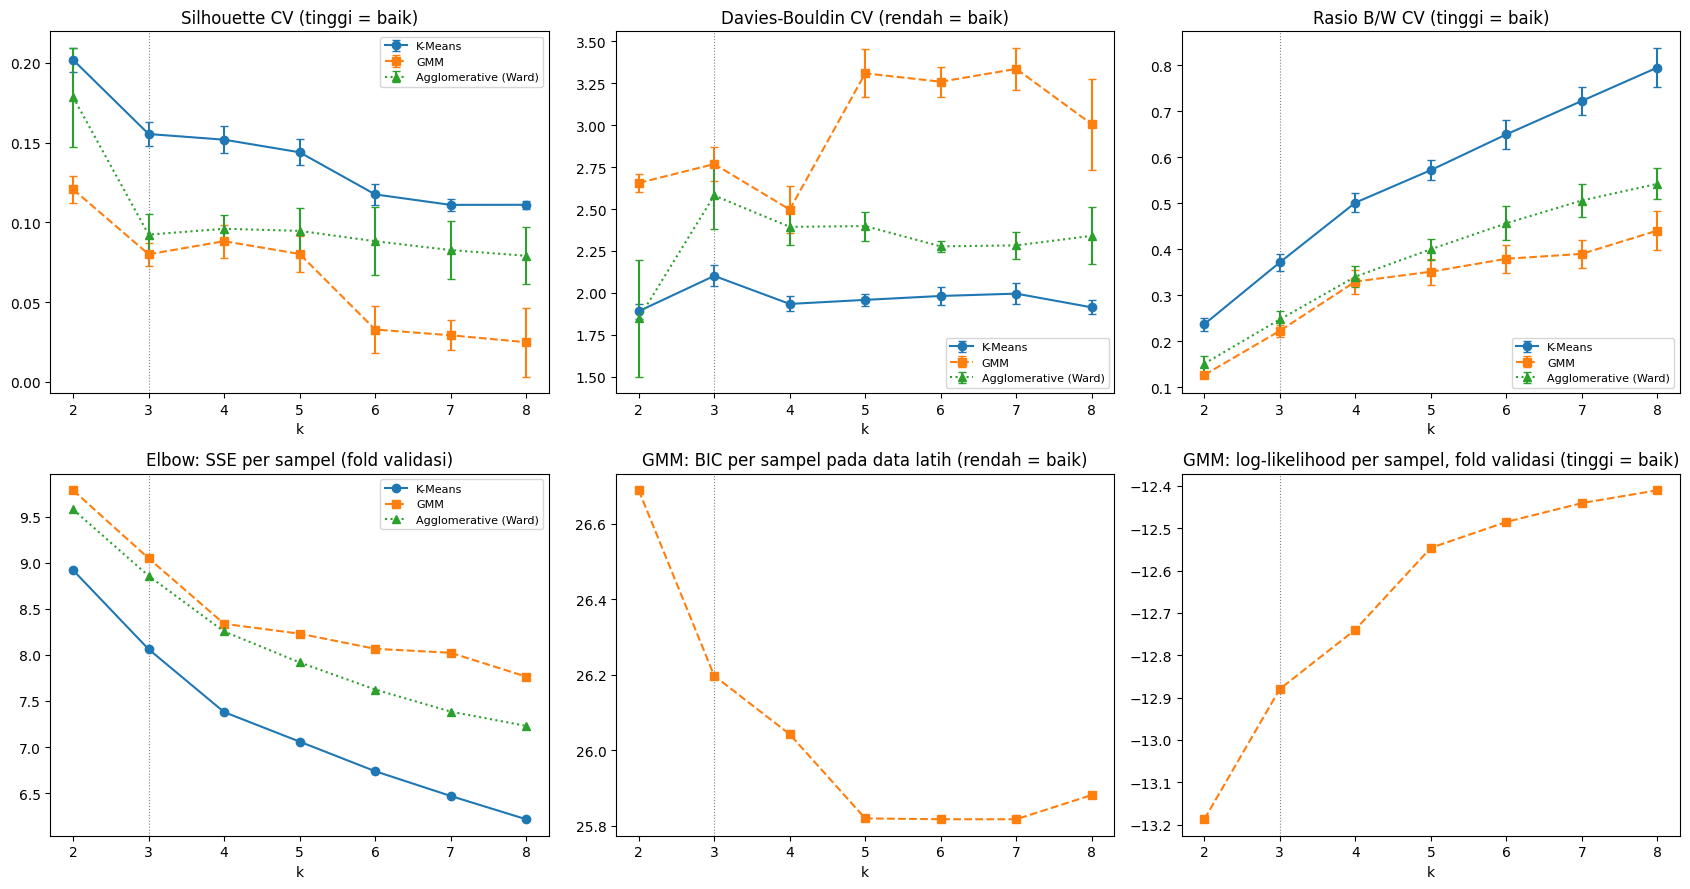

In [127]:
gaya = {"K-Means": ("o", "-"), "GMM": ("s", "--"), "Agglomerative (Ward)": ("^", ":")}

def garis(ax, kol, kol_sd, judul):
    for nama in MODEL_K:
        t = sapuan[nama]
        ax.errorbar(t.index, t[kol], yerr=t[kol_sd] if kol_sd else None, marker=gaya[nama][0], ls=gaya[nama][1],
                    capsize=3, label=nama)
    ax.axvline(K_BASELINE, color="gray", lw=0.8, ls=":")
    ax.set_xlabel("k")
    ax.set_title(judul)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
garis(axes[0, 0], "sil_rata2", "sil_std", "Silhouette CV (tinggi = baik)")
garis(axes[0, 1], "db_rata2", "db_std", "Davies-Bouldin CV (rendah = baik)")
garis(axes[0, 2], "bw_rata2", "bw_std", "Rasio B/W CV (tinggi = baik)")
garis(axes[1, 0], "sse_rata2", None, "Elbow: SSE per sampel (fold validasi)")
tg = sapuan["GMM"]
axes[1, 1].plot(tg.index, tg["bic"], marker="s", ls="--", color="tab:orange")
axes[1, 1].axvline(K_BASELINE, color="gray", lw=0.8, ls=":")
axes[1, 1].set_xlabel("k")
axes[1, 1].set_title("GMM: BIC per sampel pada data latih (rendah = baik)")
axes[1, 2].plot(tg.index, tg["ll_val"], marker="s", ls="--", color="tab:orange")
axes[1, 2].axvline(K_BASELINE, color="gray", lw=0.8, ls=":")
axes[1, 2].set_xlabel("k")
axes[1, 2].set_title("GMM: log-likelihood per sampel, fold validasi (tinggi = baik)")
plt.tight_layout()
plt.show()


### 7.4 Tabel ukuran cluster menurut k

Ukuran cluster pada **train penuh** (urut dari terbesar ke terkecil) untuk tiap (model, k). Kolom terakhir adalah porsi cluster terkecil; nilai yang sangat kecil menandakan cluster yang nyaris tidak berarti. Syarat 5% pada aturan pemilihan memakai rata-rata fold validasi (kolom `% cluster terkecil` di 7.2), bukan angka train ini.

In [128]:
baris = []
for nama, kelas in MODEL_K.items():
    for k in K_RENTANG:
        _, lab, _ = evaluasi_kandidat(lambda kelas=kelas, k=k: kelas(k=k))
        ukuran = lab.value_counts().sort_values(ascending=False)
        baris.append({"Model": nama, "k": k,
                      "Ukuran cluster (train, besar ke kecil)": ", ".join(str(int(v)) for v in ukuran.values),
                      "% cluster terkecil (train)": round(100 * ukuran.min() / ukuran.sum(), 1)})
tabel_ukuran = pd.DataFrame(baris).set_index(["Model", "k"])
print(tabel_ukuran.to_string())


                        Ukuran cluster (train, besar ke kecil)  % cluster terkecil (train)
Model                k                                                                    
K-Means              2                              2270, 1180                        34.2
                     3                          1460, 997, 993                        28.8
                     4                     1249, 813, 798, 590                        17.1
                     5                1199, 756, 630, 545, 320                         9.3
                     6            795, 737, 571, 524, 511, 312                         9.0
                     7       743, 670, 486, 478, 436, 337, 300                         8.7
                     8  675, 618, 480, 437, 381, 304, 285, 270                         7.8
GMM                  2                              1751, 1699                        49.2
                     3                        1224, 1201, 1025                        29.7

### 7.5 Grid kecil DBSCAN

DBSCAN tidak punya k, jadi yang diuji adalah `eps` dan `min_samples` pada grid **4 × 4 = 16 konfigurasi**. Tiap konfigurasi dijalankan di 5-fold CV yang sama, dengan preprocessing yang di-fit ulang pada tiap fold latih.

Ini **sapuan eksplorasi, bukan tuning**: grid sengaja kecil, ditetapkan sebelum melihat skor, dan tidak diperluas atau dihaluskan untuk mengejar skor tertinggi. Pertanyaannya hanya satu: *adakah pengaturan DBSCAN yang menemukan beberapa cluster yang cukup besar tanpa membuang terlalu banyak titik?* Perbandingannya setara dengan model lain karena data, fold, preprocessing, metrik, dan syarat ukuran cluster terkecil ≥ 5% sama; syarat tambahan noise ≤ 20% diperlukan karena silhouette DBSCAN membuang noise.

Tiga kolom tambahan membantu membaca hasil: `% titik tercakup` (100 − % noise), dua versi silhouette (**tanpa noise** dan **noise sebagai kelompok sendiri**, bila keduanya berjauhan maka membuang noise menguntungkan DBSCAN), dan `alasan tidak memenuhi syarat`.


In [129]:
cv_db = {}
for ms in MIN_SAMPLES_GRID:
    for q in EPS_PERSENTIL:
        cv_db[(ms, q)] = cv_kandidat(lambda ms=ms, q=q: DBSCANKandidat(eps_pct=q, min_samples=ms))

def layak_dbscan(cv):
    return bool(cv["n_cluster"].min() >= 2 and cv["% cluster terkecil"].mean() >= SYARAT_UKURAN_MIN
                and cv["% noise"].mean() <= SYARAT_NOISE_MAKS)

def alasan_tidak_layak(cv):
    a = []
    if cv["n_cluster"].min() < 2:
        a.append("< 2 cluster di sebagian fold")
    if not cv["% cluster terkecil"].mean() >= SYARAT_UKURAN_MIN:
        a.append("cluster terkecil < 5%")
    if cv["% noise"].mean() > SYARAT_NOISE_MAKS:
        a.append("noise > 20%")
    return "; ".join(a) if a else "-"

baris = []
for (ms, q), cv in cv_db.items():
    baris.append({"min_samples": ms, "eps = persentil ke-": q, "eps rata-rata": round(cv["eps"].mean(), 2),
                  "jumlah cluster": rentang_int(cv["n_cluster"]), "% noise": round(cv["% noise"].mean(), 1),
                  "% titik tercakup": round(100 - cv["% noise"].mean(), 1),
                  "% cluster terkecil": round(cv["% cluster terkecil"].mean(), 1),
                  "Silhouette (tanpa noise)": mean_sd(cv["silhouette"]),
                  "Silhouette (noise = kelompok)": mean_sd(cv["silhouette (noise = kelompok sendiri)"]),
                  "memenuhi syarat": "ya" if layak_dbscan(cv) else "tidak",
                  "alasan tidak memenuhi syarat": alasan_tidak_layak(cv)})
tabel_db = pd.DataFrame(baris).set_index(["min_samples", "eps = persentil ke-"])
print("Grid DBSCAN (5-fold CV, validation set):")
print(tabel_db.to_string())
n_layak = int((tabel_db["memenuhi syarat"] == "ya").sum())
n_multi = sum(int(cv["n_cluster"].min() >= 2) for cv in cv_db.values())
print(f"\nKonfigurasi yang memenuhi semua syarat : {n_layak} dari {len(cv_db)}")
print(f"Konfigurasi dengan >= 2 cluster di setiap fold : {n_multi} dari {len(cv_db)}")


Grid DBSCAN (5-fold CV, validation set):
                                 eps rata-rata jumlah cluster  % noise  % titik tercakup  % cluster terkecil Silhouette (tanpa noise) Silhouette (noise = kelompok) memenuhi syarat               alasan tidak memenuhi syarat
min_samples eps = persentil ke-                                                                                                                                                                                               
5           20                            1.24           6–11     72.8              27.2                 0.5            0.044 ± 0.041                -0.241 ± 0.033           tidak         cluster terkecil < 5%; noise > 20%
            40                            1.49            4–7     48.5              51.5                 0.3           -0.025 ± 0.051                -0.149 ± 0.047           tidak         cluster terkecil < 5%; noise > 20%
            60                            1.73            2–8     2

### 7.6 Memilih konfigurasi per model

Aturan di tabel keputusan diterapkan **lewat kode** pada hasil 7.2 dan 7.5, bukan dipilih manual.

**K-Means, GMM, Ward.** Konfigurasi terpilih (`KONFIG`) diambil dari **aturan utama** (silhouette tertinggi, lalu k terkecil dalam satu simpangan baku, di antara k yang lolos filter ukuran ≥ 5%). Sel berikut juga mencetak tabel **skor gabungan** sebagai **analisis eksploratif**, yaitu k yang akan dipilih bila komponen internal (siku SSE atau BIC) ikut dihitung, beserta k menurut tiap kriteria tunggal, agar terlihat seberapa searah kriterianya. Skor gabungan **tidak dipakai menentukan `KONFIG`**. **Kekuatan siku** = jarak kurva SSE ke garis lurus ujung ke ujung (kedua sumbu dinormalkan); nilainya 0 di ujung rentang, jadi k = 2 dan k = 8 tidak bisa menjadi siku. Ini kelemahan bawaan metode siku: komponen ini secara struktural merugikan k = 2.

**DBSCAN.** Aturan kelayakan di tabel keputusan diterapkan pada 16 konfigurasi di 7.5.

Hasilnya adalah `KONFIG`: konfigurasi terpilih tiap model, dipakai untuk 7.7 sampai 7.10. Baseline K-Means k = 3 tetap ikut sebagai pembanding.


In [130]:
def kekuatan_siku(k, sse):
    """Kekuatan siku tiap k: jarak kurva SSE (sumbu k dan SSE dinormalkan 0-1) ke garis lurus ujung ke ujung.
    Makin besar = tikungan makin tajam. Nilainya 0 di kedua ujung rentang."""
    k, sse = np.asarray(k, float), np.asarray(sse, float)
    x = (k - k[0]) / (k[-1] - k[0])
    y = (sse - sse[-1]) / (sse[0] - sse[-1])
    return pd.Series((1 - x) - y, index=k.astype(int))

def minmax(s):
    r = s.max() - s.min()
    return (s - s.min()) / r if r > 0 else s * 0 + 0.5

def tabel_gabungan(nama):
    """Komponen skor gabungan per k (hanya k yang lolos filter ukuran >= 5%), semuanya 0-1 dengan 1 = terbaik."""
    t = sapuan[nama]
    ks = t.index.astype(int)
    siku = kekuatan_siku(ks, t["sse_rata2"].values)            # dihitung pada seluruh rentang k
    ok = t["pct_terkecil"].values >= SYARAT_UKURAN_MIN
    ks_ok = ks[ok]
    d = pd.DataFrame(index=ks_ok)
    d.index.name = "k"
    d["silhouette ↑"] = minmax(pd.Series(t["sil_rata2"].values[ok], index=ks_ok))
    d["Davies-Bouldin ↓"] = minmax(-pd.Series(t["db_rata2"].values[ok], index=ks_ok))
    if "bic" in t:                                              # GMM: kriteria internal = BIC
        d["BIC ↓"] = minmax(-pd.Series(t["bic"].values[ok], index=ks_ok))
    else:                                                       # K-Means dan Ward: kriteria internal = siku SSE
        d["siku SSE ↑"] = minmax(siku.loc[ks_ok])
    d["skor gabungan"] = d.mean(axis=1)
    return d

def pilih_k(nama):
    t = sapuan[nama]
    d = tabel_gabungan(nama)
    if d.empty:
        return None
    layak = t[t["pct_terkecil"] >= SYARAT_UKURAN_MIN]
    # aturan utama (ditetapkan sebelum menjalankan): silhouette tertinggi, lalu k terkecil dalam 1 simpangan baku
    k_terbaik = int(layak["sil_rata2"].idxmax())
    batas = layak.loc[k_terbaik, "sil_rata2"] - layak.loc[k_terbaik, "sil_std"]
    k_lama = int(layak.index[layak["sil_rata2"] >= batas].min())
    kol_int = "BIC ↓" if "BIC ↓" in d else "siku SSE ↑"
    dua = d[["silhouette ↑", "Davies-Bouldin ↓"]].mean(axis=1)      # sensitivitas: tanpa komponen internal
    return {"k terpilih (aturan utama)": k_lama,
            "k eksploratif (skor gabungan)": int(d["skor gabungan"].idxmax()),     # seri -> k terkecil
            "k tanpa komponen internal (silhouette + DB)": int(dua.idxmax()),
            "k silhouette tertinggi": k_terbaik,
            "k Davies-Bouldin terendah": int(layak["db_rata2"].idxmin()),
            "k kriteria internal (siku atau BIC)": int(d[kol_int].idxmax()),
            "k layak (cluster terkecil >= 5%)": ",".join(str(int(x)) for x in d.index)}

for nama in MODEL_K:
    print(f"=== {nama}: skor gabungan per k (EKSPLORATIF; 0 sampai 1, 1 = terbaik di antara k yang layak) ===")
    print(tabel_gabungan(nama).round(3).to_string())
    print()

pilihan = {nama: pilih_k(nama) for nama in MODEL_K}
print("Ringkasan pemilihan k (kolom pertama = hasil aturan yang dipakai):")
print(pd.DataFrame(pilihan).T.to_string())

KONFIG = {"Baseline: K-Means (k=3)": (KMeansKontrol, {"k": K_BASELINE})}
CV_TERPILIH = {"Baseline: K-Means (k=3)": cv_k}
for nama, kelas in MODEL_K.items():
    if pilihan[nama] is None:
        print(f"\n{nama}: tidak ada k yang memenuhi syarat ukuran minimum.")
        continue
    k = pilihan[nama]["k terpilih (aturan utama)"]
    if nama == "K-Means" and k == K_BASELINE:
        print("\nK-Means: k terpilih sama dengan baseline (k = 3), jadi tidak ditambahkan baris baru.")
        continue
    KONFIG[f"{nama} (k={k})"] = (kelas, {"k": k})
    CV_TERPILIH[f"{nama} (k={k})"] = cv_sapuan[(nama, k)]

layak_db = {key: cv for key, cv in cv_db.items() if layak_dbscan(cv)}
if layak_db:
    key_db = max(layak_db, key=lambda key: layak_db[key]["silhouette"].mean())
    nama_db = f"DBSCAN (min_samples={key_db[0]}, eps=P{key_db[1]})"
    KONFIG[nama_db] = (DBSCANKandidat, {"eps_pct": key_db[1], "min_samples": key_db[0]})
    CV_TERPILIH[nama_db] = cv_db[key_db]
    print(f"\nDBSCAN terpilih: {nama_db}")
else:
    print(f"\nDBSCAN: tidak ada konfigurasi pada grid 4 x 4 yang memenuhi syarat (>= 2 cluster di tiap fold, cluster terkecil >= 5%, noise <= 20%).")
    print("        DBSCAN dilaporkan tanpa konfigurasi terpilih dan tidak ikut 7.7 sampai 7.10.")

print("\nKonfigurasi yang dibandingkan:", list(KONFIG))


=== K-Means: skor gabungan per k (EKSPLORATIF; 0 sampai 1, 1 = terbaik di antara k yang layak) ===
   silhouette ↑  Davies-Bouldin ↓  siku SSE ↑  skor gabungan
k                                                           
2         1.000             1.000       0.000          0.667
3         0.489             0.000       0.637          0.375
4         0.450             0.794       1.000          0.748
5         0.363             0.679       0.797          0.613
6         0.072             0.569       0.594          0.412
7         0.000             0.502       0.309          0.270
8         0.001             0.891       0.000          0.297

=== GMM: skor gabungan per k (EKSPLORATIF; 0 sampai 1, 1 = terbaik di antara k yang layak) ===
   silhouette ↑  Davies-Bouldin ↓  BIC ↓  skor gabungan
k                                                      
2         1.000             0.811  0.000          0.604
3         0.576             0.677  0.564          0.605
4         0.661             1.00

### 7.7 Perbandingan konfigurasi terpilih dengan baseline

Tabel yang sama dengan 6.5, kini untuk konfigurasi terpilih. Angkanya adalah hasil fold validasi (validation set); **data test tidak dipakai untuk memilih atau mengevaluasi model**. Tabel per fold (kelima metrik, format materi: Fold 1 sampai 5, rata-rata, standar deviasi) dan selisih berpasangan terhadap baseline dihitung per fold. Tabel per fold disimpan ke `sapuan_perfold.csv`.


In [131]:
tabel_terpilih = tabel_cv(CV_TERPILIH)
tabel_terpilih.to_csv("sapuan_perbandingan.csv")
tabel_angka(CV_TERPILIH).to_csv("sapuan_perbandingan_angka.csv")
print("Konfigurasi terpilih vs baseline (5-fold CV; (*) SSE hanya ditampilkan, tidak dipakai menilai):\n")
print(tabel_terpilih.T.to_string())

cetak_per_fold(CV_TERPILIH, simpan="sapuan_perfold.csv")

for lab, kol in [("Silhouette ↑", "silhouette"), ("Davies-Bouldin ↓", "davies_bouldin")]:
    print(f"\n=== Selisih {lab} per fold terhadap baseline (konfigurasi - baseline) ===")
    print(selisih_berpasangan(CV_TERPILIH, kol).to_string())


Konfigurasi terpilih vs baseline (5-fold CV; (*) SSE hanya ditampilkan, tidak dipakai menilai):

Model                Baseline: K-Means (k=3)  K-Means (k=2)       GMM (k=2) Agglomerative (Ward) (k=2)
Silhouette ↑                   0.155 ± 0.008  0.202 ± 0.007   0.121 ± 0.008              0.178 ± 0.031
% silhouette < 0 ↓            10.522 ± 1.327  4.058 ± 1.390  28.290 ± 0.627             13.014 ± 3.416
Davies-Bouldin ↓               2.101 ± 0.063  1.891 ± 0.044   2.656 ± 0.053              1.848 ± 0.348
Rasio B/W ↑                    0.371 ± 0.018  0.237 ± 0.015   0.126 ± 0.004              0.151 ± 0.018
SSE per sampel ↓ (*)           8.061 ± 0.254  8.918 ± 0.293   9.785 ± 0.403              9.576 ± 0.418
Jumlah cluster                             3              2               2                          2
% noise                                  0.0            0.0             0.0                        0.0

=== Silhouette ↑: skor per fold ===
                           Fold 1 Fold 2 F

### 7.8 Pemeriksaan: apakah aturan penugasan titik baru memengaruhi hasil?

Fold validasi diberi label dengan aturan bawaan tiap model (6.2), dan aturan itu berbeda antar-model. Pemeriksaan ini dijalankan **satu kali, hanya untuk konfigurasi terpilih**: semua model diberi label fold validasi dengan satu aturan yang sama, yaitu **1-NN ke titik latih** (aturan netral yang tidak memaksakan bentuk batas cluster tertentu). Bila urutan model dan ukuran selisihnya serupa pada kedua aturan, hasil tidak sekadar artefak aturan penugasan. Ini bukan skenario tambahan untuk dipilih-pilih; hanya uji ketahanan. Data test tidak dipakai.

In [132]:
def cv_1nn(kelas, kw):
    """Silhouette fold validasi bila label fold validasi diberi lewat 1-NN ke titik latih (aturan sama untuk semua model)."""
    nilai = []
    for f in range(N_FOLD):
        i_va = fold_id.index[fold_id == f]
        i_tr = fold_id.index[fold_id != f]
        pp_f = buat_praproses().fit(X_pre.loc[i_tr], meta)
        Xtr, Xva = pp_f.transform(X_pre.loc[i_tr], meta).values, pp_f.transform(X_pre.loc[i_va], meta).values
        m = kelas(**kw).fit(Xtr)
        lab_tr = np.asarray(m.labels_)
        lab_va = lab_tr[NearestNeighbors(n_neighbors=1).fit(Xtr).kneighbors(Xva)[1][:, 0]]
        nilai.append(metrik_kandidat(Xva, lab_va, Xtr, lab_tr)["silhouette"])
    return pd.Series(nilai, index=range(N_FOLD))

cv_nn = {nama: cv_1nn(kelas, kw) for nama, (kelas, kw) in KONFIG.items()}
acuan = "Baseline: K-Means (k=3)"
baris = {}
for nama in KONFIG:
    asli = CV_TERPILIH[nama]["silhouette"]
    baris[nama] = {"Silhouette CV (aturan bawaan)": mean_sd(asli),
                   "Silhouette CV (1-NN untuk semua)": mean_sd(cv_nn[nama]),
                   "Δ vs baseline (bawaan)": "-" if nama == acuan else f"{asli.mean() - CV_TERPILIH[acuan]['silhouette'].mean():+.3f}",
                   "Δ vs baseline (1-NN)": "-" if nama == acuan else f"{cv_nn[nama].mean() - cv_nn[acuan].mean():+.3f}"}
print(pd.DataFrame(baris).T.to_string())


                           Silhouette CV (aturan bawaan) Silhouette CV (1-NN untuk semua) Δ vs baseline (bawaan) Δ vs baseline (1-NN)
Baseline: K-Means (k=3)                    0.155 ± 0.008                    0.142 ± 0.008                      -                    -
K-Means (k=2)                              0.202 ± 0.007                    0.193 ± 0.008                 +0.046               +0.050
GMM (k=2)                                  0.121 ± 0.008                    0.128 ± 0.004                 -0.035               -0.014
Agglomerative (Ward) (k=2)                 0.178 ± 0.031                    0.178 ± 0.031                 +0.023               +0.036


### 7.9 Kestabilan hasil clustering

Dua pemeriksaan, memakai **data train saja**, dengan prosedur yang sama untuk semua konfigurasi terpilih (dan baseline). Ukurannya **Adjusted Rand Index (ARI)** terhadap partisi acuan, yaitu model yang dilatih pada train penuh (1 = partisi identik, 0 = setara acak):

1. **Seed berbeda** (20 seed). Hanya untuk model yang punya inisialisasi acak (K-Means dan GMM). Ward dan DBSCAN deterministik, jadi seed tidak relevan.
2. **Subsampel 80% dari train** (20 kali), lalu seluruh train diberi label dengan model itu (aturan penugasan bawaan model). Kolom tambahan melaporkan rentang ukuran cluster terkecil pada subsampel: bila rentangnya lebar, pemotongannya berubah-ubah.

Ini melengkapi CV: CV menguji **skor** pada data yang tidak dipakai melatih, sedangkan ARI menguji apakah **partisinya sendiri** dapat diulang. Pada baseline hasilnya harus sama dengan 5.5. Stabilitas tidak membuktikan adanya kelompok alami; ia hanya menunjukkan pemotongan yang konsisten.

In [133]:
SEED_MODEL = (KMeansKontrol, GMMKandidat)

def stabilitas_model(kelas, kw):
    ref = kelas(**kw).fit(X_train_s)
    lab_ref = np.asarray(ref.labels_)
    ari_seed_ = []
    if kelas in SEED_MODEL:
        for s in range(1000, 1020):
            m = kelas(**kw, seed=s).fit(X_train_s)
            ari_seed_.append(adjusted_rand_score(lab_ref, np.asarray(m.labels_)))
    rng_ = np.random.default_rng(SEED)
    ari_sub_, kecil_sub_ = [], []
    for _ in range(20):
        pilih = rng_.choice(len(X_train_s), size=int(0.8 * len(X_train_s)), replace=False)
        m = kelas(**kw).fit(X_train_s.iloc[pilih])
        ari_sub_.append(adjusted_rand_score(lab_ref, np.asarray(m.predict(X_train_s))))
        lab_sub = np.asarray(m.labels_)
        lab_sub = lab_sub[lab_sub != -1]
        kecil_sub_.append(100 * np.unique(lab_sub, return_counts=True)[1].min() / len(lab_sub))   # % cluster terkecil pada subsampel
    return ref, ari_seed_, ari_sub_, kecil_sub_

model_terpilih, baris = {}, {}
for nama, (kelas, kw) in KONFIG.items():
    ref, a_seed, a_sub, a_kecil = stabilitas_model(kelas, kw)
    model_terpilih[nama] = ref
    baris[nama] = {"ARI seed: rata-rata": f"{np.mean(a_seed):.3f}" if a_seed else "tidak relevan (deterministik)",
                   "ARI seed: minimum": f"{np.min(a_seed):.3f}" if a_seed else "-",
                   "ARI subsampel 80%: rata-rata": f"{np.mean(a_sub):.3f}",
                   "ARI subsampel 80%: minimum": f"{np.min(a_sub):.3f}",
                   "% cluster terkecil pada subsampel (min–maks)": f"{np.min(a_kecil):.1f} – {np.max(a_kecil):.1f}"}
    if nama == "Baseline: K-Means (k=3)":      # harus sama dengan 5.5
        assert np.isclose(np.mean(a_seed), np.mean(ari_seed), atol=1e-6) and np.isclose(np.mean(a_sub), np.mean(ari_sub), atol=1e-6)
print(pd.DataFrame(baris).T.to_string())


                                      ARI seed: rata-rata ARI seed: minimum ARI subsampel 80%: rata-rata ARI subsampel 80%: minimum % cluster terkecil pada subsampel (min–maks)
Baseline: K-Means (k=3)                             0.987             0.957                        0.934                      0.861                                  24.6 – 28.8
K-Means (k=2)                                       0.988             0.974                        0.975                      0.925                                  33.2 – 36.7
GMM (k=2)                                           1.000             0.999                        0.951                      0.747                                  44.7 – 50.0
Agglomerative (Ward) (k=2)  tidak relevan (deterministik)                 -                        0.382                      0.055                                  11.7 – 44.8


### 7.10 Ukuran dan profil cluster konfigurasi terpilih

Semua tabel di bawah dibuat **dengan kode** dari data train: ukuran cluster, centroid (rata-rata z-score), median fitur dalam satuan asli, dan kesesuaian dengan variabel penjelas (AMI, seperti 5.7). Yang tidak bisa dilakukan kode adalah **menafsirkan** (memberi arti pada cluster); itu dikerjakan dengan membaca tabel dan grafiknya. Profil dibuat hanya untuk konfigurasi terpilih, bukan untuk setiap k.

In [134]:
lab_pilih = {nama: urut_ukuran(pd.Series(np.asarray(m.labels_), index=X_train_s.index)) for nama, m in model_terpilih.items()}

for nama, lab in lab_pilih.items():
    ada = lab != -1
    ukuran = lab.value_counts().sort_index()
    print(f"\n==================== {nama} ====================")
    print("Ukuran cluster (train):")
    print(pd.DataFrame({"n": ukuran, "persen": (100 * ukuran / ukuran.sum()).round(1)}).to_string())
    print("\nCentroid (rata-rata z-score) per cluster:")
    print(X_train_s[ada].groupby(lab[ada]).mean().round(2).to_string())
    med = X_train_imp[ada].groupby(lab[ada]).median()
    med["csor_share"] = (X_train_imp["csor"] / (X_train_imp["cres"] + X_train_imp["csor"]))[ada].groupby(lab[ada]).median()
    med["pop"] = dfp.loc[lab[ada].index, "pop"].astype(float).groupby(lab[ada]).median()
    print("\nMedian fitur per cluster (satuan asli, setelah imputasi):")
    print(med.round(2).to_string())

# AMI dengan variabel penjelas (daftar variabel `kandidat` dari 5.7)
ami_pilih = {}
for nama, lab in lab_pilih.items():
    if lab[lab != -1].nunique() < 2:
        continue
    r = {}
    for v in kandidat:
        ada = profil_tr[v].notna()
        r[v] = adjusted_mutual_info_score(profil_tr.loc[ada, v].astype(str), lab[ada])
    ami_pilih[nama] = r
print("\nAMI antara cluster dan variabel penjelas (train; bukan ground truth):")
print(pd.DataFrame(ami_pilih).round(3).to_string())



==================== Baseline: K-Means (k=3) ====================
Ukuran cluster (train):
      n  persen
0  1460    42.3
1   997    28.9
2   993    28.8

Centroid (rata-rata z-score) per cluster:
     tc  cres  csor  msw_pc   sor  organic  paper  glass  plastic  metal  other
0 -0.51 -0.61 -0.05    0.19  0.64     0.25   0.39  -0.07    -0.02   0.58   0.70
1  0.77  0.91 -0.12    0.51 -1.06    -0.84  -0.55  -0.57    -0.59  -0.55  -0.43
2 -0.02 -0.03  0.20   -0.78  0.13     0.47  -0.01   0.67     0.63  -0.30  -0.60

Median fitur per cluster (satuan asli, setelah imputasi):
       tc   cres   csor  msw_pc    sor  organic  paper  glass  plastic  metal  other  csor_share     pop
0  115.54  28.99  47.09  454.22  78.65    27.55  12.21   9.07     5.94   2.18  11.08        0.62  4528.0
1  185.32  74.44  44.53  498.34  49.37     9.67   8.71   6.99     4.15   0.90   5.12        0.38  4577.0
2  139.79  42.09  55.87  334.89  70.08    29.15  10.78  11.40     7.38   1.16   4.35        0.59  2275.0

==

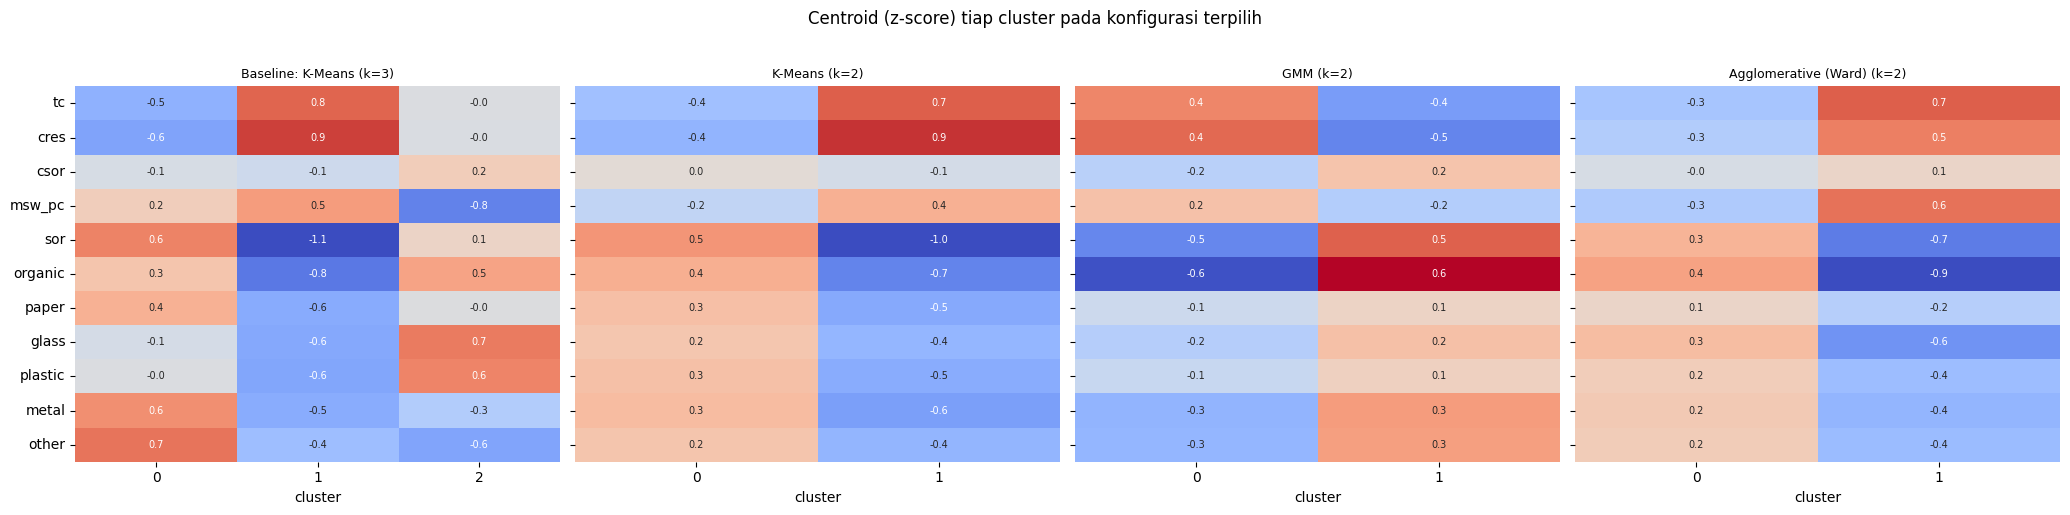

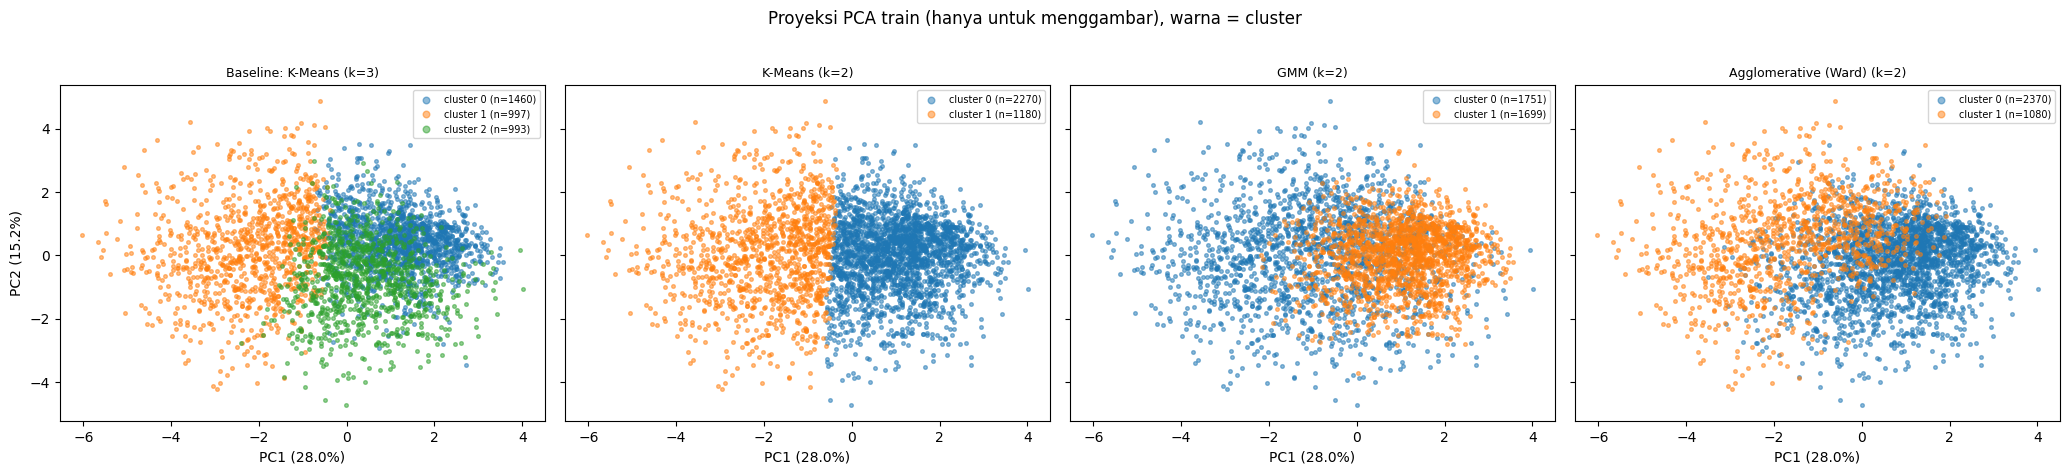

In [135]:
n_model = len(lab_pilih)
fig, axes = plt.subplots(1, n_model, figsize=(5.2 * n_model, 5), sharey=True)
axes = np.atleast_1d(axes)
for ax, (nama, lab) in zip(axes, lab_pilih.items()):
    ada = lab != -1
    cen = X_train_s[ada].groupby(lab[ada]).mean()
    sns.heatmap(cen.T, cmap="coolwarm", center=0, annot=True, fmt=".1f", ax=ax, cbar=False, annot_kws={"fontsize": 7})
    ax.set_title(nama, fontsize=9)
    ax.set_xlabel("cluster")
plt.suptitle("Centroid (z-score) tiap cluster pada konfigurasi terpilih", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, n_model, figsize=(5.2 * n_model, 4.6), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, (nama, lab) in zip(axes, lab_pilih.items()):
    noise = lab.values == -1
    if noise.any():
        ax.scatter(P_train.loc[noise, "PC1"], P_train.loc[noise, "PC2"], s=18, color="black", marker="x", linewidths=0.8, label=f"noise (n={noise.sum()})", zorder=4)
    for c in sorted(set(lab.values) - {-1}):
        m_ = lab.values == c
        ax.scatter(P_train.loc[m_, "PC1"], P_train.loc[m_, "PC2"], s=7, alpha=0.5, color=sns.color_palette("tab10")[c % 10], label=f"cluster {c} (n={m_.sum()})")
    ax.set_title(nama, fontsize=9)
    ax.set_xlabel(f"PC1 ({ve[0]:.1%})")
    ax.legend(markerscale=1.8, fontsize=7)
axes[0].set_ylabel(f"PC2 ({ve[1]:.1%})")
plt.suptitle("Proyeksi PCA train (hanya untuk menggambar), warna = cluster", y=1.02)
plt.tight_layout()
plt.show()


### 7.11 Temuan sapuan

> Angka di bawah berasal dari eksekusi dengan `SEED = 42` (scikit-learn 1.9). Jika versi library berbeda dan keluaran sel di atas sedikit berbeda, sesuaikan angkanya; kesimpulannya bergantung pada keluaran sel, bukan pada teks ini. **Semua angka berasal dari train dan fold validasi; data test belum dipakai untuk memilih atau mengevaluasi model.**

**Sapuan k (K-Means, GMM, Agglomerative)**

- **Aturan utama (ditetapkan sebelum menjalankan) memilih k = 2 untuk ketiga model** (K-Means 0,202 ± 0,007; Ward 0,178 ± 0,031; GMM 0,121 ± 0,008). Ini sebagian sifat metrik (membelah data menjadi dua bagian paling mudah), bukan bukti bahwa data punya dua kelompok alami.
- **Analisis eksploratif (skor gabungan, ditambahkan setelah melihat hasil di atas)** memilih k = 4 untuk K-Means (skor 0,748 vs 0,667 pada k = 2; selisih kecil) dan GMM (0,801 vs 0,605), dan k = 2 untuk Ward. Pilihan k = 4 bergantung pada komponen internal (siku SSE atau BIC): tanpa komponen itu ketiga model kembali memilih k = 2. Komponen siku bernilai 0 di ujung rentang, jadi k = 2 tidak mungkin menang di komponen itu. Hasil ini hanya sensitivitas dan **tidak menggantikan aturan utama**.
- **Kriteria lain tidak searah.** Davies-Bouldin terendah di k = 2 untuk K-Means dan Ward, tetapi di k = 4 untuk GMM (2,497 vs 2,656 pada k = 2). **Rasio B/W naik terus seiring k** (K-Means dan GMM sampai k = 8); ini sifat rumusnya, bukan sinyal struktur, jadi hanya layak membandingkan model pada k yang sama. Elbow K-Means lemah (tikungan samar di sekitar k = 4). BIC GMM paling rendah di sekitar k = 6 sampai 7 dan log-likelihood validasi terus naik sampai k = 8.
- **Ukuran cluster.** Ward tidak layak dari k = 6 ke atas (cluster terkecil rata-rata fold validasi 3,2%). K-Means dan GMM layak di semua k, tetapi K-Means memiliki cluster di bawah 10% mulai k = 5 (lihat tabel 7.4).

**Grid DBSCAN (4 × 4 = 16 konfigurasi)**

- **Tidak ada konfigurasi yang memenuhi syarat (0 dari 16).** Grid memakai persentil `eps` 20 sampai 80 dan `min_samples` 5, 11, 22, 44.
- **Pola yang terlihat:** pada `eps` kecil DBSCAN memang menemukan beberapa cluster (empat konfigurasi punya ≥ 2 cluster di setiap fold), tetapi cluster itu hanya berisi 0,2% sampai 1,2% titik dan 27% sampai 73% titik dibuang sebagai noise. Pada eps yang lebih besar, sebagian besar konfigurasi cenderung menyatukan titik menjadi satu cluster atau tidak lagi menghasilkan beberapa cluster secara konsisten. Pola ini terutama terlihat pada konfigurasi dengan min_samples lebih besar. Tidak ada celah kepadatan yang memisahkan kelompok berukuran berarti, konsisten dengan 6.8.
- **Silhouette DBSCAN tidak boleh dibaca sebagai lebih baik.** Contohnya `min_samples = 11` dengan `eps` persentil 20 memberi silhouette tanpa noise 0,225 ± 0,115, tetapi hanya mencakup 35,1% titik dan cluster terkecilnya 1,2%. Silhouette dengan noise sebagai kelompok sendiri berkisar −0,24 sampai 0,28 dan umumnya naik ketika noise makin sedikit, karena hanya memisahkan pencilan dari satu gumpalan besar.
- **Perbandingan setara:** data, fold, preprocessing, metrik, dan syarat ukuran cluster terkecil ≥ 5% sama dengan model lain. Karena tidak ada konfigurasi layak, DBSCAN dilaporkan tanpa konfigurasi terpilih dan tidak ikut 7.7 sampai 7.10. Kesimpulan ini hanya berlaku untuk grid kecil ini dan jarak Euclidean pada 11 fitur; tidak membuktikan bahwa data tanpa struktur kepadatan.

**Konfigurasi terpilih (aturan utama) vs baseline (5-fold CV)**

| Model | Silhouette ↑ | % silhouette < 0 ↓ | Davies-Bouldin ↓ | Rasio B/W ↑ |
|---|---|---|---|---|
| Baseline: K-Means (k=3) | 0,155 ± 0,008 | 10,5 ± 1,3 | 2,101 ± 0,063 | 0,371 ± 0,018 |
| K-Means (k=2) | 0,202 ± 0,007 | 4,1 ± 1,4 | 1,891 ± 0,044 | 0,237 ± 0,015 |
| GMM (k=2) | 0,121 ± 0,008 | 28,3 ± 0,6 | 2,656 ± 0,053 | 0,126 ± 0,004 |
| Agglomerative Ward (k=2) | 0,178 ± 0,031 | 13,0 ± 3,4 | 1,848 ± 0,348 | 0,151 ± 0,018 |

- **K-Means k = 2** lebih tinggi dari baseline di kelima fold (selisih silhouette +0,045 sampai +0,050, rata-rata +0,046). **GMM k = 2** lebih rendah di kelima fold (−0,026 sampai −0,042, rata-rata −0,035). **Ward k = 2** campuran (+0,064 sampai −0,020, rata-rata +0,023, simpangan baku 0,030), jadi tidak bisa dibedakan dari derau.
- **Membandingkan k = 2 dengan k = 3 memakai silhouette tidak sepenuhnya setara**, karena k kecil diuntungkan. Rasio B/W baseline yang lebih tinggi (0,371 vs 0,237) pun sebagian hanya karena k-nya lebih besar.

**Pengaruh aturan penugasan titik baru (7.8)**

- Urutan model sama pada kedua aturan: K-Means k = 2 > Ward k = 2 > baseline > GMM k = 2. Kesimpulan arah bertahan.
- **Besar selisih bergantung pada aturan.** Selisih GMM k = 2 terhadap baseline menyusut dari −0,035 (aturan bawaan) menjadi −0,014 (1-NN untuk semua), yaitu di bawah pedoman derau 0,02. Jadi pada aturan yang netral, GMM k = 2 hampir setara baseline. Selisih K-Means k = 2 relatif tetap (+0,046 menjadi +0,050).

**Kestabilan (train, 7.9)**

- **K-Means k = 2 sangat stabil**: ARI antar-seed 0,988 (minimum 0,974) dan antar-subsampel 0,975 (minimum 0,925), lebih stabil daripada baseline k = 3 (0,987 / 0,957 dan 0,934 / 0,861).
- **GMM k = 2** stabil terhadap seed (1,000; minimum 0,999) tetapi subsampel kadang berbeda cukup jauh (rata-rata 0,951; minimum 0,747).
- **Ward k = 2 tidak stabil**: ARI subsampel rata-rata hanya 0,382 (minimum 0,055), dan porsi cluster terkecilnya berubah antara 11,7% dan 44,8% pada subsampel yang berbeda. Simpangan baku silhouette antar-fold juga terbesar (0,031). Skor silhouette 0,178 tidak menjamin partisi yang bisa diulang.

**Profil cluster (train, 7.10)**

- **K-Means k = 2**: cluster 0 (65,8%) memiliki pemilahan tinggi (`sor` median 76,4%) dan biaya rendah (`tc` 120,6 EUR); cluster 1 (34,2%) memiliki pemilahan rendah (`sor` 52,0%), biaya tinggi (`tc` 180,5 EUR; `cres` 72,7), dan porsi organik rendah (11,7%). Ini adalah sumbu "biaya tinggi dan pemilahan rendah" lawan sebaliknya yang sama dengan gradien utama pada k = 3; profil kota kecil pada k = 3 (cluster 2, median penduduk 2.275) lebur ke dalam kedua kelompok ini.
- **Ward k = 2**: dua kelompok "biaya rendah dan pemilahan tinggi" (68,7%) lawan sebaliknya (31,3%), sumbu yang sama dengan gradien utama pada baseline. AMI terhadap `geo` hanya 0,022.
- AMI terhadap `geo` turun dari 0,185 (k = 3) menjadi 0,047 (K-Means k = 2), jadi pemisahan k = 2 memotong lintas wilayah, bukan sekadar Utara lawan Selatan. Seperti sebelumnya, AMI kecil dan bukan ground truth.

**Batasan**

- Aturan utama memakai silhouette, yang condong ke k kecil dan ke batas cluster lurus; B/W naik mekanis dengan k; SSE condong ke K-Means. Hasil ini adalah tolok ukur geometris, belum menjawab apakah cluster berguna secara substantif.
- Skor gabungan dirumuskan setelah melihat hasil aturan utama, memakai bobot sama, dan sensitif terhadap komponen internal. Ia hanya analisis eksploratif.
- GMM hanya diuji dengan `covariance_type='full'`, dan DBSCAN hanya pada grid 4 × 4. Hyperparameter lain tidak disapu sesuai ketentuan tugas.
- Lima fold bukan uji statistik; selisih yang kecil (kurang dari sekitar 0,02) tidak dibaca sebagai perbedaan nyata.

**Yang dibawa ke tahap berikutnya**

1. Menentukan model dan konfigurasi akhir secara terbuka. Aturan utama memilih k = 2 untuk ketiga model, tetapi k = 2 diuntungkan metrik, sedangkan baseline k = 3 punya dasar a priori dan profil yang lebih kaya. K-Means k = 4 dari analisis eksploratif bisa dipertimbangkan, dengan catatan bahwa ia belum diuji lengkap di 7.7 sampai 7.10. Keputusan sebaiknya mempertimbangkan kestabilan dan tafsiran, bukan hanya skor.
2. **Evaluasi pada data test dilakukan satu kali saja**, hanya untuk model terpilih akhir (dan baseline sebagai acuan), karena test belum dipakai untuk memilih atau mengevaluasi model di bagian mana pun.